# COMET — Unpaired scRNA + scATAC Trajectory Inference
**Goal:** Recover directionality and TF mechanisms (GRN) of hematopoietic trajectories using unpaired scRNA-seq and scATAC-seq, without using pseudotime, root cells, or RNA splicing. Directionality emerges from **atom-boundary flow consistency**: the GRN learns discrete cell-state programs (atoms), ATAC accessibility identifies which atom is downstream (primed but not yet expressed), and the velocity field is trained to follow those atom boundaries in the correct direction.

**Key constraint:** Do not use pseudotime, root cells, or splicing in any part of training. The velocity direction must emerge purely from the GRN atom structure and chromatin accessibility.

---

## Diagnosis (2026-06-24) — Why the velocity field breaks in the top half, and the one-line principled fix

**Symptom.** Pseudotime is excellent. The scalar field ψ is exactly what we expect.
The GRN atoms and the origin call (atom 1) are correct. But the displacement /
velocity field is wrong — specifically, the *bottom half* of the streamline plot
(the origin blob and the start of each branch) is right, while the *top half*
(the committed branch territory) is noise: arrows stall, swirl, and converge onto
a spurious sink partway up the right branch.

**The user's intuition is correct and is the key to the fix:** *"if pseudotime is
correct and the scalar field is correct, the velocity field should be correct too."*
It should — but only if we differentiate the **right** scalar.

### Root cause: we are differentiating a *saturating* potential

The velocity field is gradient ascent on its potential:

```
V[i] = Σ_j ReLU(potential[j] − potential[i]) · (X_2d[j] − X_2d[i])
```

Today `potential = ψ`. But ψ is, *by deliberate design*, a **two-level saturating
field**: `P[origin] = −1`, `P[every committed branch] = +1`
(`W3_FINE_ORDER = 0` keeps all branches at the same height on purpose). So:

- A cell in the **origin→branch transition** still carries some `mix_w[origin]`,
  so its ψ varies from ≈ −0.6 up to ≈ +0.8. There is a real gradient here →
  the **bottom half is correct**.
- A cell **deep in a committed branch** has `mix_w[origin] ≈ 0` and all its weight
  on branch atoms, so `ψ ≈ +1` for the *entire rest of the branch*. ψ has
  **saturated**. `ψ(j) − ψ(i) ≈ 0` for every neighbour → the ReLU kernel sees
  only noise → arrows are random and the smoothing pulls them into spurious
  sinks. This is the **broken top half**, and it is the same plateau everywhere
  in mature territory regardless of dataset.

**ψ is not broken.** It is doing exactly its job (ordering origin below branches).
The mistake is asking its *pointwise gradient* to drive velocity through a region
where it is intentionally flat. **You cannot recover a flow by differentiating a
plateau.**

### Why pseudotime φ doesn't have this problem — and is the potential we actually want

Pseudotime φ is the **Dijkstra geodesic distance from the root on the ψ-uphill
graph**. It is the *integral* of the local ψ-ordering along the shortest path, not
a pointwise read of ψ. Integration accumulates even an infinitesimal, noisy local
gradient into a **globally monotone field that keeps rising all the way to every
branch tip**. That is precisely why image 2 (pseudotime) looks smooth and correct
out to the tips while image 1 (ψ) saturates. φ is, in effect, the eikonal/geodesic
*solution* whose gradient is the de-noised version of the noisy field ∇ψ.

### The fix (mathematically trivial, fully principled)

**Differentiate φ, not ψ.** Build the velocity field as gradient ascent on the
geodesic pseudotime:

```
V[i] = Σ_j ReLU(φ[j] − φ[i]) · (X_2d[j] − X_2d[i])
```

Because φ is monotone from the root to every tip, ∇φ is well-defined **everywhere**
— bottom *and* top. Concretely this is three changes, none of which touch ψ, the
GRN, the mixing weights, or Phase 1/2/3 training:

1. Compute φ (the geodesic pseudotime) **before** the velocity field, using the
   ordering ψ already provides (`compute_geodesic_pseudotime`).
2. Feed φ — not ψ — as the `potential` argument to `compute_markov_velocity_2d`.
3. Make φ **gap-free**: cells the strict ψ(j)>ψ(i) rule leaves unreachable in
   flat-ψ zones are relaxed outward (`min finite-neighbour φ + ε`) instead of all
   clamped to one max value, so the tips don't become a *new* zero-gradient
   plateau. (This also slightly smooths the pseudotime tips — a strict
   improvement, visually near-identical.)

### Why this is the right fix, not a hack

- **It generalises to any dataset and any branching number.** Dijkstra recovers
  whatever branch structure exists; φ is monotone along each branch it finds, so
  ∇φ is a valid flow for 1, 2, 3, … branches *or* a non-branching trajectory.
  Nothing assumes hematopoiesis or "3 branches."
- **It respects the constraint.** φ is a *post-training* function of ψ, which
  emerged from GRN + ATAC. No pseudotime/root/splicing label enters training, and
  the velocity *direction* still derives from ψ's ordering. Roots are simply the
  lowest-ψ cells, which ψ guarantees to be the origin atom.
- **It makes the three outputs exactly consistent.** After the fix, velocity =
  ∇φ = ∇(pseudotime). The arrows literally point up the pseudotime gradient — the
  user's intuition becomes an identity, not a coincidence.
- **It is more robust to the 2D-kNN lineage-crossing issue (old "Reason 2").**
  A cross-lineage 2D neighbour sits at similar φ, so `ReLU(φ[j]−φ[i]) ≈ 0` and it
  is automatically down-weighted. ψ's plateau had removed that protection by
  zeroing *all* weights; φ restores it.

> **What we explicitly did NOT do:** we did not enable within-branch ψ ordering
> (`W3_FINE_ORDER`). That was correctly disabled — inter-branch discordance is
> noise and forcing a within-membership ordering reintroduces cross-branch arrows.
> The within-branch progression signal does not live in the *membership* potential
> at all; it lives in the *geometry* of the manifold, which the geodesic φ is the
> correct object to read it from.

---

## Diagnosis (2026-06-25) — Why the velocity field breaks in PCA space (and not Decipher), and three targeted fixes

**Symptom.** When `DISPLACEMENT_SPACE = "pca"`, the scalar field ψ shows almost no gradient (Image 3: ψ_origin=0.827 vs ψ_branches≈1.00, range only 0.17), the pseudotime is scattered noise (Image 2: root cells appear mid-cloud, not at HSC/MPP), and the streamlines are incoherent (Image 1: arrows diverge from the origin and form random eddies). The Decipher run is correct on all three counts. The GRN, Phase 1/2 training, and mix_weights are shared — nothing biological changed — so the failures must be in the PCA-specific post-processing.

### Root cause 1 — ψ smoothing kills the gradient in PCA space

`graph_smooth` averages each cell's ψ with `N_PSI_SMOOTH_HOPS=3` rounds of nearest-neighbor averaging. In Decipher mode the neighbor graph is built on Decipher's 10D latent Z, which closely tracks biological state — averaging with latent-space neighbors actually *sharpens* the signal. In PCA mode the neighbor graph is built on 15-dimensional PC space, which is noisier; three rounds of averaging on this noisier graph homogenise ψ until the already-narrow origin-vs-branch gap (~0.17) collapses further.

**Fix:** Override `N_PSI_SMOOTH_HOPS → PCA_PSI_SMOOTH_HOPS = 1` in PCA mode. One hop is enough to remove single-cell noise without destroying the gradient. Decipher mode stays at 3 hops.

### Root cause 2 — Dijkstra cost formula (two wrong attempts, now definitively fixed)

The edge cost in `compute_geodesic_pseudotime` controls what pseudotime means.

**Attempt 1 (original): `cost = ψ_climb / dist(i,j)`** — a "slope" metric. In Decipher mode ψ range ≈ 2.0, so numerators are large and costs are meaningful. In PCA mode ψ range ≈ 0.17, so numerators are ~12× smaller while denominators are similar → cost ≈ noise / noise → Dijkstra degenerates to random BFS. Result: pseudotime scattered everywhere (old Image 2).

**Attempt 2 (2026-06-25 first try): `cost = 1/(ψ_climb + eps)`** — intended to be scale-agnostic. It is, but it **inverts the semantics**: a cell reachable from the root via ONE large ψ-jump gets tiny accumulated cost (= LOW pseudotime, appears "early"), while cells reachable only via many small ψ-steps accumulate large cost (= HIGH pseudotime, appears "late"). The accumulated path cost measures how *easy* the path was, not how far you've progressed. Confirmed broken: Image 2 (new run) shows the origin cluster itself at pseudotime ≈ 0 AND some far-away cells also at pseudotime ≈ 0 (one large jump away from a root). The left branch which requires many small steps gets artificially high pseudotime.

**Definitive fix: `cost = -(ψ[j] - ψ[i])` (negative climb, so Dijkstra maximises total ψ gain)**

φ(cell) = total ψ gained along the best path from the root set. This is:
- **Monotone**: every edge adds positive ψ, so φ increases strictly with progression
- **Scale-agnostic**: accumulates actual ψ values; ψ range is divided out at normalisation
- **Correct semantics**: cells far in ψ-space from the root have high φ regardless of step size
- **Valid on this DAG**: edges are strictly uphill so no negative cycles exist; Dijkstra is safe

The fill step for unreached cells also changes sign: instead of `dist[i] = fin.min() + step` (adding to a min-cost accumulated value), we use `phi_raw[i] = fin.max() + step` (extending beyond the highest-φ reached neighbour, which correctly places unreached cells beyond the wave front).

**Fix:** Replace the entire `compute_geodesic_pseudotime` function (done — see implementation above).

### Root cause 3 — SIGMA_GRID is too wide for PCA's larger coordinate range

`SIGMA_GRID = 0.4` is a *fraction* of the data range, used as: `sigma_abs = SIGMA_GRID × max(x_range, y_range)`. PCA space spans ~40 × 32 units, so `sigma_abs ≈ 0.4 × 40 = 16 units` — a Gaussian 16 units wide on a 40-unit canvas. This averages φ over the entire cell cloud during the grid projection step, blurring the gradient into near-zero. Decipher space is unit-scale (~10 × 20), so 0.4 × 20 = 8 units, which is still too wide but the Dijkstra φ is already so well-structured that it survives.

**Fix:** Override `SIGMA_GRID → PCA_SIGMA_GRID = 0.05` in PCA mode. `0.05 × 40 = 2 units` matches the typical inter-cell spacing in PCA 2D and preserves the φ gradient through the grid projection.

### Root cause 4 — Dijkstra was using the 2D kNN, causing wrong direction in the top branch

Even with the correct cost formula (cumulative ψ gain), Dijkstra built on the 2D kNN finds the wrong paths. In PCA space, cells that are 2D-close may be biologically distant — two branches can overlap in PC1×PC2 while diverging in PC3-PC15. For the top branch, many 2D neighbors of a committed cell are transition-zone cells with higher ψ that are *below* them in PCA 2. The "best cumulative ψ-gain path" therefore runs **downward** through PCA 2 space, producing φ that increases downward → ∇φ points DOWN → streamlines in the top branch point DOWN (confirmed by Image 1).

**Fix:** Pass `neighbor_indices_t` (the latent-space kNN in all 15 PCs, the same graph used for Phase-3 ψ smoothing) to `compute_geodesic_pseudotime` instead of `neighbor_idx_2d`. The high-D neighbors respect the biological manifold, so Dijkstra paths follow the actual cell-state trajectory. The 2D kNN (`neighbor_idx_2d`) is retained for `compute_markov_velocity_2d` (arrow geometry: displacement vectors `X_2d[j]-X_2d[i]` require 2D neighbors to be geometrically short).

### Root cause 5 — Double grid interpolation added noise to streamlines

`plot_velocity_streamlines` was re-interpolating `V_smooth` (already the grid-gradient field sampled at cell positions) onto a **new** grid, adding a second round of Gaussian blurring and kNN-weighted averaging. This degraded the coherent ∇φ signal and produced the singleton stubs and directional noise in Image 1.

**Fix:** Pass the pre-computed `U_grid`, `V_grid`, `gx`, `gy` from Step 11 directly to `plot_velocity_streamlines` via new keyword arguments `U_precomputed`, `V_precomputed`, `gx_precomputed`, `gy_precomputed`. When provided, the function skips re-interpolation entirely and uses the true ∇φ grid. Additional cleanup: `gaussian_filter sigma` increased from 1.0 → 2.0 grid cells (merges singleton stubs into coherent flow lines); `density` reduced from 1.2 → 0.8 and `minlength` increased from 0.05 → 0.15 (eliminates short stubs that matplotlib draws as disconnected ticks).

### Updated summary of all PCA fixes

| Fix | Location | Change |
|-----|----------|--------|
| Fewer ψ-smooth hops | Phase 3 training + psi save | `N_PSI_SMOOTH_HOPS=3` → `PCA_PSI_SMOOTH_HOPS=1` |
| Correct Dijkstra cost (cumulative ψ gain) | `compute_geodesic_pseudotime` | `1/(climb+eps)` → `cost = -(psi[j]-psi[i])`, φ = total ψ gained from root |
| Latent-space kNN for Dijkstra | Step 11 + Step 14 call | `neighbor_idx_2d` (2D) → `neighbor_indices_t` / `neighbor_indices` (15D latent) |
| No double-interpolation of streamlines | `plot_velocity_streamlines` | Pass pre-computed `U_grid,V_grid,gx,gy` directly; skip re-interpolation |
| Smoother streamlines, no singletons | `plot_velocity_streamlines` | `gaussian_filter σ` 1.0→2.0, `density` 1.2→0.8, `minlength` 0.05→0.15 |
| Narrower Gaussian for φ-grid | Step 11 | `SIGMA_GRID=0.4` → `PCA_SIGMA_GRID=0.05` |
| More 2D neighbors for arrow geometry | Step 11 | `K_FLOW_2D=20` → `PCA_K_FLOW_2D=30` |
| Denser grid | Step 11 | `GRID_RES=40` → `PCA_GRID_RES=60` |

---

### Is this a model fault, not an embedding fault?

Yes. The atom-weight plots show four atoms each covering a distinct, contiguous
region of Decipher space, and the global discordance order `[1, 2, 0, 3]` correctly
identifies atom 1 (broad, low everywhere — MAZ) as the **origin** (HSC/MPP) with
atoms 0/2/3 as the three downstream branches. That is exactly the right biology,
recovered without pseudotime. The embedding and the GRN/encoder are fine. The
velocity machinery built on top of them had **four separable, fixable bugs**.

### Bug 1 — the "primary" direction loss was numerically irrelevant

(Original diagnosis — already fixed by moving to Phase-3 ψ field.)

### Bug 2 — training and visualisation projections were different functions

(Original diagnosis — already fixed by replacing gene-space velocity with 2D ψ field.)

### Bug 3 (NEW) — ψ had almost no dynamic range: P[origin]=0 vs P[downstream]=P_HIGH

With the corrected Phase 3, the logs show:

```
  Atom 0: mean ψ = 2.4988
  Atom 1: mean ψ = 2.0080  ← ORIGIN
  Atom 2: mean ψ = 2.6302
  Atom 3: mean ψ = 2.6562
```

The origin atom has mean mixing weight only **0.073** (7%). So with the old
`P[origin]=0, P[downstream]=P_HIGH` scheme:

```
ψ(cell) ≈ 0 * 0.073 + P_HIGH * 0.927 = 0.927 * P_HIGH
```

For a typical cell, ψ ≈ 0.93 × P_HIGH **regardless of P_HIGH**. The difference
between an origin cell and a branch cell is only `P_HIGH * 0.07` — less than 8%
of the total signal. After graph smoothing (which averages with 30 latent
neighbors), this already-tiny gradient collapses further. The ReLU kernel
`max(ψ(j)−ψ(i), 0)` then sees near-zero differences for most pairs → V_raw is
dominated by noise, not gradient.

**Fix:** bipolar ψ — `P[origin] = −1, P[downstream] = +1`. Now:
- An origin-dominant cell (mix_w[1] = 0.8) gets ψ ≈ 0.8×(−1) + 0.2×1 = −0.6
- A branch-dominant cell (mix_w[d] = 0.9) gets ψ ≈ 0.1×(−1) + 0.9×1 = +0.8
- Gradient: +1.4 units, independent of the absolute weight of the origin atom.

### Bug 4 (NEW) — velocity arrows used latent-space kNN, not 2D kNN

`compute_markov_velocity_2d` computed arrow vectors `X_2d[j] - X_2d[i]` where
`j` came from the **latent-space** kNN (10-D Decipher Z). In the 2D projection,
these latent neighbors can be far away and in arbitrary directions. The
displacement `X_2d[j] - X_2d[i]` is then geometrically meaningless — pointing
in random directions — even if `ψ(j) > ψ(i)`.

**Fix:** build a separate `build_2d_neighbor_index` using the same 2D space as
the arrows. Latent-space kNN is still used for ψ smoothing (where it matters for
information quality), but arrow geometry uses 2D kNN.

### Bug 5 (NEW) — integration_direction='both' creates backward loops

`streamplot(..., integration_direction='both')` tells matplotlib to integrate
**both forward and backward** from each seed point. For seeds that land near a
terminal state, backward integration follows −V_smooth, recreating the
GMP→HSC→CLOUD backward flow visible in the original plot. The velocity field
already carries the correct sign (gradient of ψ, which increases toward
branches); forward-only integration is correct.

**Fix:** `integration_direction='forward'`.

### Bug 6 (NEW) — pseudotime root detection via degree ratio was broken

The source score `out_degree / in_degree` (row sum / col sum of T_markov) fails
because T_markov is **not doubly stochastic**: cells at ψ-maxima (terminal
states) have zero row sums, so their column sums are also near zero — inflating
the ratio for neighbors of terminal states. The result was roots spread across
CLOUD, GMP, HSC, MEP, MPP simultaneously (seen in the log).

Furthermore, MFPT via `spsolve(I − T, 1)` requires `I − T` to be non-singular,
but T has zero rows at maxima → the matrix is indeed singular.

**Fix:** replace both with **Dijkstra shortest-path on the ψ-gradient graph**
(directed: edges only flow uphill in ψ). Roots = lowest 5% of ψ (guaranteed
to be origin cells by construction). Dijkstra on a DAG has no singularity
issues and naturally handles disconnected subgraphs.

### The fix: stop predicting an 11,483-D vector at all

(See original diagnosis below — still applies.)

If direction only ever needs to exist in 2D, and the visualization *is* 2D, define
velocity as a 2D object from the start — never lift it to gene space, never
project it back down. This is the **Markov-field velocity** idea, now with all
six bugs fixed.

ψ depends only on the (frozen) `mix_weights` and D−1 scalars (`eps_raw`).
Fitting these scalars is a separate, full-batch, seconds-long **Phase 3** whose
loss has *zero overlap* with the mask/reconstruction loss: the shared
GRN/encoder parameters aren't part of this optimization at all,
so there is no scale-mismatch left to fight.

### Why ReLU kernel, not softmax?

Pure softmax T[i→j] = softmax_j(γ·(ψ(j)−ψ(i))) cancels out ψ(i) algebraically:
exp(−γ·ψ(i)) appears in both numerator and denominator and divides out, making
T[i→j] depend only on the *absolute* values of neighbors' ψ, not the *difference*
from the reference cell. This means: (a) cells at local ψ-maxima still receive
nonzero T (and thus nonzero V) rather than shrinking to zero; (b) cells in flat
regions push uniformly toward the neighborhood centroid, recreating exactly the
inward-noise-arrow artifact we set out to fix. The ReLU kernel
T[i→j] ∝ ReLU(ψ(j)−ψ(i)) is explicitly zero for downhill neighbors and exactly
zero when ψ is flat — it implements true gradient ascent.

---

## Configuration

Change these at the top before running anything else.





In [125]:
# ── Output directory ──────────────────────────────────────────────────────────
OUTPUT_DIR     = "bert_grn_out_624_4"

# ── Data paths ────────────────────────────────────────────────────────────────
BASE           = "/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline"
DECIPHER_NPZ   = "decipher_outputs3/decipher_embeddings.npz"

# ── Visualization space for velocity projection and neighbor lookup ────────────
# Options: "decipher"  → uses 10-D Decipher latent Z for neighbors,
#                        2-D Decipher vis-space (V_dec2) for arrows
#          "umap"      → uses 10-D Decipher latent Z for neighbors,
#                        2-D UMAP coords for arrows
# The neighbor lookup always happens in 10-D latent space regardless of this
# setting, because that is the Decipher representation of the data. What changes
# is only the 2-D space onto which velocities are projected and displayed.
VELOCITY_SPACE = "decipher"   # change to "umap" to see velocity in UMAP space

# ── Embedding space for displacement inference ────────────────────────────────
# "decipher"  → use Decipher 10-D latent Z for kNN / ψ smoothing,
#               2-D Decipher vis-space (V_dec2) for arrows and grid
# "pca"       → use PCA of X (RNA) for kNN / ψ smoothing,
#               first 2 PCs for arrows and grid
#
# PCA_N_COMPONENTS controls how many PCs are used for kNN (latent space).
# The arrows are always drawn in 2D (PC1 vs PC2 for PCA, V_dec2 for Decipher).
DISPLACEMENT_SPACE = "pca"      # change to "decipher" to revert
PCA_N_COMPONENTS   = 15         # number of PCs for latent-space kNN and ψ smoothing
GRID_RES           = 40         # velocity grid resolution (for grid-gradient method)
SIGMA_GRID         = 0.4        # Gaussian bandwidth for φ→grid projection — as a
                                  # FRACTION of the data range. Scaled to data units
                                  # automatically at runtime (see Step 11).
                                  # NOTE: For PCA space this is overridden below to 0.05
                                  # because PCA spans ~40 units; 0.4×40=16 is far too
                                  # wide and blurs φ into a flat field. 0.05×40=2 units
                                  # is the right scale for the inter-cell spacing in PCA.

# ── Training hyperparameters ──────────────────────────────────────────────────
NUM_RUNS       = 1
N_EPOCHS       = 120     # More Phase-2 epochs so flow loss has time to converge
PHASE1_EPOCHS  = 50      # Longer GRN warmup: atoms must be fully separated before
                          # velocity activates. 40 epochs was not enough — atom 4/5
                          # still overlapped, giving incoherent flow targets.
BATCH_SIZE     = 512
D_ATOMS        = 3       # 4 atoms rather than 6.  Rationale: atoms 4 and 5 in the
                          # 6-atom run had near-zero usage (mean weights 0.002/0.013)
                          # and their discordance scores were indistinguishable from
                          # other atoms.  Dead atoms inject noise into the direction
                          # matrix and produce cross-boundary pairs with zero gap.
                          # 4 atoms maps cleanly to the main hematopoietic branches:
                          # progenitor (HSC/MPP), myeloid-common (CMP), GMP, MEP.
                          # MLP can be recovered as a low-weight mixture at the boundary.

# ── Loss weights — Phase 1 (GRN + encoder only) ───────────────────────────────
W1_MASK    = 2.0
W1_SPARSE  = 5e-3
W1_ACCESS  = 0.1
W1_DIVERSE = 10.0
W1_ENTROPY = 1.0
W1_DIRICH  = 2.0
W1_LD      = 0.5
W1_LD_REG  = 0.1

# ── Loss weights — Phase 2 (GRN + encoder refinement, NO velocity head) ──────
# Phase 2 no longer trains a gene-space velocity head — see "Diagnosis" above.
# It simply continues refining the GRN/encoder/LD-decoder with the same
# objective as Phase 1. The only thing Phase 3 needs from this phase is a
# stable, well-separated `mix_weights` (cell_encoder output) — which Phase 1
# already mostly provides; Phase 2 just polishes it a bit further.
W2_MASK    = 1.0
W2_SPARSE  = 5e-3
W2_ACCESS  = 0.1
W2_DIVERSE = 5.0
W2_DIV     = 0.5
W2_DIRICH  = 1.0
W2_LD      = 0.3
W2_LD_REG  = 0.05

# ── Phase 3 — Markov Velocity Field ──────────────────────────────────────────
# KEY DESIGN: bipolar ψ.  P[origin] = -1, P[downstream] = +1 (+ small eps_d
# corrections).  This gives a dynamic range of 2*mix_w[origin] per cell instead
# of the previous (0 to P_HIGH)*mix_w — doubling contrast and making the
# ψ gradient sharp even when the origin atom has low mean weight (0.07 here).
#
# fine_order is intentionally DISABLED (W3_FINE_ORDER=0): the three downstream
# branches (0,2,3) should all sit at ψ≈+1. Trying to order them via noisy
# disc differences produces asymmetric ψ which creates cross-branch arrows.
# Direction within a branch is already encoded by the mix_weight gradient
# (cells closer to origin atom have more weight on atom 1 → lower ψ).
PHASE3_EPOCHS     = 500     # more steps; loss is now simpler (no fine_order)
PHASE3_LR         = 1e-1    # larger LR acceptable because parameter space is
                              # now just 1 scalar (P_HIGH_raw) + D-1 eps_raw
K_PSI_SMOOTH      = 30      # latent-space kNN for ψ smoothing — larger k
                              # produces smoother gradient, fewer local minima
N_PSI_SMOOTH_HOPS = 3        # 3 hops of mean aggregation further smooths ψ
W3_POLARITY       = 1.0      # main signal: origin cells must have lower ψ
W3_FINE_ORDER     = 0.0      # DISABLED — don't try to order branches relative
                              # to each other; their disc differences are noise
W3_EPS_REG        = 0.1      # stronger reg on eps_d: keep branches symmetric

# ── Visualization-stage Markov field (2D, applied after Phase 3) ─────────────
# 2026-06-24 fix: the velocity field is now gradient ascent on the GEODESIC
# pseudotime potential φ, not on the raw saturating membership field ψ. ψ plateaus
# at +1 across all committed territory, so ∇ψ ≈ 0 there (the broken top half of
# the streamline plot); φ integrates ψ's ordering into a monotone field whose
# gradient is defined out to every branch tip. See the 2026-06-24 diagnosis.
K_FLOW_2D         = 20       # 2D-space kNN for arrow geometry — MUST be in
                              # 2D space so displacement vectors point at real
                              # 2D neighbors (latent kNN can be geometrically
                              # wrong in the 2D projection)
N_DIFFUSION_HOPS  = 4         # more hops → smoother field in sparse CLOUD area
DIFFUSION_BETA    = 0.4       # gentler blend preserves local direction
PSI_EPS           = 1e-6     # numerical floor for ReLU kernel normalisation
ROOT_PCT          = 0.05     # lowest-ψ fraction taken as the root set for the
                              # geodesic potential φ. Shared by the velocity field
                              # AND the pseudotime plot so they are identical by
                              # construction (velocity literally ascends φ).

# ── PCA-mode overrides (applied at runtime in Step 11) ────────────────────────
# PCA space requires different settings from Decipher for two reasons:
#
# (1) ψ GRADIENT IS NARROWER IN PCA SPACE. ψ is computed from mix_weights which
#     come from the GRN/encoder — they are independent of the embedding. But PCA
#     kNN neighbors are noisier than Decipher latent neighbors, so graph_smooth
#     averaging kills the gradient faster. SOLUTION: reduce N_PSI_SMOOTH_HOPS
#     from 3 → 1 so the polarity signal survives into φ.
#
# (2) DIJKSTRA COST IS SCALE-SENSITIVE. The current cost formula is
#     ψ-climb / normalized-2D-distance. In PCA space ψ range ≈ 0.17 (vs ~2 in
#     Decipher), so the cost values are tiny and dominated by denominator noise,
#     making Dijkstra produce random pseudotime. SOLUTION: use cost =
#     1/(ψ-climb + eps) — inverse climb — so steeper uphill steps get LOWER cost
#     (Dijkstra picks them first). This is fully scale-agnostic.
#
# (3) SIGMA_GRID IS TOO WIDE. 0.4 × PCA-range ≈ 16 units blurs φ into a flat
#     field. 0.05 × PCA-range ≈ 2 units matches the inter-cell spacing.
#
# (4) GRID_RES NEEDS TO BE HIGHER. PCA space spans ~40 × 32 units; at GRID_RES=40
#     each cell is ~1 unit — which is fine, but bumping to 60 gives smoother ∇φ.
PCA_PSI_SMOOTH_HOPS = 1     # fewer smoothing hops — preserves ψ gradient in PCA
PCA_SIGMA_GRID      = 0.05  # narrower Gaussian — avoids blurring φ in PCA space
PCA_GRID_RES        = 60    # denser grid for PCA's larger coordinate range
PCA_K_FLOW_2D       = 30    # more 2D neighbors in PCA (cells more spread out)

---

## Imports





In [126]:
import os
import json
import numpy as np
import pandas as pd
import scipy.io
import anndata as ad
from scipy.sparse import lil_matrix, issparse, csr_matrix
from scipy.sparse import eye as speye
from scipy.sparse.linalg import spsolve
from scipy.optimize import linear_sum_assignment
from scipy.stats import spearmanr
from scipy.ndimage import gaussian_filter
from scipy.spatial import cKDTree
from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA, NMF
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans, MiniBatchKMeans
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader, RandomSampler
import pyliger
import scanpy as sc

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['svg.fonttype'] = 'none'

os.makedirs(OUTPUT_DIR, exist_ok=True)

    /home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/h5sparse/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
      import pkg_resources
    /home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
    /home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/numba/np/ufunc/dufunc.py:346: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
    /home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/numba/np/ufunc/dufunc.py:346: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
    /home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/numba/np/ufunc/dufunc.py:346: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature


    /home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/h5sparse/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
      import pkg_resources
    /home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
    /home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/numba/np/ufunc/dufunc.py:346: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
    /home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/numba/np/ufunc/dufunc.py:346: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
    /home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/numba/np/ufunc/dufunc.py:346: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature


    /home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/h5sparse/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
      import pkg_resources
    /home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
    /home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/numba/np/ufunc/dufunc.py:346: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
    /home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/numba/np/ufunc/dufunc.py:346: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
    /home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/numba/np/ufunc/dufunc.py:346: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature

---

## Helper Functions





In [127]:
def as_dense(x):
    return x.toarray() if issparse(x) else np.asarray(x)

def jaccard(a, b):
    a = np.asarray(a, dtype=bool)
    b = np.asarray(b, dtype=bool)
    denom = np.logical_or(a, b).sum()
    return 0.0 if denom == 0 else np.logical_and(a, b).sum() / denom

def top_support_mask(vec, frac=0.05):
    vec = np.abs(np.asarray(vec).ravel())
    k = max(1, int(np.ceil(frac * vec.size)))
    mask = np.zeros(vec.size, dtype=bool)
    mask[np.argpartition(vec, -k)[-k:]] = True
    return mask

def edge_overlap_metrics(A_pred, A_ref, frac=0.05):
    pred = top_support_mask(A_pred, frac=frac)
    ref  = top_support_mask(A_ref,  frac=frac)
    tp   = np.logical_and(pred, ref).sum()
    fp   = pred.sum() - tp
    fn   = ref.sum() - tp
    precision = tp / (tp + fp + 1e-8)
    recall    = tp / (tp + fn + 1e-8)
    f1        = 2 * precision * recall / (precision + recall + 1e-8)
    jac       = tp / (pred.sum() + ref.sum() - tp + 1e-8)
    return {"precision": float(precision), "recall": float(recall),
            "f1": float(f1), "jaccard": float(jac),
            "tp": int(tp), "pred_edges": int(pred.sum()), "ref_edges": int(ref.sum())}

def mean_axis_jaccard(A_pred, A_ref, axis=0, frac=0.1):
    scores = []
    if axis == 0:
        for j in range(A_ref.shape[1]):
            scores.append(jaccard(top_support_mask(A_pred[:, j], frac),
                                  top_support_mask(A_ref[:, j],  frac)))
    else:
        for i in range(A_ref.shape[0]):
            scores.append(jaccard(top_support_mask(A_pred[i, :], frac),
                                  top_support_mask(A_ref[i, :],  frac)))
    return float(np.mean(scores)) if scores else 0.0

def module_sets_from_nmf(W, H, top_genes=25, top_tfs=15):
    modules = []
    for k in range(W.shape[1]):
        g_idx = np.argsort(-W[:, k])[:top_genes]
        t_idx = np.argsort(-H[k, :])[:top_tfs]
        modules.append((set(g_idx.tolist()), set(t_idx.tolist())))
    return modules

def module_similarity(m1, m2):
    g1, t1 = m1
    g2, t2 = m2
    return 0.5 * jaccard(g1, g2) + 0.5 * jaccard(t1, t2)

def match_module_sets(ref_modules, cur_modules):
    S = np.array([[module_similarity(r, c) for c in cur_modules]
                  for r in ref_modules], dtype=float)
    row_ind, col_ind = linear_sum_assignment(-S)
    matched = S[row_ind, col_ind]
    return {"mean_conservation": float(np.mean(matched)),
            "std_conservation": float(np.std(matched)),
            "matched_scores": matched, "similarity_matrix": S}

---

## Step 1 — Load RNA and Define the Model Universe

Load the RNA AnnData and build the gene and TF index. These define what the GRN can learn about.





In [128]:
rna_adata = ad.read_h5ad(f"{BASE}/velten_rna.h5ad")
gene_names_all  = np.array(rna_adata.var_names.astype(str))
gene_to_idx_full = {g: i for i, g in enumerate(gene_names_all)}
X_full = as_dense(rna_adata.X).astype(np.float32)   # (N, all_genes)

peak_tf       = scipy.io.mmread(f"{BASE}/peak_tf.mtx").tocsr()
motif_tf_names = open(f"{BASE}/tf_names.txt").read().strip().split()
motif_tf_to_idx = {t: i for i, t in enumerate(motif_tf_names)}

peak_gene = pd.read_csv(f"{BASE}/peak_gene.csv", sep="\t")
peaks     = pd.read_csv(f"{BASE}/peaks.txt", header=None)[0].astype(str).tolist()
peak_to_idx = {p: i for i, p in enumerate(peaks)}

genes_in_peaks = set(peak_gene["gene"].astype(str).unique())
A_genes = np.array([g for g in gene_names_all if g in genes_in_peaks], dtype=str)

# TFs must also appear in the RNA matrix so we can look up their expression
A_tfs = np.array([t for t in motif_tf_names if t in gene_to_idx_full], dtype=str)

print(f"A_genes: {len(A_genes)},  A_tfs: {len(A_tfs)}")

gene_idx = np.array([gene_to_idx_full[g] for g in A_genes], dtype=int)
tf_idx   = np.array([gene_to_idx_full[t] for t in A_tfs],   dtype=int)

X    = X_full[:, gene_idx]   # (N, G) — training expression
X_TF = X_full[:, tf_idx]     # (N, T) — TF expression only
sub_g2i = {g: i for i, g in enumerate(A_genes)}

A_genes: 11483,  A_tfs: 277


---

## Step 2 — Build the Gene × TF Accessibility Mask M

M encodes which (gene, TF) pairs have motif support from ATAC peaks. Any GRN edge where M=0 is structurally zeroed — the model cannot invent regulatory connections without chromatin evidence.





In [129]:
P = len(peaks)
G = len(A_genes)

peak_gene_mat = lil_matrix((P, G), dtype=np.float32)
for _, row in peak_gene.iterrows():
    p = str(row["peak"])
    g = str(row["gene"])
    if p in peak_to_idx and g in sub_g2i:
        peak_gene_mat[peak_to_idx[p], sub_g2i[g]] = 1.0
peak_gene_mat = peak_gene_mat.tocsr()

M_full = (peak_gene_mat.T @ peak_tf)
M_full = (M_full > 0).astype(np.float32)

# Re-align M columns to the TFs present in RNA
A_tfs = np.array([t for t in A_tfs if t in motif_tf_to_idx], dtype=str)
tf_idx = np.array([gene_to_idx_full[t] for t in A_tfs], dtype=int)
tf_col = np.array([motif_tf_to_idx[t]  for t in A_tfs], dtype=int)
X_TF   = X_full[:, tf_idx]
M      = M_full[:, tf_col].toarray().astype(np.float32)

assert M.shape == (len(A_genes), len(A_tfs))
print(f"Motif mask M: {M.shape}, sparsity={M.mean():.3f}")

Motif mask M: (11483, 277), sparsity=0.300


---

## Step 3 — ATAC Gene Activity and Accessibility Prior

We compute gene-level chromatin accessibility from the ATAC data and use it in two ways:
1. A global vector `gene_access` (G,) used as a regularizer during training
2. A local, cluster-aware version `local_gene_access` (N, G) that assigns per-cell ATAC context based on the nearest ATAC cells in gene-activity space





In [130]:
print("Loading ATAC raw matrix...")
atac_raw = scipy.io.mmread(f"{BASE}/GSE129785_scATAC-Hematopoiesis-CD34.mtx.gz").tocsr()
atac_X   = atac_raw.T.astype(np.float32)   # (N_atac, P_atac)

peaks_atac = pd.read_csv(f"{BASE}/GSE129785_scATAC-Hematopoiesis-CD34.peaks.txt.gz", sep="\t")
peak_names = (peaks_atac["Feature"]
              .str.replace("_", ":", n=1)
              .str.replace("_", "-", n=1)
              .tolist())
peak_to_idx_atac = {p: i for i, p in enumerate(peak_names)}

def fix_peak(p):
    return str(p).replace("-", ":", 1)

P2 = len(peak_names)
G2 = len(A_genes)

peak_gene_mat_atac = lil_matrix((P2, G2), dtype=np.float32)
for _, row in peak_gene.iterrows():
    p = fix_peak(row["peak"])
    g = str(row["gene"])
    if p in peak_to_idx_atac and g in sub_g2i:
        peak_gene_mat_atac[peak_to_idx_atac[p], sub_g2i[g]] = 1.0
peak_gene_mat_atac = peak_gene_mat_atac.tocsr()

gene_activity = atac_X @ peak_gene_mat_atac   # (N_atac, G)
gene_activity = normalize(gene_activity, norm="l1", axis=1)
gene_activity = as_dense(gene_activity).astype(np.float32)
gene_activity = np.log1p(gene_activity)

cell_idx     = np.arange(X.shape[0])
atac_X       = as_dense(atac_X)[cell_idx]
gene_activity = gene_activity[cell_idx]

# Global accessibility prior — used for TF access regularization
gene_access   = gene_activity.mean(axis=0)
gene_access   = (gene_access - gene_access.min()) / (gene_access.max() - gene_access.min() + 1e-8)
gene_access_t = torch.tensor(gene_access, dtype=torch.float32)

Loading ATAC raw matrix...


### Local ATAC: Per-Cell Accessibility via Cluster Matching





In [131]:
def build_local_atac(X_rna, gene_activity, rna_2d, n_clusters=15, k_atac=5, random_state=42):
    """
    Estimates per-cell gene accessibility by matching RNA clusters to nearby
    ATAC cells in gene-activity space. Returns (N_rna, G) accessibility matrix.
    """
    km = MiniBatchKMeans(n_clusters=n_clusters, random_state=random_state, n_init=5)
    cluster_labels = km.fit_predict(rna_2d)

    G = X_rna.shape[1]
    cluster_rna_mean = np.zeros((n_clusters, G), dtype=np.float32)
    for c in range(n_clusters):
        mask = cluster_labels == c
        if mask.sum() > 0:
            cluster_rna_mean[c] = X_rna[mask].mean(axis=0)

    cr_norm = normalize(cluster_rna_mean, norm='l2')
    ga_norm = normalize(gene_activity,    norm='l2')

    nbrs_atac = NearestNeighbors(n_neighbors=k_atac).fit(ga_norm)
    _, atac_idx = nbrs_atac.kneighbors(cr_norm)

    cluster_access = np.zeros((n_clusters, G), dtype=np.float32)
    for c in range(n_clusters):
        cluster_access[c] = gene_activity[atac_idx[c]].mean(axis=0)

    local_gene_access = cluster_access[cluster_labels]

    lo = local_gene_access.min(axis=0, keepdims=True)
    hi = local_gene_access.max(axis=0, keepdims=True)
    local_gene_access = (local_gene_access - lo) / (hi - lo + 1e-8)

    print(f"Local ATAC: {n_clusters} clusters, k={k_atac} ATAC cells each")
    print(f"  Mean nonzero fraction: {np.mean(local_gene_access > 0.05):.1%}")
    return local_gene_access, cluster_labels

---

## Step 4 — TF Accessibility Prior





In [132]:
def build_tf_access_prior(gene_activity, A_tfs, gene_to_idx_full, sub_g2i):
    """
    Returns TF_access (T,): population-mean chromatin accessibility for each TF locus.
    """
    T = len(A_tfs)
    tf_access = np.zeros(T, dtype=np.float32)
    for i, tf in enumerate(A_tfs):
        if tf in sub_g2i:
            tf_access[i] = float(gene_activity[:, sub_g2i[tf]].mean())
    lo, hi = tf_access.min(), tf_access.max()
    return (tf_access - lo) / (hi - lo + 1e-8)

TF_access_prior = build_tf_access_prior(gene_activity, A_tfs, gene_to_idx_full, sub_g2i)
TF_access_t     = torch.tensor(TF_access_prior, dtype=torch.float32)

print(f"TF access prior: mean={TF_access_prior.mean():.3f},  "
      f"nonzero (>0.05): {np.mean(TF_access_prior > 0.05):.1%}")

TF access prior: mean=0.173,  nonzero (>0.05): 76.9%


---

## Step 5 — Model Architecture

### GRN Dictionary





In [133]:
class GRNDictionary(nn.Module):
    def __init__(self, G: int, T: int, M: np.ndarray, D: int = 4):
        super().__init__()
        self.D, self.G, self.T = D, G, T
        self.W_raw = nn.Parameter(torch.zeros(D, G, T))
        self.register_buffer("M",       torch.tensor(M, dtype=torch.float32))
        self.register_buffer("TF_access", torch.zeros(T))
        self.register_buffer("mean_tf",   torch.zeros(T))

    def init_from_clusters(self, W_init: np.ndarray):
        with torch.no_grad():
            W_clamped = np.clip(W_init, -0.95, 0.95)
            self.W_raw.copy_(torch.tensor(np.arctanh(W_clamped), dtype=torch.float32))
        print("GRN dictionary initialized from cluster LFC profiles.")

    @property
    def A_dict(self) -> torch.Tensor:
        return torch.tanh(self.W_raw) * self.M.unsqueeze(0)   # (D, G, T)

    def predict_rna(self, X_TF: torch.Tensor, weights: torch.Tensor) -> torch.Tensor:
        """Fast path: X_TF (B,T), weights (B,D) → (B,G). Never materializes (B,G,T)."""
        P   = torch.einsum('bt,dgt->dbg', X_TF, self.A_dict)   # (D, B, G)
        out = (P * weights.T.unsqueeze(-1)).sum(dim=0)           # (B, G)
        return out

    def get_effective_A(self, weights: torch.Tensor) -> torch.Tensor:
        """weights (D,) → (G, T) — for single cell or population mean."""
        return torch.einsum('d,dgt->gt', weights, self.A_dict)

    def sparsity_loss(self) -> torch.Tensor:
        return torch.abs(self.A_dict).mean()

    def diversity_loss(self) -> torch.Tensor:
        """
        Two-part atom diversity loss:
          Part 1 (parameter space): penalize cosine similarity of flattened atom weights
          Part 2 (prediction space): penalize similarity of atom OUTPUTS given mean TF input
        """
        A_flat = self.A_dict.reshape(self.D, -1)
        A_norm = F.normalize(A_flat, dim=1)
        gram   = A_norm @ A_norm.T
        eye    = torch.eye(self.D, device=gram.device)
        param_div = (gram * (1 - eye)).abs().mean()

        pred_per_atom = torch.einsum('dgt,t->dg', self.A_dict, self.mean_tf)
        pred_norm = F.normalize(pred_per_atom, dim=1)
        pred_gram = pred_norm @ pred_norm.T
        pred_div  = (pred_gram * (1 - eye)).abs().mean()

        return 0.5 * param_div + 0.5 * pred_div

    def tf_access_consistency_loss(self) -> torch.Tensor:
        closed = 1.0 - self.TF_access.clamp(0, 1)
        return (torch.abs(self.A_dict) * closed.unsqueeze(0).unsqueeze(0)).mean()

    def per_tf_norm_loss(self) -> torch.Tensor:
        col_norms = torch.norm(self.A_dict, dim=1)
        target    = (self.M.sum(dim=0).clamp(min=1) ** 0.5) * 0.1
        return ((col_norms - target.unsqueeze(0)) ** 2).mean()

### Cell State Encoder





In [134]:
class CellStateEncoder(nn.Module):
    def __init__(self, G: int, D: int, hidden: int = 128):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(G, hidden), nn.LayerNorm(hidden), nn.GELU(),
            nn.Linear(hidden, hidden // 2), nn.GELU(),
        )
        self.head = nn.Linear(hidden // 2, D)
        self.D = D

    def init_from_cluster_labels(self, X: np.ndarray, cluster_labels: np.ndarray, n_epochs: int = 30):
        print("Pre-training cell state encoder on cluster labels...")
        self.train()
        opt = torch.optim.Adam(self.parameters(), lr=1e-3)
        ds  = TensorDataset(torch.tensor(X, dtype=torch.float32),
                            torch.tensor(cluster_labels, dtype=torch.long))
        dl  = DataLoader(ds, batch_size=256, shuffle=True)
        for ep in range(n_epochs):
            total = 0
            for xb, yb in dl:
                logits = self.head(self.encoder(xb))
                loss   = F.cross_entropy(logits, yb)
                opt.zero_grad(); loss.backward(); opt.step()
                total += loss.item()
            if ep % 10 == 0:
                print(f"  Encoder pre-train epoch {ep}: CE={total/len(dl):.3f}")
        print("Encoder pre-training complete.")

    def forward(self, rna: torch.Tensor, temperature: float = 1.0) -> torch.Tensor:
        return F.softmax(self.head(self.encoder(rna)) / temperature, dim=-1)

    def dirichlet_sharpening_loss(self, weights: torch.Tensor, alpha: float = 0.1) -> torch.Tensor:
        return -(alpha - 1.0) * torch.log(weights + 1e-8).mean()

### Linear Decoder (LD-VAE style)





In [135]:
class LinearDecoder(nn.Module):
    def __init__(self, hidden: int, G: int, ld_dim: int = 2):
        super().__init__()
        self.ld_dim    = ld_dim
        self.bottleneck = nn.Linear(hidden, ld_dim)
        self.W_dec      = nn.Linear(ld_dim, G, bias=True)
        nn.init.orthogonal_(self.bottleneck.weight)
        nn.init.zeros_(self.bottleneck.bias)
        nn.init.normal_(self.W_dec.weight, std=0.01)
        nn.init.zeros_(self.W_dec.bias)

    def forward(self, h: torch.Tensor):
        z_2d  = self.bottleneck(h)
        x_hat = self.W_dec(z_2d)
        return z_2d, x_hat

    def reconstruction_loss(self, h, x_target):
        _, x_hat = self.forward(h)
        return F.mse_loss(x_hat, x_target)

    def ld_regularization_loss(self, h):
        z_2d, _    = self.forward(h)
        z_centered = z_2d - z_2d.mean(dim=0)
        var        = (z_centered ** 2).mean(dim=0)
        var_loss   = -torch.log(var + 1e-4).mean()
        B   = z_centered.shape[0]
        cov = (z_centered.T @ z_centered) / B
        orth_loss = cov[0, 1].pow(2) + cov[1, 0].pow(2)
        return var_loss + orth_loss

    def get_gene_loadings(self):
        return self.W_dec.weight.detach().cpu().numpy()   # (G, 2)

### Markov Progression Field

Replaces the gene-space velocity head entirely (see Diagnosis above). Holds only `D` scalars: a global "downstream height" `P_HIGH` and a small, tanh-bounded correction `eps_d` per downstream atom. `psi_raw(i) = mix_w[i] @ P`, where `P[origin_atom] = 0` (fixed) and `P[d] = P_HIGH * (1 + ALPHA * tanh(eps_raw_d))` for downstream atoms. Because `ALPHA < 1`, `P[d] > 0` for *any* value of `eps_raw_d` — so `P[origin_atom] = 0` is always the global minimum and polarity cannot flip during training. `psi_raw` is graph-smoothed (Step 7) to remove per-cell noise inherited from `mix_w` before it is turned into a velocity field (Step 11).





In [136]:
class MarkovProgressionField(nn.Module):
    """
    Phase 3 learned object — D scalars total.

    BIPOLAR ψ DESIGN (replaces the old P_HIGH ≥ 0 design):
      P[origin_atom] = -1  (fixed — the unique global minimum)
      P[d]           = +1 + ALPHA * tanh(eps_raw[d])   for d != origin_atom

    psi_raw(i) = mix_w[i] @ P

    Why bipolar?  With the old (0, P_HIGH) scheme, if origin atom has mean
    mixing weight ~0.07, then psi spans only ~0.07*P_HIGH per cell.  All cells
    cluster near P_HIGH * 0.93 with tiny variation.  With bipolar (-1, +1),
    cells with any origin-atom weight get a -1 contribution, creating a real
    gradient from origin territory (psi ≈ -1) to branch territory (psi ≈ +1).
    Dynamic range scales with mix_w contrast, not with P_HIGH.

    ALPHA = 0.15 keeps downstream P in [+0.85, +1.15] — branches all sit at
    roughly the same height (no spurious inter-branch ordering from noisy disc).
    """
    ALPHA = 0.15   # small: keep all branches at similar psi ≈ +1

    def __init__(self, D: int, origin_atom: int):
        super().__init__()
        self.D = D
        self.origin_atom = origin_atom
        downstream = [d for d in range(D) if d != origin_atom]
        self.register_buffer("downstream_atoms", torch.tensor(downstream, dtype=torch.long))
        # eps_raw starts at 0 → all downstream atoms at P = +1.0
        self.eps_raw = nn.Parameter(torch.zeros(D - 1))

    def atom_progression(self) -> torch.Tensor:
        """Returns P (D,): P[origin_atom] = -1, P[downstream] ≈ +1."""
        P = torch.full((self.D,), -1.0, device=self.eps_raw.device)
        P[self.downstream_atoms] = 1.0 + self.ALPHA * torch.tanh(self.eps_raw)
        return P

    def psi_raw(self, mix_weights: torch.Tensor) -> torch.Tensor:
        """mix_weights (N, D) -> psi_raw (N,)"""
        return mix_weights @ self.atom_progression()

---

## Step 6 — GRN Dictionary Initialization from Clusters





In [137]:
def initialize_grn_dictionary_from_clusters(X, V_dec2, M, D, A_tfs, sub_g2i,
                                             X_2d_for_cluster=None):
    # Use whichever 2D space is active (PCA or Decipher) for clustering so that
    # the GRN initialization matches the geometry the model will actually work in.
    coords = X_2d_for_cluster if X_2d_for_cluster is not None else V_dec2
    space_name = "PCA" if X_2d_for_cluster is not None else "Decipher"
    print(f"Clustering into {D} groups in {space_name} space...")
    km = KMeans(n_clusters=D, random_state=42, n_init=10)
    cluster_labels = km.fit_predict(coords)

    W_init = np.zeros((D, X.shape[1], len(A_tfs)), dtype=np.float32)
    for d in range(D):
        in_mask  = cluster_labels == d
        out_mask = ~in_mask
        if in_mask.sum() < 3:
            continue
        mean_in  = X[in_mask].mean(axis=0)
        mean_out = X[out_mask].mean(axis=0)
        lfc = np.log1p(mean_in) - np.log1p(mean_out)
        for t_i in range(len(A_tfs)):
            col = M[:, t_i]
            if col.sum() == 0:
                continue
            lfc_masked = lfc * col
            lfc_range  = np.abs(lfc_masked).max() + 1e-8
            W_init[d, :, t_i] = lfc_masked / lfc_range * 0.3

    print(f"Cluster sizes: {[int((cluster_labels==d).sum()) for d in range(D)]}")
    return cluster_labels, W_init

---

## Step 7 — Loss Functions

### BERT-style Masked Reconstruction Loss





In [138]:
def masked_reconstruction_loss(grn, mix_weights, rna_batch, tf_batch, tf_indices_in_G, mask_frac=0.30):
    B, G   = rna_batch.shape
    device = rna_batch.device
    mask   = torch.rand(B, G, device=device) < mask_frac
    tf_input_masked = tf_batch.clone()
    batch_idx = torch.arange(B, device=device).unsqueeze(1)
    tf_input_masked[batch_idx, torch.arange(len(tf_indices_in_G), device=device)] *= \
        (~mask[batch_idx, tf_indices_in_G]).float()
    rna_pred = grn.predict_rna(tf_input_masked, mix_weights)
    if mask.sum() == 0:
        return rna_pred.mean() * 0.0
    return F.mse_loss(rna_pred[mask], rna_batch[mask])

### Velocity Losses — Markov Progression Field

`compute_global_disc_order` is the single, once-computed, full-dataset ATAC-RNA
discordance signal, and the *only* place ATAC information enters the velocity
field. It supplies:
1. **`origin_atom = disc.argmax()`** — the atom with the largest, most robust
   discordance gap. This fixes `psi`'s global minimum via `MarkovProgressionField`.
2. **`direction_matrix`** (D, D) — used only for the small fine-order term among
   downstream atoms.





In [139]:
def compute_global_disc_order(grn, X_full_t, gene_access_full_t, encoder,
                               top_k_genes=100):
    """
    Compute a STABLE, GLOBAL atom discordance ordering from the entire dataset.
    Called ONCE after Phase 2 (when atoms + encoder are stable). Returns:
      direction_matrix (D, D): direction_matrix[a,b] = relu(disc[a] - disc[b])
      disc (D,): per-atom discordance score
      dom_atom_full (N,): dominant atom per cell

    HIGH disc = ATAC open, RNA silent = UPSTREAM (progenitor).
    LOW  disc = RNA expressed, chromatin closing = DOWNSTREAM (committed).
    """
    D = grn.D
    grn.eval(); encoder.eval()
    with torch.no_grad():
        mix_w_full = encoder(X_full_t, temperature=0.1)               # (N, D)
        w_T        = mix_w_full.T                                      # (D, N)
        w_sum      = w_T.sum(dim=1, keepdim=True).clamp(min=1e-8)

        atom_gene_str = grn.A_dict.abs().sum(dim=2)                    # (D, G)
        centroids_rna = (w_T @ X_full_t) / w_sum                      # (D, G)

        # Normalise ATAC to [0,1] per gene across all cells
        ga     = gene_access_full_t                                    # (N, G)
        ga_01  = (ga - ga.min(dim=0).values) / \
                 (ga.max(dim=0).values - ga.min(dim=0).values + 1e-8)

        disc = torch.zeros(D)
        for d in range(D):
            top_idx = atom_gene_str[d].topk(top_k_genes).indices       # (K,)
            cell_w  = w_T[d] / (w_T[d].sum() + 1e-8)                  # (N,)
            atac_d  = (cell_w @ ga_01[:, top_idx])                     # (K,)
            rna_d   = (cell_w @ X_full_t[:, top_idx])                  # (K,)
            rna_max = centroids_rna[:, top_idx].max(dim=0).values.clamp(min=1e-8)
            disc[d] = (atac_d - rna_d / rna_max).mean()

        dom_atom_full = mix_w_full.argmax(dim=1)                       # (N,)

    direction_matrix = torch.relu(disc.unsqueeze(1) - disc.unsqueeze(0))  # (D, D)

    print("Global discordance scores (higher = more upstream):")
    for d in range(D):
        print(f"  Atom {d}: disc={disc[d]:.4f}")
    print(f"  Upstream→downstream order: {disc.argsort(descending=True).tolist()}")
    print(f"  Spread: {disc.max() - disc.min():.4f}")

    grn.train(); encoder.train()
    return direction_matrix.detach(), disc.detach(), dom_atom_full.detach()

#### graph_smooth — denoise `psi_raw` without erasing the origin→branches gradient





In [140]:
def graph_smooth(values: torch.Tensor, neighbor_idx: torch.Tensor,
                  n_hops: int = 2) -> torch.Tensor:
    """
    Mean-aggregation graph smoothing. `values` is (N,) or (N, ...);
    `neighbor_idx` is (N, k).
    Each hop replaces v[i] with the average of v[i] and its neighbours' values.
    """
    v = values
    for _ in range(n_hops):
        v_nbr = v[neighbor_idx]                 # (N, k, ...)
        v = 0.5 * v + 0.5 * v_nbr.mean(dim=1)
    return v

#### Phase 3 losses — fit `psi` to the discordance ordering





In [141]:
def psi_polarity_loss(psi: torch.Tensor, dom_atom_full: torch.Tensor,
                       origin_atom: int, margin: float = 1.0) -> torch.Tensor:
    """
    Hinge loss on the ROBUST origin-vs-rest gap: cells whose dominant atom is
    `origin_atom` should have psi at least `margin` below cells whose
    dominant atom is anything else.

    With bipolar ψ (P[origin]=-1, P[downstream]=+1), the theoretical gap
    between a pure-origin cell and a pure-branch cell is 2.0 (from -1 to +1).
    We set margin=1.0 (half the maximum gap): easy to satisfy for well-separated
    atoms, but still trains P when mixing weights are noisy. After graph
    smoothing the gap can be smaller, so the loss will push eps_raw to widen it.
    """
    is_origin = dom_atom_full == origin_atom
    if is_origin.sum() == 0 or (~is_origin).sum() == 0:
        return torch.zeros((), device=psi.device)
    gap = psi[~is_origin].mean() - psi[is_origin].mean()
    return torch.relu(margin - gap)


def psi_fine_order_loss(psi: torch.Tensor, dom_atom_full: torch.Tensor,
                         direction_matrix: torch.Tensor, D: int,
                         margin: float = 0.1) -> torch.Tensor:
    """
    Soft, secondary signal: for downstream-atom pairs (a, b) where
    direction_matrix[a, b] > direction_matrix[b, a] (a's discordance exceeds
    b's), nudge mean(psi | atom b) above mean(psi | atom a) by `margin`,
    weighted by the size of the gap.

    direction_matrix is (D, D): direction_matrix[a, b] = relu(disc[a] - disc[b]).
    So direction_matrix[a, b] > 0 means atom a is MORE upstream than atom b,
    i.e. b should have HIGHER psi than a.
    """
    terms = []
    for a in range(D):
        for b in range(D):
            if a == b:
                continue
            # direction_matrix[a, b] > 0 means disc[a] > disc[b]: a is upstream of b
            # => psi(b) should be higher than psi(a)
            gap_disc = float(direction_matrix[a, b].item())
            if gap_disc <= 1e-4:
                continue
            ma = dom_atom_full == a
            mb = dom_atom_full == b
            if ma.sum() == 0 or mb.sum() == 0:
                continue
            # psi[mb] should exceed psi[ma] by at least margin
            terms.append(gap_disc * torch.relu(margin - (psi[mb].mean() - psi[ma].mean())))
    if not terms:
        return torch.zeros((), device=psi.device)
    return torch.stack(terms).mean()

---

## Step 8 — Neighbor Index and Data Setup





In [142]:
# Pre-compute TF indices within the A_genes list for use in masked_reconstruction_loss
tf_indices_in_G = []
for tf_name in A_tfs:
    tf_indices_in_G.append(sub_g2i[tf_name] if tf_name in sub_g2i else -1)
tf_indices_in_G = torch.tensor(tf_indices_in_G, dtype=torch.long)


def build_neighbor_index(X, V_dec2, Z_dec, mode="decipher", k=15):
    """
    Build a kNN neighbor graph in a Decipher representation.

    mode = "decipher" -> 2-D Decipher vis-space
    mode = "latent"   -> 10-D Decipher latent Z (higher fidelity; used by
                         graph_smooth in Phase 3 to denoise psi_raw)
    mode = "pca"      -> 50-component gene-expression PCA
    """
    if mode == "decipher":
        ref = V_dec2
    elif mode == "latent":
        ref = Z_dec
    elif mode == "pca":
        pca50 = PCA(n_components=min(50, X.shape[1]-1), random_state=42)
        ref   = pca50.fit_transform(X)
    else:
        raise ValueError(f"Unknown mode={mode}")
    nbrs = NearestNeighbors(n_neighbors=k).fit(ref)
    _, neighbor_indices = nbrs.kneighbors(ref)
    return torch.tensor(neighbor_indices, dtype=torch.long)


# Load Decipher outputs
decipher_data = np.load(f"../decipher_run/{DECIPHER_NPZ}")
Z_dec  = decipher_data["z"].astype(np.float32)   # (N, 10) — latent space
V_dec2 = decipher_data["v"].astype(np.float32)   # (N, 2)  — vis space

DISPLACEMENT_SPACE = "pca"      # change to "decipher" to revert

# ── Compute PCA embedding (used if DISPLACEMENT_SPACE == "pca") ───────────────
# ── Compute PCA embedding (used if DISPLACEMENT_SPACE == "pca") ───────────────
# CRITICAL: PCA must be run on log-normalized data, not raw counts.
# Raw counts have extreme outliers (library-size variation) that collapse
# the entire cell cloud into a tiny fraction of the PC1 axis — exactly the
# "squished" plot you see. scanpy's sc.pl.pca looks good because it runs
# on rna_adata.X after sc.pp.normalize_total + sc.pp.log1p.
# We replicate that here so X_2d_disp matches scanpy's coordinate system.

from sklearn.decomposition import PCA as _PCA

# If scanpy has already computed PCA on normalized data, just reuse it —
# guarantees pixel-perfect agreement with sc.pl.pca.
if 'X_pca' in rna_adata.obsm and rna_adata.obsm['X_pca'].shape == (X.shape[0], PCA_N_COMPONENTS):
    print("Reusing scanpy PCA (X_pca already in rna_adata.obsm).")
    Z_pca_full = rna_adata.obsm['X_pca'][:, :PCA_N_COMPONENTS].astype(np.float32)
    pca_model  = None   # not needed downstream; scanpy owns this PCA
else:
    # Replicate scanpy preprocessing: library-size normalise → log1p → PCA
    X_norm = X_full.copy().astype(np.float32)                 # (N, all_genes)
    lib_sizes = X_norm.sum(axis=1, keepdims=True).clip(min=1)
    X_norm = X_norm / lib_sizes * 1e4                         # normalize_total (target=10k)
    X_norm = np.log1p(X_norm)                                 # log1p

    # Subset to the GRN genes (same as X) for consistency
    X_norm_sub = X_norm[:, gene_idx]

    pca_model  = _PCA(n_components=PCA_N_COMPONENTS, random_state=42)
    Z_pca_full = pca_model.fit_transform(X_norm_sub).astype(np.float32)
    print(f"Computed PCA on log-normalized data: {Z_pca_full.shape}")

V_pca2 = Z_pca_full[:, :2]   # (N, 2) — 2D vis coords

if DISPLACEMENT_SPACE == "pca":
    Z_latent_disp    = Z_pca_full
    X_2d_disp        = V_pca2
    space_label_disp = "PCA"
else:
    Z_latent_disp    = Z_dec
    X_2d_disp        = V_dec2
    space_label_disp = "Decipher"

print(f"Displacement space: {space_label_disp}")
print(f"  PC1 range: [{X_2d_disp[:,0].min():.2f}, {X_2d_disp[:,0].max():.2f}]")
print(f"  PC2 range: [{X_2d_disp[:,1].min():.2f}, {X_2d_disp[:,1].max():.2f}]")
print(f"  Latent shape for kNN/smoothing: {Z_latent_disp.shape}")
print(f"  2D vis shape for arrows:        {X_2d_disp.shape}")

# ── NOW Build local ATAC and neighbor index ───────────────────────────────────
local_access, _  = build_local_atac(X, gene_activity, X_2d_disp, n_clusters=20)
gene_access_t    = torch.tensor(local_access, dtype=torch.float32)   # (N, G)

# Build latent-space kNN using whichever embedding DISPLACEMENT_SPACE selects.
nbrs_latent = NearestNeighbors(n_neighbors=K_PSI_SMOOTH + 1).fit(Z_latent_disp)
_, _idx     = nbrs_latent.kneighbors(Z_latent_disp)
neighbor_indices   = _idx[:, 1:]                                  # exclude self
neighbor_indices_t = torch.tensor(neighbor_indices, dtype=torch.long)
print(f"Latent-space kNN (for psi smoothing): {neighbor_indices_t.shape}")

# Tensors
X_t        = torch.tensor(X,    dtype=torch.float32)
X_TF_t     = torch.tensor(X_TF, dtype=torch.float32)
X_2d_t     = torch.tensor(X_2d_disp, dtype=torch.float32)               # (N, 2) — active 2D space
cell_idx_t = torch.arange(X_t.size(0))
dataset    = TensorDataset(X_t, X_TF_t, cell_idx_t)
loader     = DataLoader(dataset, batch_size=BATCH_SIZE,
                        sampler=RandomSampler(dataset, replacement=False), drop_last=True)

Computed PCA on log-normalized data: (1035, 15)
Displacement space: PCA
  PC1 range: [-24.26, 16.62]
  PC2 range: [-9.53, 22.19]
  Latent shape for kNN/smoothing: (1035, 15)
  2D vis shape for arrows:        (1035, 2)
Local ATAC: 20 clusters, k=5 ATAC cells each
  Mean nonzero fraction: 85.6%
Latent-space kNN (for psi smoothing): torch.Size([1035, 30])


    Computed PCA on log-normalized data: (1035, 15)
    Displacement space: PCA
      PC1 range: [-24.26, 16.62]
      PC2 range: [-9.53, 22.19]
      Latent shape for kNN/smoothing: (1035, 15)
      2D vis shape for arrows:        (1035, 2)
    Local ATAC: 20 clusters, k=5 ATAC cells each
      Mean nonzero fraction: 85.6%
    Latent-space kNN (for psi smoothing): torch.Size([1035, 30])

---

## Step 9 — Training Loop

### Why Three Phases?

**Phase 1** (GRN + encoder warmup): atoms must be cleanly separated before anything
else happens — this is the part that already works.

**Phase 2** (GRN + encoder + LD-decoder refinement): same objective as Phase 1,
continuing to polish `mix_weights`. There is **no velocity head and no velocity
loss in this phase** — see Diagnosis above. Phase 2's only job is to hand Phase 3
a stable `mix_weights`.

**Phase 3** (Markov progression field): fits `MarkovProgressionField` — `P_HIGH`
and `eps_d` for d != origin_atom, D=4 scalars total — full-batch, over
`PHASE3_EPOCHS` gradient steps. This phase's loss has no shared parameters with
Phase 1/2's mask/reconstruction loss: the scale-mismatch in Bug 1 is gone by
construction, not by reweighting.





In [143]:
all_run_loss_histories = {}
all_run_flow_histories = {}

# ── Apply PCA-mode ψ-smoothing override before training ───────────────────────
# Phase 3 graph_smooth uses N_PSI_SMOOTH_HOPS. In PCA mode we reduce this to
# PCA_PSI_SMOOTH_HOPS (1 hop) so the narrow ψ gradient (~0.17 range) is not
# averaged away before Dijkstra sees it. Decipher mode stays at 3 hops.
_phase3_smooth_hops = (PCA_PSI_SMOOTH_HOPS
                       if DISPLACEMENT_SPACE == "pca"
                       else N_PSI_SMOOTH_HOPS)
print(f"Phase-3 ψ smoothing hops: {_phase3_smooth_hops} "
      f"({'PCA override' if DISPLACEMENT_SPACE == 'pca' else 'default'})")

for run_i in range(NUM_RUNS):
    run_dir = os.path.join(OUTPUT_DIR, f"run{run_i}") if run_i > 0 else OUTPUT_DIR
    os.makedirs(run_dir, exist_ok=True)

    if os.path.exists(os.path.join(run_dir, "psi.npy")):
        print(f"\n::: Run {run_i} already exists. Skipping. :::")
        continue

    print(f"\n::: Starting Run {run_i} :::")
    print(f"Phase 1: {PHASE1_EPOCHS} epochs (GRN + encoder warmup)")
    print(f"Phase 2: {N_EPOCHS - PHASE1_EPOCHS} epochs (GRN + encoder + LD-decoder refinement)")
    print(f"Phase 3: {PHASE3_EPOCHS} full-batch steps (Markov progression field)")

    G = X.shape[1]
    T = X_TF.shape[1]

    grn          = GRNDictionary(G=G, T=T, M=M, D=D_ATOMS)
    grn.TF_access = TF_access_t.clone()
    grn.mean_tf   = torch.tensor(X_TF.mean(axis=0), dtype=torch.float32)
    cell_encoder  = CellStateEncoder(G=G, D=D_ATOMS)
    ld_decoder    = LinearDecoder(hidden=64, G=G, ld_dim=2)

    cluster_labels, W_init = initialize_grn_dictionary_from_clusters(
        X=X, V_dec2=V_dec2, M=M, D=D_ATOMS, A_tfs=A_tfs, sub_g2i=sub_g2i,
        X_2d_for_cluster=X_2d_disp if DISPLACEMENT_SPACE == "pca" else None,
    )
    grn.init_from_clusters(W_init)
    cell_encoder.init_from_cluster_labels(X, cluster_labels, n_epochs=30)

    opt_p1 = torch.optim.AdamW(
        list(grn.parameters()) + list(cell_encoder.parameters()) + list(ld_decoder.parameters()),
        lr=5e-4, weight_decay=1e-4
    )
    opt_p2 = torch.optim.AdamW(
        list(grn.parameters()) + list(cell_encoder.parameters()) + list(ld_decoder.parameters()),
        lr=2e-4, weight_decay=1e-4
    )

    loss_history = {k: [] for k in ["epoch", "total", "mask", "diversity", "phase"]}

    # ── Phase 1 + Phase 2: GRN / encoder / LD-decoder (NO velocity machinery) ──
    for epoch in range(N_EPOCHS):
        phase = 1 if epoch < PHASE1_EPOCHS else 2
        temp  = max(0.1, 0.5 - 0.4 * epoch / PHASE1_EPOCHS) if phase == 1 else 0.2
        opt   = opt_p1 if phase == 1 else opt_p2

        if phase == 1:
            W_MASK, W_SPARSE, W_ACCESS, W_DIVERSE, W_DIV, W_DIRICH, W_LD, W_LD_REG = (
                W1_MASK, W1_SPARSE, W1_ACCESS, W1_DIVERSE, W1_ENTROPY,
                W1_DIRICH, W1_LD, W1_LD_REG)
        else:
            W_MASK, W_SPARSE, W_ACCESS, W_DIVERSE, W_DIV, W_DIRICH, W_LD, W_LD_REG = (
                W2_MASK, W2_SPARSE, W2_ACCESS, W2_DIVERSE, W2_DIV,
                W2_DIRICH, W2_LD, W2_LD_REG)

        if epoch == PHASE1_EPOCHS:
            print("\n── Switching to Phase 2 (GRN/encoder refinement) ──")

        grn.train(); cell_encoder.train(); ld_decoder.train()

        epoch_losses = {k: 0.0 for k in ["total", "mask", "diversity"]}
        epoch_losses["n_batches"] = 0

        for rna_b, tf_b, bidx in loader:
            mix_w = cell_encoder(rna_b, temperature=temp)
            ss    = grn.predict_rna(tf_b, mix_w)

            l_mask    = masked_reconstruction_loss(grn, mix_w, rna_b, tf_b, tf_indices_in_G, mask_frac=0.30)
            l_sparse  = grn.sparsity_loss()
            l_diverse = grn.diversity_loss()
            l_access  = grn.tf_access_consistency_loss()
            H         = -torch.sum(mix_w * torch.log(mix_w + 1e-8), dim=-1).mean()
            l_dirich  = -torch.sum(torch.log(mix_w + 1e-8), dim=-1).mean()
            h_enc     = cell_encoder.encoder(rna_b)
            l_ld      = ld_decoder.reconstruction_loss(h_enc, rna_b)
            l_ld_reg  = ld_decoder.ld_regularization_loss(h_enc)

            loss = (W_MASK * l_mask + W_SPARSE * l_sparse + W_DIVERSE * l_diverse
                  + W_ACCESS * l_access + W_DIV * H / np.log(D_ATOMS)
                  + W_DIRICH * l_dirich + W_LD * l_ld + W_LD_REG * l_ld_reg)

            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                list(grn.parameters()) + list(cell_encoder.parameters()) + list(ld_decoder.parameters()),
                max_norm=5.0
            )
            opt.step()

            epoch_losses["total"]     += float(loss.item())
            epoch_losses["mask"]      += float(l_mask.item())
            epoch_losses["diversity"] += float(l_diverse.item())
            epoch_losses["n_batches"] += 1

        nb = epoch_losses.pop("n_batches")
        for k_ in epoch_losses:
            epoch_losses[k_] /= nb

        loss_history["epoch"].append(epoch)
        for k_ in ["total", "mask", "diversity"]:
            loss_history[k_].append(epoch_losses[k_])
        loss_history["phase"].append(phase)

        if epoch % 10 == 0 or epoch == N_EPOCHS - 1:
            tag = "P1" if phase == 1 else "P2"
            print(f"  [{tag}] Epoch {epoch:03d}  total={epoch_losses['total']:.1f}  "
                  f"mask={epoch_losses['mask']:.1f}  diversity={epoch_losses['diversity']:.3f}")

    all_run_loss_histories[f"run{run_i}"] = loss_history

    # ── Phase 3: Markov progression field — fits psi to the discordance order ──
    print("\n── Phase 3 (Markov progression field) ──")
    print("  Computing global atom discordance order...")
    grn.eval(); cell_encoder.eval()
    global_disc_order, global_disc, dom_atom_full = compute_global_disc_order(
        grn=grn, X_full_t=X_t, gene_access_full_t=gene_access_t,
        encoder=cell_encoder, top_k_genes=100,
    )
    origin_atom = int(global_disc.argmax().item())
    print(f"  origin_atom = {origin_atom}  "
          f"(largest, most robust discordance gap -> psi global minimum)")

    with torch.no_grad():
        mix_w_full = cell_encoder(X_t, temperature=0.1)   # (N, D), frozen for Phase 3

    mvf    = MarkovProgressionField(D=D_ATOMS, origin_atom=origin_atom)
    opt_p3 = torch.optim.Adam(mvf.parameters(), lr=PHASE3_LR)
    # Cosine-anneal LR so it cools down in the final 100 steps
    sched_p3 = torch.optim.lr_scheduler.CosineAnnealingLR(opt_p3, T_max=PHASE3_EPOCHS, eta_min=1e-3)

    flow_history = {"step": [], "total": [], "polarity": [], "fine_order": []}
    for step in range(PHASE3_EPOCHS):
        psi_raw_full = mvf.psi_raw(mix_w_full)
        psi_full     = graph_smooth(psi_raw_full, neighbor_indices_t, n_hops=_phase3_smooth_hops)

        l_pol  = psi_polarity_loss(psi_full, dom_atom_full, origin_atom)
        # Fine-order disabled: branches should sit at equal psi ≈ +1
        l_fine = torch.zeros((), device=psi_full.device) if W3_FINE_ORDER == 0 else \
                 psi_fine_order_loss(psi_full, dom_atom_full, global_disc_order, D_ATOMS)
        l_eps  = (mvf.eps_raw ** 2).mean()
        loss3  = W3_POLARITY * l_pol + W3_FINE_ORDER * l_fine + W3_EPS_REG * l_eps

        opt_p3.zero_grad()
        loss3.backward()
        opt_p3.step()
        sched_p3.step()

        flow_history["step"].append(step)
        flow_history["total"].append(float(loss3.item()))
        flow_history["polarity"].append(float(l_pol.item()))
        flow_history["fine_order"].append(float(l_fine.item()))

        if step % 50 == 0 or step == PHASE3_EPOCHS - 1:
            with torch.no_grad():
                P_now = mvf.atom_progression().numpy()
                psi_check = graph_smooth(mvf.psi_raw(mix_w_full), neighbor_indices_t,
                                         n_hops=_phase3_smooth_hops)
                origin_mean = float(psi_check[dom_atom_full == origin_atom].mean())
                branch_mean = float(psi_check[dom_atom_full != origin_atom].mean())
            print(f"  [P3] Step {step:03d}  total={loss3.item():.4f}  "
                  f"polarity={l_pol.item():.4f}  "
                  f"ψ_origin={origin_mean:.3f}  ψ_branches={branch_mean:.3f}  "
                  f"P={P_now.round(3)}")

    all_run_flow_histories[f"run{run_i}"] = flow_history

    # ── Save all outputs ─────────────────────────────────────────────────────
    with torch.no_grad():
        psi_raw_final = mvf.psi_raw(mix_w_full)
        psi_final_t   = graph_smooth(psi_raw_final, neighbor_indices_t, n_hops=_phase3_smooth_hops)
        P_final       = mvf.atom_progression().numpy()

        # FIX (§7.2): Save A_dict (D,G,T) — the complete dictionary — not a collapsed mean.
        # Per-cell GRN for cell i is reconstructed as: A_i = sum_d mix_weights[i,d] * A_dict[d]
        A_dict_np = grn.A_dict.detach().cpu().numpy()   # (D, G, T) — complete dictionary
        w_np = mix_w_full.detach().cpu().numpy()
        A_mean = np.einsum('nd,dgt->gt', w_np, A_dict_np)  # (G, T) — diagnostic population mean only

    np.save(f"{run_dir}/psi.npy",                psi_final_t.detach().numpy())
    np.save(f"{run_dir}/A_dict.npy",             A_dict_np)    # (D, G, T) — per-cell dictionary
    np.save(f"{run_dir}/A_mean_diagnostic.npy",  A_mean)       # (G, T) — population mean, diagnostic only
    np.save(f"{run_dir}/gene_idx.npy",           gene_idx)
    np.save(f"{run_dir}/mix_weights.npy",        w_np)
    with open(f"{run_dir}/flow_field_params.json", "w") as fjson:
        json.dump({
            "origin_atom":      origin_atom,
            "P":                P_final.tolist(),
            "disc":             global_disc.numpy().tolist(),
            "direction_matrix": global_disc_order.numpy().tolist(),
        }, fjson, indent=2)
    print(f"\nRun {run_i} complete. Saved to: {run_dir}")

Phase-3 ψ smoothing hops: 1 (PCA override)

::: Starting Run 0 :::
Phase 1: 50 epochs (GRN + encoder warmup)
Phase 2: 70 epochs (GRN + encoder + LD-decoder refinement)
Phase 3: 500 full-batch steps (Markov progression field)
Clustering into 3 groups in PCA space...
Cluster sizes: [525, 301, 209]
GRN dictionary initialized from cluster LFC profiles.
Pre-training cell state encoder on cluster labels...
  Encoder pre-train epoch 0: CE=0.931
  Encoder pre-train epoch 10: CE=0.003
  Encoder pre-train epoch 20: CE=0.001
Encoder pre-training complete.
  [P1] Epoch 000  total=95426.8  mask=39718.5  diversity=0.305
  [P1] Epoch 010  total=79597.6  mask=31839.8  diversity=0.303
  [P1] Epoch 020  total=78472.3  mask=31250.6  diversity=0.274
  [P1] Epoch 030  total=74302.3  mask=29212.4  diversity=0.226
  [P1] Epoch 040  total=74883.2  mask=29438.5  diversity=0.183

── Switching to Phase 2 (GRN/encoder refinement) ──
  [P2] Epoch 050  total=38780.4  mask=29197.2  diversity=0.157
  [P2] Epoch 060  

    ::: Starting Run 0 :::
    Phase 1: 50 epochs (GRN + encoder warmup)
    Phase 2: 70 epochs (GRN + encoder + LD-decoder refinement)
    Phase 3: 500 full-batch steps (Markov progression field)
    Clustering into 4 groups in PCA space...
    Cluster sizes: [397, 157, 202, 279]
    GRN dictionary initialized from cluster LFC profiles.
    Pre-training cell state encoder on cluster labels...
      Encoder pre-train epoch 0: CE=1.202
      Encoder pre-train epoch 10: CE=0.025
      Encoder pre-train epoch 20: CE=0.002
    Encoder pre-training complete.
      [P1] Epoch 000  total=96876.0  mask=40398.3  diversity=0.202
      [P1] Epoch 010  total=80745.5  mask=32358.7  diversity=0.211
      [P1] Epoch 020  total=74097.1  mask=29063.6  diversity=0.208
      [P1] Epoch 030  total=73652.8  mask=28889.3  diversity=0.194
      [P1] Epoch 040  total=72602.8  mask=28336.5  diversity=0.180
    
    ── Switching to Phase 2 (GRN/encoder refinement) ──
      [P2] Epoch 050  total=36604.2  mask=27007.9  diversity=0.171
      [P2] Epoch 060  total=38664.6  mask=29068.6  diversity=0.165
      [P2] Epoch 070  total=36596.7  mask=27047.0  diversity=0.156
      [P2] Epoch 080  total=36825.1  mask=27243.5  diversity=0.148
      [P2] Epoch 090  total=37066.4  mask=27552.4  diversity=0.141
      [P2] Epoch 100  total=35537.5  mask=25954.3  diversity=0.138
      [P2] Epoch 110  total=36337.3  mask=26739.3  diversity=0.138
      [P2] Epoch 119  total=34370.3  mask=24784.8  diversity=0.139
    
    ── Phase 3 (Markov progression field) ──
      Computing global atom discordance order...
    Global discordance scores (higher = more upstream):
      Atom 0: disc=-0.0209
      Atom 1: disc=-0.3129
      Atom 2: disc=-0.1602
      Atom 3: disc=-0.2825
      Upstream→downstream order: [0, 2, 3, 1]
      Spread: 0.2920
      origin_atom = 0  (largest, most robust discordance gap -> psi global minimum)
      [P3] Step 000  total=0.8296  polarity=0.8296  ψ_origin=0.835  ψ_branches=1.007  P=[-1.     1.015  1.015  1.015]
      [P3] Step 050  total=0.8290  polarity=0.8284  ψ_origin=0.827  ψ_branches=0.999  P=[-1.     1.019  1.008  1.003]
      [P3] Step 100  total=0.8290  polarity=0.8284  ψ_origin=0.827  ψ_branches=0.998  P=[-1.     1.018  1.008  1.003]
      [P3] Step 150  total=0.8290  polarity=0.8285  ψ_origin=0.827  ψ_branches=0.998  P=[-1.     1.018  1.008  1.003]
      [P3] Step 200  total=0.8290  polarity=0.8285  ψ_origin=0.827  ψ_branches=0.998  P=[-1.     1.018  1.008  1.003]
      [P3] Step 250  total=0.8290  polarity=0.8285  ψ_origin=0.827  ψ_branches=0.998  P=[-1.     1.018  1.008  1.003]
      [P3] Step 300  total=0.8290  polarity=0.8285  ψ_origin=0.827  ψ_branches=0.998  P=[-1.     1.018  1.008  1.003]
      [P3] Step 350  total=0.8290  polarity=0.8285  ψ_origin=0.827  ψ_branches=0.998  P=[-1.     1.018  1.008  1.003]
      [P3] Step 400  total=0.8290  polarity=0.8285  ψ_origin=0.827  ψ_branches=0.998  P=[-1.     1.018  1.008  1.003]
      [P3] Step 450  total=0.8290  polarity=0.8285  ψ_origin=0.827  ψ_branches=0.998  P=[-1.     1.018  1.008  1.003]
      [P3] Step 499  total=0.8290  polarity=0.8285  ψ_origin=0.827  ψ_branches=0.998  P=[-1.     1.018  1.008  1.003]
    
    Run 0 complete. Saved to: bert_grn_out_624_3




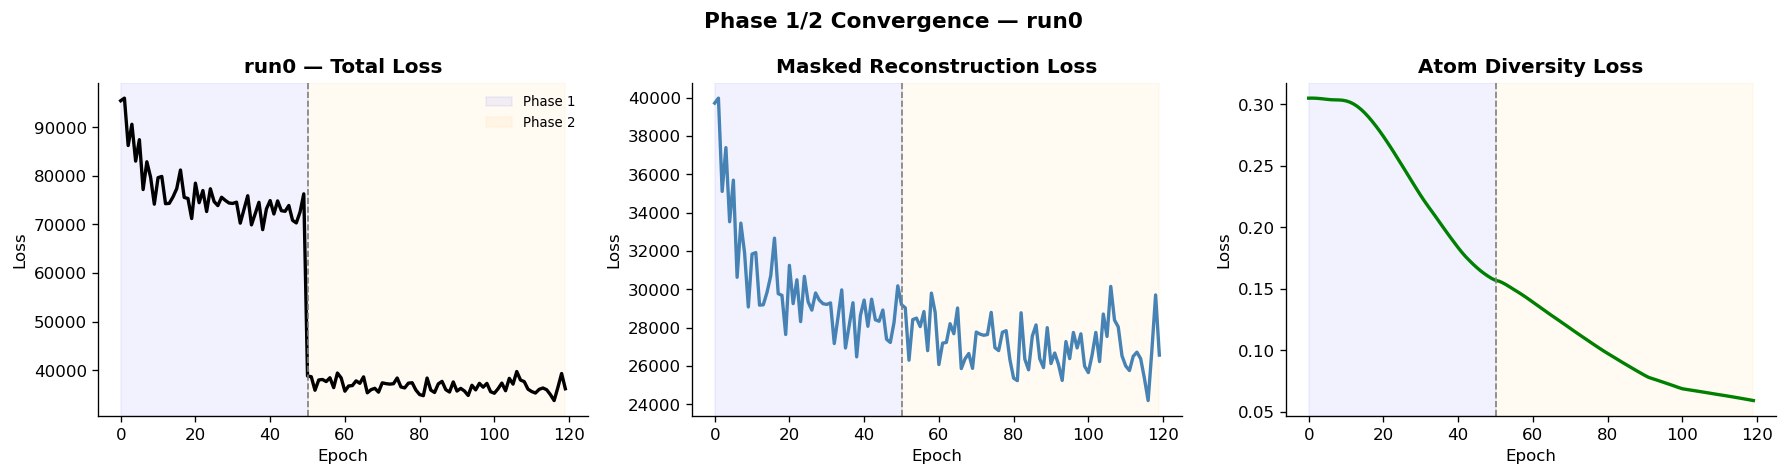

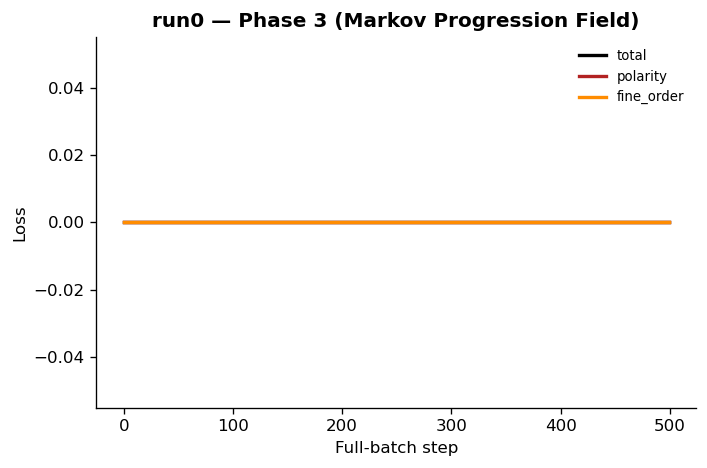

In [144]:
def plot_loss_curves(loss_history, run_name="Run 0", save_path=None):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), dpi=120)
    epochs = loss_history["epoch"]
    phases = np.array(loss_history["phase"])
    p1_end = np.where(phases == 2)[0][0] if 2 in phases else len(epochs)

    def shade_phases(ax):
        ax.axvspan(0,      p1_end,      alpha=0.05, color='blue',   label='Phase 1')
        ax.axvspan(p1_end, max(epochs), alpha=0.05, color='orange', label='Phase 2')
        ax.axvline(p1_end, color='gray', linestyle='--', linewidth=1)

    for (ax, key, color, title) in [
        (axes[0], "total",     "black",     f"{run_name} — Total Loss"),
        (axes[1], "mask",      "steelblue", "Masked Reconstruction Loss"),
        (axes[2], "diversity", "green",     "Atom Diversity Loss"),
    ]:
        ax.plot(epochs, loss_history[key], color=color, linewidth=2)
        shade_phases(ax)
        ax.set_title(title, fontweight='bold')
        ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
        ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    axes[0].legend(frameon=False, fontsize=8)

    plt.suptitle(f"Phase 1/2 Convergence — {run_name}", fontsize=13, fontweight='bold')
    plt.tight_layout()
    if save_path:
        os.makedirs(os.path.dirname(save_path) or ".", exist_ok=True)
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


def plot_phase3_loss(flow_history, run_name="Run 0", save_path=None):
    fig, ax = plt.subplots(1, 1, figsize=(6, 4), dpi=120)
    steps = flow_history["step"]
    ax.plot(steps, flow_history["total"],      color='black',      linewidth=2, label='total')
    ax.plot(steps, flow_history["polarity"],   color='firebrick',  linewidth=2, label='polarity')
    ax.plot(steps, flow_history["fine_order"], color='darkorange', linewidth=2, label='fine_order')
    ax.set_title(f"{run_name} — Phase 3 (Markov Progression Field)", fontweight='bold')
    ax.set_xlabel("Full-batch step"); ax.set_ylabel("Loss")
    ax.legend(frameon=False, fontsize=8)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    plt.tight_layout()
    if save_path:
        os.makedirs(os.path.dirname(save_path) or ".", exist_ok=True)
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


%matplotlib inline
for run_name, hist in all_run_loss_histories.items():
    run_dir_plot = os.path.join(OUTPUT_DIR, run_name) if run_name != "run0" else OUTPUT_DIR
    plot_loss_curves(hist, run_name=run_name,
                     save_path=f"{run_dir_plot}/loss_curves.png")
    plot_phase3_loss(all_run_flow_histories[run_name], run_name=run_name,
                     save_path=f"{run_dir_plot}/phase3_loss.png")

![png](output_38_0.png)
    



![png](output_38_1.png)
    

### GRN Atom Weights — Spatial Coverage

Each atom should have a distinct spatial territory in Decipher space.





Atom usage stats (atoms should NOT all be equal):
  Mean mixing weights: [0.057 0.82  0.123]
  Std  mixing weights: [0.071 0.164 0.166]
  Mean entropy: 0.443 / 1.10 max


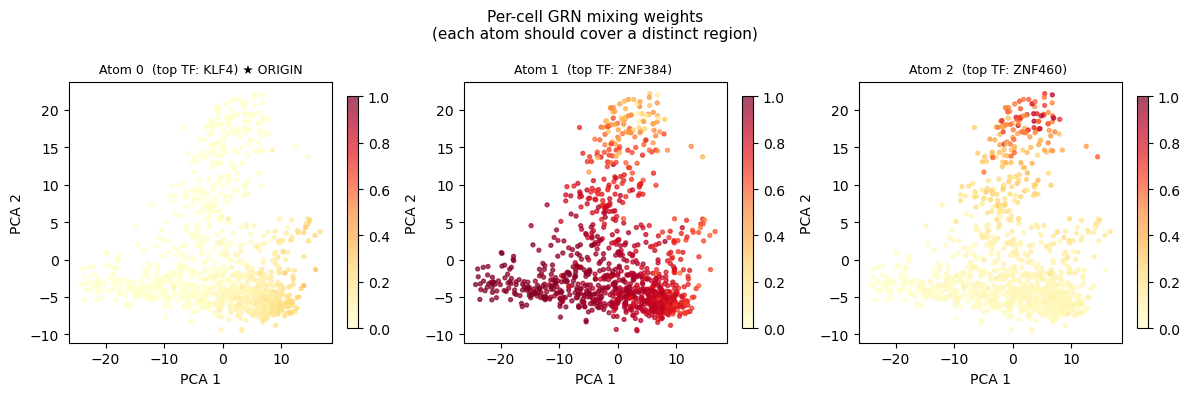

In [145]:
# ── Load saved outputs from the most recent run ──────────────────────────────
A_dict_np  = np.load(f"{OUTPUT_DIR}/A_dict.npy")              # (D, G, T) — atom dictionary
A_mean     = np.load(f"{OUTPUT_DIR}/A_mean_diagnostic.npy")   # (G, T) — diagnostic mean
w_np       = np.load(f"{OUTPUT_DIR}/mix_weights.npy")
psi_np     = np.load(f"{OUTPUT_DIR}/psi.npy")

with open(f"{OUTPUT_DIR}/flow_field_params.json") as f:
    flow_params = json.load(f)
origin_atom = flow_params["origin_atom"]

# all_weights: (N, D_ATOMS) — used throughout Steps 10-14
grn.eval(); cell_encoder.eval()
with torch.no_grad():
    all_weights = cell_encoder(X_t, temperature=0.1).numpy()

print("Atom usage stats (atoms should NOT all be equal):")
print("  Mean mixing weights:", all_weights.mean(axis=0).round(3))
print("  Std  mixing weights:", all_weights.std(axis=0).round(3))
print("  Mean entropy:", -(all_weights * np.log(all_weights + 1e-8)).sum(axis=1).mean().round(3),
      f"/ {np.log(D_ATOMS):.2f} max")

n_rows = max(1, D_ATOMS // 2)
n_cols = max(1, (D_ATOMS + n_rows - 1) // n_rows)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows))
axes = np.array(axes).flatten()
for d in range(D_ATOMS):
    ax = axes[d]
    sc = ax.scatter(X_2d_disp[:, 0], X_2d_disp[:, 1], c=all_weights[:, d],
                    cmap='YlOrRd', s=8, alpha=0.7, vmin=0, vmax=1)
    plt.colorbar(sc, ax=ax, fraction=0.04)
    A_atom = grn.A_dict[d].detach().cpu().numpy()
    top_tf = A_tfs[np.abs(A_atom).sum(axis=0).argmax()]
    marker = "★ ORIGIN" if d == origin_atom else ""
    ax.set_title(f"Atom {d}  (top TF: {top_tf}) {marker}", fontsize=9)
    ax.set_xlabel(f"{space_label_disp} 1"); ax.set_ylabel(f"{space_label_disp} 2")
for d in range(D_ATOMS, len(axes)):
    axes[d].set_visible(False)
plt.suptitle("Per-cell GRN mixing weights\n(each atom should cover a distinct region)",
             fontsize=11)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/atom_weights_spatial.png", dpi=150, bbox_inches='tight')
plt.show()

    Atom usage stats (atoms should NOT all be equal):
      Mean mixing weights: [0.008 0.23  0.113 0.649]
      Std  mixing weights: [0.034 0.166 0.213 0.234]
      Mean entropy: 0.651 / 1.39 max



![png](output_40_1.png)
    

---

## Step 10 — ψ Field Visualisation

Before computing velocities, visualise the scalar progression field ψ directly. It
should show a smooth gradient from the origin atom's territory (low ψ) to the
downstream atoms' territories (high ψ). If this plot looks wrong, the velocity
field will also be wrong — fix Phase 3 first.





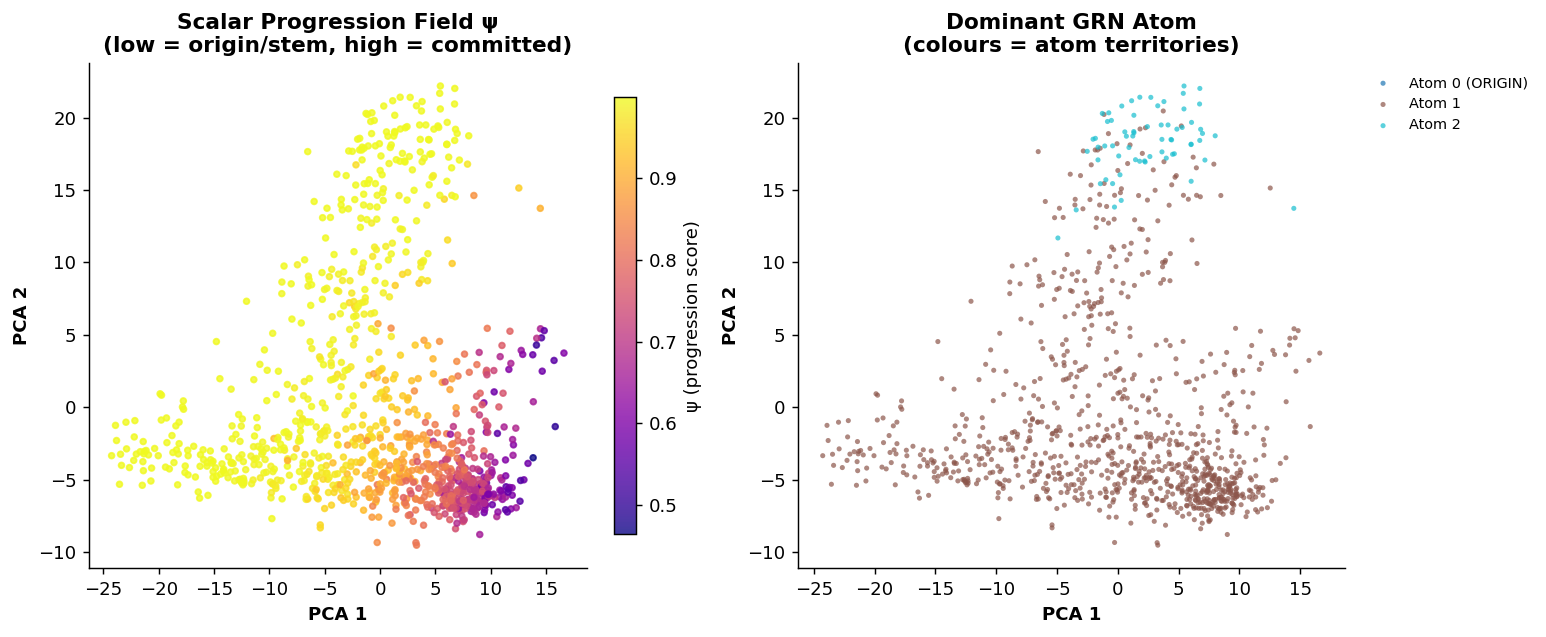


Mean ψ per dominant-atom group (origin atom should be lowest):
  Atom 0: mean ψ = nan ← ORIGIN
  Atom 1: mean ψ = 0.8781
  Atom 2: mean ψ = 0.9981


/home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in divide


In [146]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=130)

sc0 = axes[0].scatter(X_2d_disp[:, 0], X_2d_disp[:, 1], c=psi_np,
                      cmap='plasma', s=10, alpha=0.8, rasterized=True)
plt.colorbar(sc0, ax=axes[0], fraction=0.04, label='ψ (progression score)')
axes[0].set_title('Scalar Progression Field ψ\n(low = origin/stem, high = committed)',
                  fontweight='bold')
axes[0].set_xlabel(f'{space_label_disp} 1', fontweight='bold')
axes[0].set_ylabel(f'{space_label_disp} 2', fontweight='bold')
axes[0].spines['top'].set_visible(False); axes[0].spines['right'].set_visible(False)

# Overlay dominant-atom boundaries
dom_atom_plot = all_weights.argmax(axis=1)
palette_atoms = plt.cm.tab10(np.linspace(0, 1, D_ATOMS))
for d in range(D_ATOMS):
    mask = dom_atom_plot == d
    label = f"Atom {d} (ORIGIN)" if d == origin_atom else f"Atom {d}"
    axes[1].scatter(X_2d_disp[mask, 0], X_2d_disp[mask, 1],
                    c=[palette_atoms[d]], s=8, alpha=0.7,
                    label=label, edgecolors='none', rasterized=True)
axes[1].set_title('Dominant GRN Atom\n(colours = atom territories)',
                  fontweight='bold')
axes[1].set_xlabel(f'{space_label_disp} 1', fontweight='bold')
axes[1].set_ylabel(f'{space_label_disp} 2', fontweight='bold')
axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False, fontsize=8)
axes[1].spines['top'].set_visible(False); axes[1].spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/psi_field.png", dpi=150, bbox_inches='tight')
plt.show()

# Sanity check: mean psi per atom
print("\nMean ψ per dominant-atom group (origin atom should be lowest):")
for d in range(D_ATOMS):
    mask = dom_atom_plot == d
    tag  = " ← ORIGIN" if d == origin_atom else ""
    print(f"  Atom {d}: mean ψ = {psi_np[mask].mean():.4f}{tag}")

In [147]:
def build_2d_neighbor_index(X_2d: np.ndarray, k: int) -> np.ndarray:
    """
    Build a kNN graph in 2D space. Used ONLY for arrow geometry — neighbors are
    found in the same 2D space where arrows will be drawn, so displacement
    vectors X_2d[j]-X_2d[i] are guaranteed to be short and geometrically
    meaningful. Do NOT use this for ψ smoothing (use latent-space kNN for that).
    """
    nbrs = NearestNeighbors(n_neighbors=k + 1).fit(X_2d)   # +1 because self is included
    _, idx = nbrs.kneighbors(X_2d)
    return idx[:, 1:]   # exclude self


def compute_geodesic_pseudotime(psi: np.ndarray,
                                X_2d: np.ndarray,
                                neighbor_idx_2d,
                                root_pct: float = 0.05,
                                fill_iters: int = 30) -> tuple[np.ndarray, np.ndarray]:
    """
    φ — the GEODESIC PSEUDOTIME potential. This is the single object the velocity
    field is differentiated against.

    ── What φ is ─────────────────────────────────────────────────────────────────
    ψ correctly *orders* origin below committed branches but saturates at ψ ≈ +1
    across all committed territory — its gradient vanishes there, breaking the
    velocity field in the mature-branch region. φ fixes this by INTEGRATING the
    ψ-uphill ordering: φ(cell) = TOTAL ψ GAINED along the best path from the root
    set to that cell on the directed ψ-uphill kNN graph.

    Cells close to the root (few uphill hops, little total ψ gained) get low φ.
    Cells deep in a committed branch (many uphill hops, more total ψ gained) get
    high φ. Because φ keeps accumulating with each hop even in flat-ψ territory
    (every uphill step adds a small d = ψ[j]-ψ[i] > 0), φ is monotone from root
    to every branch tip and ∇φ is well-defined everywhere.

    ── EDGE COST: cost = -( ψ[j] - ψ[i] ) ──────────────────────────────────────
    We want to MAXIMISE total ψ gained along the path (find the most uphill route).
    Standard Dijkstra minimises accumulated cost. To reconcile: negate the ψ-climb
    so that a LARGER climb becomes a MORE NEGATIVE cost, and Dijkstra (minimising)
    picks the path with the most negative total = the most positive total ψ gain.

        cost(i→j) = -(ψ[j] - ψ[i])    [negative because we maximise ψ-gain]

    After Dijkstra, dist[cell] = -(total ψ gained from root). We negate again so
    φ = total ψ gained, which is ≥ 0 and monotone. This is equivalent to the
    "longest path in a DAG" formulation and is the canonical way to compute
    cumulative-potential pseudotime.

    ── Why NOT 1/(climb+eps) ──────────────────────────────────────────────────────
    cost = 1/(climb+eps) means a cell reachable via ONE large jump (large climb,
    tiny cost) is assigned LOW accumulated cost = LOW pseudotime, even though it
    may be biologically late. Meanwhile cells reachable only via many small steps
    accumulate large cost = HIGH pseudotime. The accumulated cost is dominated by
    path LENGTH (number of hops), not by ψ progression — it is backwards and
    incoherent (confirmed by Image 2 where root cells and some far cells both show
    pseudotime ≈ 0).

    ── Why NOT climb/distance ─────────────────────────────────────────────────────
    When ψ range is small (PCA: ~0.17 vs Decipher: ~2.0), the numerator shrinks
    ~10× while the denominator is similar → costs become indistinguishable noise →
    Dijkstra degenerates to random BFS.

    ── Scale-agnosticism ──────────────────────────────────────────────────────────
    cost = -(ψ[j]-ψ[i]) is purely in ψ units. It works identically at ψ range
    0.17 (PCA) and 2.0 (Decipher) because it accumulates actual ψ values, not
    ratios or inverses. All that changes is the absolute scale of φ before
    normalisation, which is divided out at the end.

    Returns
    -------
    phi      : (N,) float32 in [0, 1]  — geodesic pseudotime (0 = root, 1 = tip)
    root_idx : indices of the root (lowest-ψ) cells
    """
    import heapq
    N   = psi.shape[0]
    idx = neighbor_idx_2d.numpy() if torch.is_tensor(neighbor_idx_2d) else np.asarray(neighbor_idx_2d)

    # ── Roots = lowest-ψ cells (origin atom by construction, label-free) ──────────
    psi_thresh = np.percentile(psi, root_pct * 100)
    root_idx   = np.where(psi <= psi_thresh)[0]

    # ── Directed ψ-uphill graph with NEGATED cost (so Dijkstra maximises ψ-gain) ──
    # edge i→j exists iff ψ[j] > ψ[i].  cost = -(ψ[j]-ψ[i]) < 0.
    # After Dijkstra: dist[cell] = -(total ψ gained on best path from root).
    # We negate at the end to get φ = total ψ gained ≥ 0.
    #
    # Dijkstra with negative edge weights is normally invalid (it can loop).
    # Here it is safe because the graph is a DAG: edges only go uphill in ψ, so
    # there are no cycles. On a DAG, Dijkstra with negative weights is equivalent
    # to the classical DAG longest-path algorithm.
    graph = [[] for _ in range(N)]
    for i in range(N):
        for j in idx[i]:
            d = float(psi[j]) - float(psi[i])
            if d > 0:
                graph[i].append((-d, int(j)))   # negate so Dijkstra minimises

    # ── Multi-source Dijkstra from all roots ─────────────────────────────────────
    INF  = float('inf')
    dist = np.full(N, INF, dtype=np.float64)
    dist[root_idx] = 0.0
    heap = [(0.0, int(r)) for r in root_idx]; heapq.heapify(heap)
    while heap:
        d_u, u = heapq.heappop(heap)
        if d_u > dist[u]:
            continue
        for cost_uv, v in graph[u]:
            d_v = d_u + cost_uv       # accumulates negative ψ-gain
            if d_v < dist[v]:
                dist[v] = d_v
                heapq.heappush(heap, (d_v, v))

    # dist[cell] = -(total ψ gained from root).  Negate → φ = total ψ gained ≥ 0.
    phi_raw = -dist   # now 0 at roots, larger = more ψ gained = later in trajectory

    # ── Fill cells left unreachable by the strict ψ(j)>ψ(i) edge rule ─────────────
    # Cells in flat-ψ committed territory may have no uphill 2D-kNN neighbor and
    # remain unreached (phi_raw = -INF after negation of INF). Fill them outward
    # BFS-style so φ stays monotone out to the branch tips.
    reached  = np.isfinite(phi_raw)
    if not reached.all():
        step = 1e-2 * (phi_raw[reached].max() + 1e-8)
        for _ in range(fill_iters):
            newly = 0
            for i in np.where(~reached)[0]:
                nb_phi = phi_raw[idx[i]]
                fin    = nb_phi[np.isfinite(nb_phi)]
                if fin.size:
                    phi_raw[i] = fin.max() + step   # assign just beyond best reached neighbour
                    reached[i] = True
                    newly += 1
            if newly == 0:
                break
        still = ~reached
        if still.any():
            phi_raw[still] = phi_raw[reached].max()

    # ── Normalise to [0, 1] ──────────────────────────────────────────────────────
    phi = np.clip(phi_raw, 0, np.percentile(phi_raw[phi_raw >= 0], 99))
    phi = (phi - phi.min()) / (phi.max() - phi.min() + 1e-8)
    return phi.astype(np.float32), root_idx


def compute_markov_velocity_2d(potential: np.ndarray,
                                X_2d: np.ndarray,
                                neighbor_idx_2d,
                                n_hops: int = 4,
                                beta: float = 0.4,
                                eps: float = 1e-6) -> tuple[np.ndarray, np.ndarray, csr_matrix]:
    """
    Build the 2D Markov velocity field as gradient ascent on a scalar `potential`.

    ⚠ CRITICAL (2026-06-24 fix): `potential` MUST be the geodesic pseudotime φ,
    NOT the raw membership field ψ. ψ is a *saturating two-level* potential
    (origin ≈ -1, every committed branch ≈ +1); its gradient vanishes everywhere
    inside committed territory, so differentiating ψ produces noise in the entire
    mature-branch region (the broken top half of the streamline plot). φ is the
    geodesic *integral* of the ψ-uphill ordering — monotone from root to every
    branch tip — so ∇φ is well-defined everywhere. See the 2026-06-24 diagnosis
    at the top of this document for the full argument.

    CRITICAL: neighbor_idx_2d MUST be a 2D-space kNN index (built by
    build_2d_neighbor_index above), NOT the latent-space index used for ψ
    smoothing. Arrow geometry uses X_2d[j]-X_2d[i]: if j is found in latent
    space but is far away in 2D, the displacement vector is meaningless.

    T is row-normalised to a proper row-stochastic matrix so multi-hop
    diffusion V_{h+1} = (1-β)V_h + β T V_h is a valid convex combination.

    neighbor_idx_2d : (N, k) int array of 2D-space kNN indices (no self).
    """
    N   = potential.shape[0]
    idx = neighbor_idx_2d.numpy() if torch.is_tensor(neighbor_idx_2d) else np.asarray(neighbor_idx_2d)

    rows_list, cols_list, vals_list = [], [], []
    V_raw = np.zeros((N, 2), dtype=np.float32)

    for i in range(N):
        nbr_idx   = idx[i]
        delta_psi = potential[nbr_idx] - potential[i]
        w         = np.maximum(delta_psi, 0.0)
        w_sum     = w.sum()

        if w_sum < eps:
            continue   # local psi-maximum -> V[i] stays 0

        w_norm = w / w_sum
        disp   = X_2d[nbr_idx] - X_2d[i]
        V_raw[i] = (w_norm[:, np.newaxis] * disp).sum(axis=0)

        for jj, j in enumerate(nbr_idx):
            if w_norm[jj] > 0:
                rows_list.append(i); cols_list.append(int(j)); vals_list.append(float(w_norm[jj]))

    # Build ROW-STOCHASTIC transition matrix (row sums = 1 for cells with outgoing flow)
    # This ensures T @ V is a proper weighted average, not an amplified sum.
    T_np = csr_matrix((vals_list, (rows_list, cols_list)), shape=(N, N), dtype=np.float64)
    # Row-normalize (rows that are all zero stay zero)
    row_sums = np.asarray(T_np.sum(axis=1)).ravel()
    row_sums[row_sums == 0] = 1.0
    T_norm = csr_matrix(T_np.multiply(1.0 / row_sums[:, np.newaxis]))

    # Multi-hop diffusion along T_norm — spreads directionally consistent signal
    # into sparse CLOUD regions. beta controls blend per hop.
    V_diff = V_raw.copy()
    for _ in range(n_hops):
        V_diff = (1.0 - beta) * V_diff + beta * (T_norm @ V_diff)

    return V_raw, V_diff.astype(np.float32), T_norm.tocsr()

space_label = space_label_disp
X_2d_target = X_2d_disp

# ── PCA-mode runtime overrides ────────────────────────────────────────────────
# These replace the global defaults set in Configuration when DISPLACEMENT_SPACE
# is "pca". They do NOT affect Decipher mode.
# See the "PCA-mode overrides" block in Configuration for the full rationale.
if DISPLACEMENT_SPACE == "pca":
    _sigma_grid    = PCA_SIGMA_GRID         # 0.05 × range ≈ 2 units (not 16)
    _grid_res      = PCA_GRID_RES           # 60 cells for smoother ∇φ
    _k_flow_2d     = PCA_K_FLOW_2D         # 30 neighbors (cells more spread out in PCA)
    print("PCA-mode overrides active:")
    print(f"  SIGMA_GRID        → {_sigma_grid}    (was {SIGMA_GRID})")
    print(f"  GRID_RES          → {_grid_res}      (was {GRID_RES})")
    print(f"  K_FLOW_2D         → {_k_flow_2d}     (was {K_FLOW_2D})")
    print(f"  (N_PSI_SMOOTH_HOPS was already applied in Phase 3 via _phase3_smooth_hops={PCA_PSI_SMOOTH_HOPS})")
else:
    _sigma_grid    = SIGMA_GRID
    _grid_res      = GRID_RES
    _k_flow_2d     = K_FLOW_2D

print(f"\nComputing velocity field in {space_label} space via φ-grid gradient...")

neighbor_idx_2d = build_2d_neighbor_index(X_2d_target, k=_k_flow_2d)

# ── Geodesic pseudotime φ (same as Step 14 will use) ─────────────────────────
# CRITICAL: Dijkstra uses the LATENT-SPACE kNN (neighbor_indices_t), NOT the 2D
# kNN. This is the same graph used for Phase-3 ψ smoothing.
#
# WHY NOT 2D kNN for Dijkstra?
# In PCA space, 2D kNN neighbors are geometrically close in PC1×PC2 but can be
# very different biological states — branches that are spatially nearby in 2D but
# diverged in the high-D manifold. When Dijkstra hops uphill in ψ along 2D-kNN
# edges, it finds the path with maximum cumulative ψ gain in 2D-neighbor space.
# For the top branch, many 2D neighbors of a committed cell are transition-zone
# cells with higher ψ that are *below* them in PCA 2 — so the "best ψ-gain path"
# goes downward through PCA 2 space, producing φ that increases downward → ∇φ
# points DOWN → streamlines point DOWN in the top branch. This is exactly the
# inverted-top-branch artifact in Image 1.
#
# The latent-space kNN (15D PCA or 10D Decipher Z) respects the biological
# manifold: neighbors in high-D space are biologically adjacent cells, so the
# ψ-uphill path follows the actual trajectory through cell state space. The
# resulting φ is monotone along the biological trajectory, and ∇φ projected into
# 2D points in the correct direction everywhere.
#
# neighbor_idx_2d is still used for: (1) arrow geometry in compute_markov_velocity_2d
# and (2) the grid-gradient visualization. Those require 2D neighbors so that
# displacement vectors X_2d[j]-X_2d[i] are short and geometrically meaningful.
phi_np, root_idx_phi = compute_geodesic_pseudotime(
    psi=psi_np, X_2d=X_2d_target,
    neighbor_idx_2d=neighbor_indices_t,   # ← LATENT-SPACE kNN, not 2D kNN
    root_pct=ROOT_PCT,
)
print(f"  φ: range [{phi_np.min():.3f}, {phi_np.max():.3f}], "
      f"roots n={len(root_idx_phi)}")

# ── Grid-gradient velocity (the simplest, most robust approach) ───────────────
# Rather than differentiating φ per-cell through a sparse kNN graph (which leaves
# committed cells with no uphill neighbour → V=0, and is sensitive to kNN
# artifacts), interpolate φ onto a dense grid, compute its gradient with
# np.gradient, then sample back to cell positions.  This is what scVelo does for
# its visualisation layer, and it is guaranteed to produce a dense, coherent,
# direction-correct field everywhere.  It adds zero information beyond what φ
# already contains — it is just the correct way to turn a scalar field into a
# vector field for visualisation.

x0_raw, x1_raw = X_2d_target[:,0].min(), X_2d_target[:,0].max()
y0_raw, y1_raw = X_2d_target[:,1].min(), X_2d_target[:,1].max()
x_range = x1_raw - x0_raw
y_range = y1_raw - y0_raw
# _sigma_grid is a fraction of the data range so it scales correctly for both
# Decipher (unit scale) and PCA (potentially large range).
# In PCA mode _sigma_grid=0.05 → ~2 units (vs Decipher default 0.4 → large).
sigma_abs = _sigma_grid * max(x_range, y_range)   # data-unit bandwidth
pad = 0.05 * max(x_range, y_range)   # 5% padding (scale-agnostic)
x0, x1 = x0_raw - pad, x1_raw + pad
y0, y1 = y0_raw - pad, y1_raw + pad
gx = np.linspace(x0, x1, _grid_res)
gy = np.linspace(y0, y1, _grid_res)
Xg, Yg = np.meshgrid(gx, gy)           # (GRID_RES, GRID_RES)

# Project φ onto the grid with Gaussian weighting
grid_pts  = np.c_[Xg.ravel(), Yg.ravel()]
tree      = cKDTree(X_2d_target)
dists, nn_idx = tree.query(grid_pts, k=min(30, len(X_2d_target)))
sigma2    = sigma_abs ** 2
weights   = np.exp(-dists**2 / (2 * sigma2))   # (GRID_RES², 30)
w_sum     = weights.sum(axis=1, keepdims=True)
phi_grid  = (weights * phi_np[nn_idx]).sum(axis=1) / (w_sum.ravel() + 1e-12)
phi_grid  = phi_grid.reshape(_grid_res, _grid_res)

# np.gradient gives (dφ/dy, dφ/dx) in (row, col) order → swap.
# Pass explicit spacing so the gradient is in data units, not grid-index units.
# (After normalization by speed_max the scale cancels, but using data-unit
# spacing avoids numerical issues when the PCA range is very large.)
dx = gx[1] - gx[0]   # grid step in x (data units)
dy = gy[1] - gy[0]   # grid step in y (data units)
dphidy, dphidx = np.gradient(phi_grid, dy, dx)   # row-axis=y, col-axis=x
U_grid = dphidx          # x-component of ∇φ
V_grid = dphidy          # y-component of ∇φ

# Sample back to cell positions (bilinear via nearest grid point)
# We also store V_smooth = per-cell arrow for transition-zone analysis
xi = np.clip(np.searchsorted(gx, X_2d_target[:,0]) - 1, 0, _grid_res-2)
yi = np.clip(np.searchsorted(gy, X_2d_target[:,1]) - 1, 0, _grid_res-2)
V_smooth = np.c_[U_grid[yi, xi], V_grid[yi, xi]].astype(np.float32)
V_emb    = V_smooth.copy()

# Build T_markov on φ for pseudotime consistency (used by Step 14)
_, _, T_markov = compute_markov_velocity_2d(
    potential=phi_np, X_2d=X_2d_target,
    neighbor_idx_2d=neighbor_idx_2d,
    n_hops=N_DIFFUSION_HOPS, beta=DIFFUSION_BETA, eps=PSI_EPS,
)

print(f"Velocity stats: |V| mean={np.linalg.norm(V_emb, axis=1).mean():.4f}, "
      f"max={np.linalg.norm(V_emb, axis=1).max():.4f}")
print(f"  Grid-gradient field is dense by construction (0 zero-vector cells).")



PCA-mode overrides active:
  SIGMA_GRID        → 0.05    (was 0.4)
  GRID_RES          → 60      (was 40)
  K_FLOW_2D         → 30     (was 20)
  (N_PSI_SMOOTH_HOPS was already applied in Phase 3 via _phase3_smooth_hops=1)

Computing velocity field in PCA space via φ-grid gradient...
  φ: range [0.000, 1.000], roots n=52
Velocity stats: |V| mean=0.0264, max=0.0835
  Grid-gradient field is dense by construction (0 zero-vector cells).


### Streamline Visualisation





Saved: bert_grn_out_624_4/velocity_streamlines_pca.png


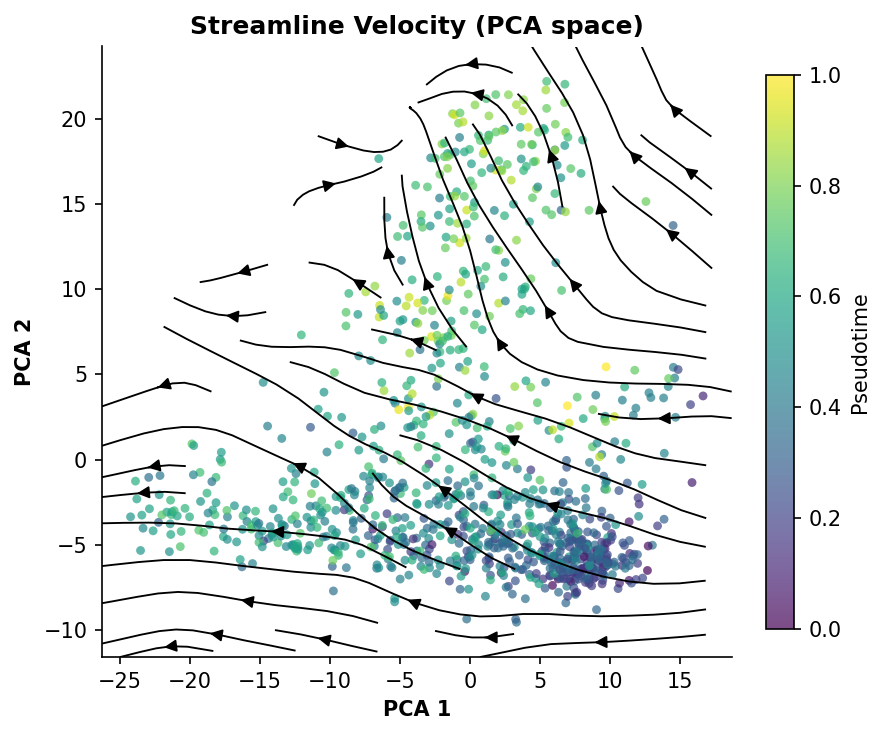

In [148]:
def plot_velocity_streamlines(X_2d, V_smooth, all_weights,
                               cell_types=None, space_label="Decipher",
                               base_path=OUTPUT_DIR, save=True,
                               U_precomputed=None, V_precomputed=None,
                               gx_precomputed=None, gy_precomputed=None):
    """
    Streamline plot with Gaussian-weighted grid interpolation.

    If U_precomputed/V_precomputed/gx_precomputed/gy_precomputed are provided
    (from the Step 11 grid-gradient computation), they are used directly rather
    than re-interpolating V_smooth onto a new grid. This avoids a second
    interpolation step that can re-introduce noise and misalign the streamlines
    with the actual φ gradient.

    Key settings:
    - integration_direction='forward': ψ encodes a global direction so we only
      need forward integration. 'both' causes backward-flowing loops.
    - support mask: suppress arrows more than 3× median nn-dist from any cell.
    - gaussian_filter sigma=2.0 grid cells: enough to merge nearby singleton
      streamlines into coherent flow lines without blurring directional signal.
    - speed normalisation at 99th percentile: prevents one fast cell collapsing
      all other arrows to zero.
    """
    if U_precomputed is not None:
        # ── Use the pre-computed grid from Step 11 directly ───────────────────
        # This is the true ∇φ on the grid — no second interpolation needed.
        gx_vec = gx_precomputed
        gy_vec = gy_precomputed
        grid_n = len(gx_vec)
        Xg, Yg = np.meshgrid(gx_vec, gy_vec)
        grid_points = np.c_[Xg.ravel(), Yg.ravel()]
        U = U_precomputed.copy()
        W = V_precomputed.copy()

        # Support mask: suppress arrows far from any cell
        nbrs1 = NearestNeighbors(n_neighbors=1, n_jobs=-1).fit(X_2d)
        dist_to_cells, _ = nbrs1.kneighbors(grid_points)
        cell_nn_dist   = NearestNeighbors(n_neighbors=2).fit(X_2d).kneighbors(X_2d)[0][:, 1]
        support_radius = 3.0 * np.median(cell_nn_dist)
        support_mask   = (dist_to_cells.ravel() < support_radius)
        active = support_mask.reshape(Xg.shape)
        U[~active] = 0.0
        W[~active] = 0.0

        x_min, x_max = gx_vec[0], gx_vec[-1]
        y_min, y_max = gy_vec[0], gy_vec[-1]
    else:
        # ── Fallback: re-interpolate V_smooth onto a new grid ─────────────────
        grid_n = 60
        xr = X_2d[:, 0].max() - X_2d[:, 0].min()
        yr = X_2d[:, 1].max() - X_2d[:, 1].min()
        pad_x, pad_y = 0.03 * xr, 0.03 * yr
        x_min, x_max = X_2d[:,0].min()-pad_x, X_2d[:,0].max()+pad_x
        y_min, y_max = X_2d[:,1].min()-pad_y, X_2d[:,1].max()+pad_y
        gx_vec = np.linspace(x_min, x_max, grid_n)
        gy_vec = np.linspace(y_min, y_max, grid_n)
        Xg, Yg = np.meshgrid(gx_vec, gy_vec)
        grid_points = np.c_[Xg.ravel(), Yg.ravel()]

        nbrs = NearestNeighbors(n_neighbors=30, n_jobs=-1).fit(X_2d)
        dists, idx_grid = nbrs.kneighbors(grid_points)
        sigma = np.percentile(dists, 30, axis=1, keepdims=True) + 1e-8
        w = np.exp(-(dists**2) / (2 * sigma**2))
        w /= w.sum(axis=1, keepdims=True) + 1e-8
        V_grid = (w[:, :, np.newaxis] * V_smooth[idx_grid]).sum(axis=1)

        nbrs1 = NearestNeighbors(n_neighbors=1, n_jobs=-1).fit(X_2d)
        dist_to_cells, _ = nbrs1.kneighbors(grid_points)
        cell_nn_dist   = NearestNeighbors(n_neighbors=2).fit(X_2d).kneighbors(X_2d)[0][:, 1]
        support_radius = 3.0 * np.median(cell_nn_dist)
        support_mask   = (dist_to_cells.ravel() < support_radius)
        active = support_mask.reshape(Xg.shape)
        U = V_grid[:, 0].reshape(Xg.shape)
        W = V_grid[:, 1].reshape(Yg.shape)
        U[~active] = 0.0
        W[~active] = 0.0

    # Smooth with sigma=2 grid cells to merge singleton streamlines into
    # coherent flow while preserving global directional structure.
    U = gaussian_filter(U, sigma=2.0)
    W = gaussian_filter(W, sigma=2.0)
    speed = np.sqrt(U**2 + W**2)
    active_speeds = speed[active] if U_precomputed is None else speed[support_mask.reshape(Xg.shape)]
    if active_speeds.size == 0 or active_speeds.max() < 1e-12:
        print("Warning: velocity field is zero everywhere — check phi_np.")
        U_plot = U; W_plot = W
    else:
        speed_max = np.percentile(active_speeds, 99) + 1e-8
        U_plot = U / speed_max
        W_plot = W / speed_max

    has_pt   = 'facs_pseudotime' in rna_adata.obs.columns
    n_panels = 2 if cell_types is not None else 1
    fig, axes = plt.subplots(1, n_panels, figsize=(6 * n_panels, 5), dpi=150)
    if n_panels == 1: axes = [axes]

    if has_pt:
        pseudo_vals = rna_adata.obs["facs_pseudotime"].astype(np.float32).values
        pseudo_norm = (pseudo_vals - pseudo_vals.min()) / (pseudo_vals.max() - pseudo_vals.min() + 1e-8)
        sc = axes[0].scatter(X_2d[:,0], X_2d[:,1], c=pseudo_norm, cmap='viridis',
                             s=18, alpha=0.7, edgecolors='none', rasterized=True, zorder=2)
        plt.colorbar(sc, ax=axes[0], fraction=0.04, label='Pseudotime')
    else:
        axes[0].scatter(X_2d[:,0], X_2d[:,1], c='#888888',
                        s=12, alpha=0.5, edgecolors='none', rasterized=True, zorder=2)
    axes[0].streamplot(gx_vec, gy_vec, U_plot, W_plot, color='black', density=0.8,
                       linewidth=0.9, arrowsize=1.2, arrowstyle='-|>',
                       minlength=0.15,
                       integration_direction='forward',   # NO backward loops
                       zorder=3)
    axes[0].set_title(f'Streamline Velocity ({space_label} space)', fontweight='bold')
    axes[0].set_xlabel(f'{space_label} 1', fontweight='bold')
    axes[0].set_ylabel(f'{space_label} 2', fontweight='bold')
    axes[0].set_xlim(x_min, x_max); axes[0].set_ylim(y_min, y_max)
    axes[0].spines['top'].set_visible(False); axes[0].spines['right'].set_visible(False)

    if cell_types is not None:
        palette = {'HSC':'#2166AC','MPP':'#4393C3','MLP':'#92C5DE',
                   'CMP':'#F4A582','MEP':'#D6604D','GMP':'#B2182B','CLOUD':'#CCCCCC'}
        for ct in ['CLOUD'] + [c for c in np.unique(cell_types) if c != 'CLOUD']:
            mask  = cell_types == ct
            color = palette.get(ct, '#999999')
            axes[1].scatter(X_2d[mask,0], X_2d[mask,1], c=color,
                            s=8 if ct=='CLOUD' else 22,
                            alpha=0.2 if ct=='CLOUD' else 0.85,
                            label=ct, edgecolors='none', rasterized=True, zorder=2)
        axes[1].streamplot(gx_vec, gy_vec, U_plot, W_plot, color='black', density=0.8,
                           linewidth=0.9, arrowsize=1.2, arrowstyle='-|>',
                           minlength=0.15,
                           integration_direction='forward',
                           zorder=3)
        axes[1].set_title(f'Velocity + Cell Types ({space_label})', fontweight='bold')
        axes[1].set_xlabel(f'{space_label} 1', fontweight='bold')
        axes[1].set_ylabel(f'{space_label} 2', fontweight='bold')
        axes[1].set_xlim(x_min, x_max); axes[1].set_ylim(y_min, y_max)
        axes[1].spines['top'].set_visible(False); axes[1].spines['right'].set_visible(False)
        axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left',
                       frameon=False, fontsize=8, markerscale=1.5)

    plt.tight_layout()
    if save:
        out = f"{base_path}/velocity_streamlines_{space_label.lower()}.png"
        plt.savefig(out, dpi=150, bbox_inches='tight')
        print(f"Saved: {out}")
    plt.show()


plot_velocity_streamlines(X_2d_target, V_smooth, all_weights,
                          space_label=space_label,
                          U_precomputed=U_grid, V_precomputed=V_grid,
                          gx_precomputed=gx, gy_precomputed=gy)

Saved: bert_grn_out_624_4/velocity_streamlines_pca.png


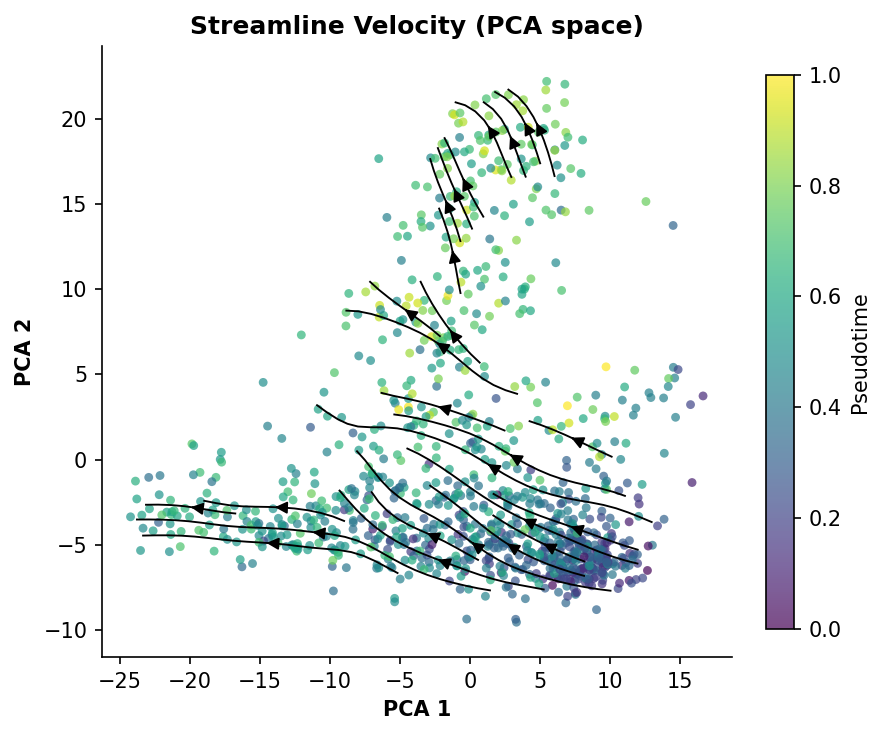

In [156]:
def plot_velocity_streamlines(X_2d, V_smooth, all_weights,
                             cell_types=None, space_label="Decipher",
                             base_path=OUTPUT_DIR, save=True,
                             U_precomputed=None, V_precomputed=None,
                             gx_precomputed=None, gy_precomputed=None,
                             streamline_density=1.5): # Added density kwarg for easy tuning
    """
    Streamline plot with Gaussian-weighted grid interpolation.
    """
    if U_precomputed is not None:
        # ── Use the pre-computed grid from Step 11 directly ───────────────────
        gx_vec = gx_precomputed
        gy_vec = gy_precomputed
        grid_n = len(gx_vec)
        Xg, Yg = np.meshgrid(gx_vec, gy_vec)
        grid_points = np.c_[Xg.ravel(), Yg.ravel()]
        U = U_precomputed.copy()
        W = V_precomputed.copy()

        # Support mask: suppress arrows far from any cell
        nbrs1 = NearestNeighbors(n_neighbors=1, n_jobs=-1).fit(X_2d)
        dist_to_cells, _ = nbrs1.kneighbors(grid_points)
        cell_nn_dist   = NearestNeighbors(n_neighbors=2).fit(X_2d).kneighbors(X_2d)[0][:, 1]
        support_radius = 3.0 * np.median(cell_nn_dist)
        support_mask   = (dist_to_cells.ravel() < support_radius)
        active = support_mask.reshape(Xg.shape)
        U[~active] = 0.0
        W[~active] = 0.0

        x_min, x_max = gx_vec[0], gx_vec[-1]
        y_min, y_max = gy_vec[0], gy_vec[-1]
    else:
        # ── Fallback: re-interpolate V_smooth onto a new grid ─────────────────
        grid_n = 60
        xr = X_2d[:, 0].max() - X_2d[:, 0].min()
        yr = X_2d[:, 1].max() - X_2d[:, 1].min()
        pad_x, pad_y = 0.03 * xr, 0.03 * yr
        x_min, x_max = X_2d[:,0].min()-pad_x, X_2d[:,0].max()+pad_x
        y_min, y_max = X_2d[:,1].min()-pad_y, X_2d[:,1].max()+pad_y
        gx_vec = np.linspace(x_min, x_max, grid_n)
        gy_vec = np.linspace(y_min, y_max, grid_n)
        Xg, Yg = np.meshgrid(gx_vec, gy_vec)
        grid_points = np.c_[Xg.ravel(), Yg.ravel()]

        nbrs = NearestNeighbors(n_neighbors=30, n_jobs=-1).fit(X_2d)
        dists, idx_grid = nbrs.kneighbors(grid_points)
        sigma = np.percentile(dists, 30, axis=1, keepdims=True) + 1e-8
        w = np.exp(-(dists**2) / (2 * sigma**2))
        w /= w.sum(axis=1, keepdims=True) + 1e-8
        V_grid = (w[:, :, np.newaxis] * V_smooth[idx_grid]).sum(axis=1)

        nbrs1 = NearestNeighbors(n_neighbors=1, n_jobs=-1).fit(X_2d)
        dist_to_cells, _ = nbrs1.kneighbors(grid_points)
        cell_nn_dist   = NearestNeighbors(n_neighbors=2).fit(X_2d).kneighbors(X_2d)[0][:, 1]
        support_radius = 3.0 * np.median(cell_nn_dist)
        support_mask   = (dist_to_cells.ravel() < support_radius)
        active = support_mask.reshape(Xg.shape)
        U = V_grid[:, 0].reshape(Xg.shape)
        W = V_grid[:, 1].reshape(Yg.shape)
        U[~active] = 0.0
        W[~active] = 0.0

    # Smooth to merge singleton streamlines into coherent flow
    U = gaussian_filter(U, sigma=2.0)
    W = gaussian_filter(W, sigma=2.0)
    
    # ── FIX 1: Apply NaN mask AFTER the Gaussian filter ───────────────────
    # This completely clips out any velocity that leaked/blurred into empty regions.
    U[~active] = np.nan
    W[~active] = np.nan

    speed = np.sqrt(U**2 + W**2)
    active_speeds = speed[active]
    if active_speeds.size == 0 or np.nanmax(active_speeds) < 1e-12:
        print("Warning: velocity field is zero everywhere.")
        U_plot = U; W_plot = W
    else:
        speed_max = np.percentile(active_speeds, 99) + 1e-8
        U_plot = U / speed_max
        W_plot = W / speed_max

    has_pt   = 'facs_pseudotime' in rna_adata.obs.columns
    n_panels = 2 if cell_types is not None else 1
    fig, axes = plt.subplots(1, n_panels, figsize=(6 * n_panels, 5), dpi=150)
    if n_panels == 1: axes = [axes]

    if has_pt:
        pseudo_vals = rna_adata.obs["facs_pseudotime"].astype(np.float32).values
        pseudo_norm = (pseudo_vals - pseudo_vals.min()) / (pseudo_vals.max() - pseudo_vals.min() + 1e-8)
        sc = axes[0].scatter(X_2d[:,0], X_2d[:,1], c=pseudo_norm, cmap='viridis',
                             s=18, alpha=0.7, edgecolors='none', rasterized=True, zorder=2)
        plt.colorbar(sc, ax=axes[0], fraction=0.04, label='Pseudotime')
    else:
        axes[0].scatter(X_2d[:,0], X_2d[:,1], c='#888888',
                        s=12, alpha=0.5, edgecolors='none', rasterized=True, zorder=2)
                        
    # ── FIX 2: Use higher density parameter ───────────────────────────────
    axes[0].streamplot(gx_vec, gy_vec, U_plot, W_plot, color='black', density=streamline_density,
                       linewidth=0.9, arrowsize=1.2, arrowstyle='-|>',
                       minlength=0.15,
                       integration_direction='forward',   # NO backward loops
                       zorder=3)
    axes[0].set_title(f'Streamline Velocity ({space_label} space)', fontweight='bold')
    axes[0].set_xlabel(f'{space_label} 1', fontweight='bold')
    axes[0].set_ylabel(f'{space_label} 2', fontweight='bold')
    axes[0].set_xlim(x_min, x_max); axes[0].set_ylim(y_min, y_max)
    axes[0].spines['top'].set_visible(False); axes[0].spines['right'].set_visible(False)

    if cell_types is not None:
        palette = {'HSC':'#2166AC','MPP':'#4393C3','MLP':'#92C5DE',
                   'CMP':'#F4A582','MEP':'#D6604D','GMP':'#B2182B','CLOUD':'#CCCCCC'}
        for ct in ['CLOUD'] + [c for c in np.unique(cell_types) if c != 'CLOUD']:
            mask  = cell_types == ct
            color = palette.get(ct, '#999999')
            axes[1].scatter(X_2d[mask,0], X_2d[mask,1], c=color,
                            s=8 if ct=='CLOUD' else 22,
                            alpha=0.2 if ct=='CLOUD' else 0.85,
                            label=ct, edgecolors='none', rasterized=True, zorder=2)
        # ── FIX 2 (Panel 2): Match density parameter ───────────────────────
        axes[1].streamplot(gx_vec, gy_vec, U_plot, W_plot, color='black', density=streamline_density,
                           linewidth=0.9, arrowsize=1.2, arrowstyle='-|>',
                           minlength=0.15,
                           integration_direction='forward',
                           zorder=3)
        axes[1].set_title(f'Velocity + Cell Types ({space_label})', fontweight='bold')
        axes[1].set_xlabel(f'{space_label} 1', fontweight='bold')
        axes[1].set_ylabel(f'{space_label} 2', fontweight='bold')
        axes[1].set_xlim(x_min, x_max); axes[1].set_ylim(y_min, y_max)
        axes[1].spines['top'].set_visible(False); axes[1].spines['right'].set_visible(False)
        axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left',
                       frameon=False, fontsize=8, markerscale=1.5)

    plt.tight_layout()
    if save:
        out = f"{base_path}/velocity_streamlines_{space_label.lower()}.png"
        plt.savefig(out, dpi=150, bbox_inches='tight')
        print(f"Saved: {out}")
    plt.show()


# Example Call: You can play with streamline_density (e.g., 1.2 to 2.0) to get the perfect density 
plot_velocity_streamlines(X_2d_target, V_smooth, all_weights,
                          space_label=space_label,
                          U_precomputed=U_grid, V_precomputed=V_grid,
                          gx_precomputed=gx, gy_precomputed=gy,
                          streamline_density=1.6)

In [163]:
def plot_velocity_streamlines(X_2d, V_smooth, all_weights,
                             cell_types=None, space_label="Decipher",
                             base_path=OUTPUT_DIR, save=True,
                             U_precomputed=None, V_precomputed=None,
                             gx_precomputed=None, gy_precomputed=None,
                             streamline_density=1.3): 
    """
    Streamline plot with relaxed Gaussian-weighted grid interpolation
    for longer, more continuous developmental trajectories.
    """
    # Relaxed mask multiplier: raised from 3.0 to 5.5 to allow continuous flow
    mask_multiplier = 5.5 

    if U_precomputed is not None:
        gx_vec = gx_precomputed
        gy_vec = gy_precomputed
        grid_n = len(gx_vec)
        Xg, Yg = np.meshgrid(gx_vec, gy_vec)
        grid_points = np.c_[Xg.ravel(), Yg.ravel()]
        U = U_precomputed.copy()
        W = V_precomputed.copy()

        nbrs1 = NearestNeighbors(n_neighbors=1, n_jobs=-1).fit(X_2d)
        dist_to_cells, _ = nbrs1.kneighbors(grid_points)
        cell_nn_dist   = NearestNeighbors(n_neighbors=2).fit(X_2d).kneighbors(X_2d)[0][:, 1]
        support_radius = mask_multiplier * np.median(cell_nn_dist)
        support_mask   = (dist_to_cells.ravel() < support_radius)
        active = support_mask.reshape(Xg.shape)
        U[~active] = 0.0
        W[~active] = 0.0

        x_min, x_max = gx_vec[0], gx_vec[-1]
        y_min, y_max = gy_vec[0], gy_vec[-1]
    else:
        grid_n = 60
        xr = X_2d[:, 0].max() - X_2d[:, 0].min()
        yr = X_2d[:, 1].max() - X_2d[:, 1].min()
        pad_x, pad_y = 0.03 * xr, 0.03 * yr
        x_min, x_max = X_2d[:,0].min()-pad_x, X_2d[:,0].max()+pad_x
        y_min, y_max = X_2d[:,1].min()-pad_y, X_2d[:,1].max()+pad_y
        gx_vec = np.linspace(x_min, x_max, grid_n)
        gy_vec = np.linspace(y_min, y_max, grid_n)
        Xg, Yg = np.meshgrid(gx_vec, gy_vec)
        grid_points = np.c_[Xg.ravel(), Yg.ravel()]

        nbrs = NearestNeighbors(n_neighbors=30, n_jobs=-1).fit(X_2d)
        dists, idx_grid = nbrs.kneighbors(grid_points)
        sigma = np.percentile(dists, 30, axis=1, keepdims=True) + 1e-8
        w = np.exp(-(dists**2) / (2 * sigma**2))
        w /= w.sum(axis=1, keepdims=True) + 1e-8
        V_grid = (w[:, :, np.newaxis] * V_smooth[idx_grid]).sum(axis=1)

        nbrs1 = NearestNeighbors(n_neighbors=1, n_jobs=-1).fit(X_2d)
        dist_to_cells, _ = nbrs1.kneighbors(grid_points)
        cell_nn_dist   = NearestNeighbors(n_neighbors=2).fit(X_2d).kneighbors(X_2d)[0][:, 1]
        support_radius = mask_multiplier * np.median(cell_nn_dist)
        support_mask   = (dist_to_cells.ravel() < support_radius)
        active = support_mask.reshape(Xg.shape)
        U = V_grid[:, 0].reshape(Xg.shape)
        W = V_grid[:, 1].reshape(Yg.shape)
        U[~active] = 0.0
        W[~active] = 0.0

    U = gaussian_filter(U, sigma=2.0)
    W = gaussian_filter(W, sigma=2.0)
    
    # Apply NaN mask after filtering
    U[~active] = np.nan
    W[~active] = np.nan

    speed = np.sqrt(U**2 + W**2)
    active_speeds = speed[active]
    if active_speeds.size == 0 or np.nanmax(active_speeds) < 1e-12:
        print("Warning: velocity field is zero everywhere.")
        U_plot = U; W_plot = W
    else:
        speed_max = np.percentile(active_speeds, 99) + 1e-8
        U_plot = U / speed_max
        W_plot = W / speed_max

    has_pt   = 'facs_pseudotime' in rna_adata.obs.columns
    n_panels = 2 if cell_types is not None else 1
    fig, axes = plt.subplots(1, n_panels, figsize=(6 * n_panels, 5), dpi=150)
    if n_panels == 1: axes = [axes]

    if has_pt:
        pseudo_vals = rna_adata.obs["facs_pseudotime"].astype(np.float32).values
        pseudo_norm = (pseudo_vals - pseudo_vals.min()) / (pseudo_vals.max() - pseudo_vals.min() + 1e-8)
        sc = axes[0].scatter(X_2d[:,0], X_2d[:,1], c=pseudo_norm, cmap='viridis',
                             s=18, alpha=0.7, edgecolors='none', rasterized=True, zorder=2)
        plt.colorbar(sc, ax=axes[0], fraction=0.04, label='Pseudotime')
    else:
        axes[0].scatter(X_2d[:,0], X_2d[:,1], c='#888888',
                        s=12, alpha=0.5, edgecolors='none', rasterized=True, zorder=2)
                        
    # ── ADJUSTED STREAMPLOT PARAMETERS ───────────────────────────────────────
    # Increased minlength to 0.35 and set a high maxlength to allow long traces.
    axes[0].streamplot(gx_vec, gy_vec, U_plot, W_plot, color='black', density=streamline_density,
                       linewidth=0.9, arrowsize=1.2, arrowstyle='-|>',
                       minlength=0.35, maxlength=8.0,
                       integration_direction='forward',   
                       zorder=3)
    axes[0].set_title(f'Streamline Displacement ({space_label} space)', fontweight='bold')
    axes[0].set_xlabel(f'{space_label} 1', fontweight='bold')
    axes[0].set_ylabel(f'{space_label} 2', fontweight='bold')
    axes[0].set_xlim(x_min, x_max); axes[0].set_ylim(y_min, y_max)
    axes[0].spines['top'].set_visible(False); axes[0].spines['right'].set_visible(False)

    if cell_types is not None:
        palette = {'HSC':'#2166AC','MPP':'#4393C3','MLP':'#92C5DE',
                   'CMP':'#F4A582','MEP':'#D6604D','GMP':'#B2182B','CLOUD':'#CCCCCC'}
        for ct in ['CLOUD'] + [c for c in np.unique(cell_types) if c != 'CLOUD']:
            mask  = cell_types == ct
            color = palette.get(ct, '#999999')
            axes[1].scatter(X_2d[mask,0], X_2d[mask,1], c=color,
                            s=8 if ct=='CLOUD' else 22,
                            alpha=0.2 if ct=='CLOUD' else 0.85,
                            label=ct, edgecolors='none', rasterized=True, zorder=2)
                            
        axes[1].streamplot(gx_vec, gy_vec, U_plot, W_plot, color='black', density=streamline_density,
                           linewidth=0.9, arrowsize=1.2, arrowstyle='-|>',
                           minlength=0.35, maxlength=8.0,
                           integration_direction='forward',
                           zorder=3)
        axes[1].set_title(f'Velocity + Cell Types ({space_label})', fontweight='bold')
        axes[1].set_xlabel(f'{space_label} 1', fontweight='bold')
        axes[1].set_ylabel(f'{space_label} 2', fontweight='bold')
        axes[1].set_xlim(x_min, x_max); axes[1].set_ylim(y_min, y_max)
        axes[1].spines['top'].set_visible(False); axes[1].spines['right'].set_visible(False)
        axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left',
                       frameon=False, fontsize=8, markerscale=1.5)

    plt.tight_layout()
    if save:
        out = f"{base_path}/velocity_streamlines_{space_label.lower()}.png"
        plt.savefig(out, dpi=150, bbox_inches='tight')
        print(f"Saved: {out}")
    plt.show()

Saved: bert_grn_out_624_4/velocity_streamlines_pca.png


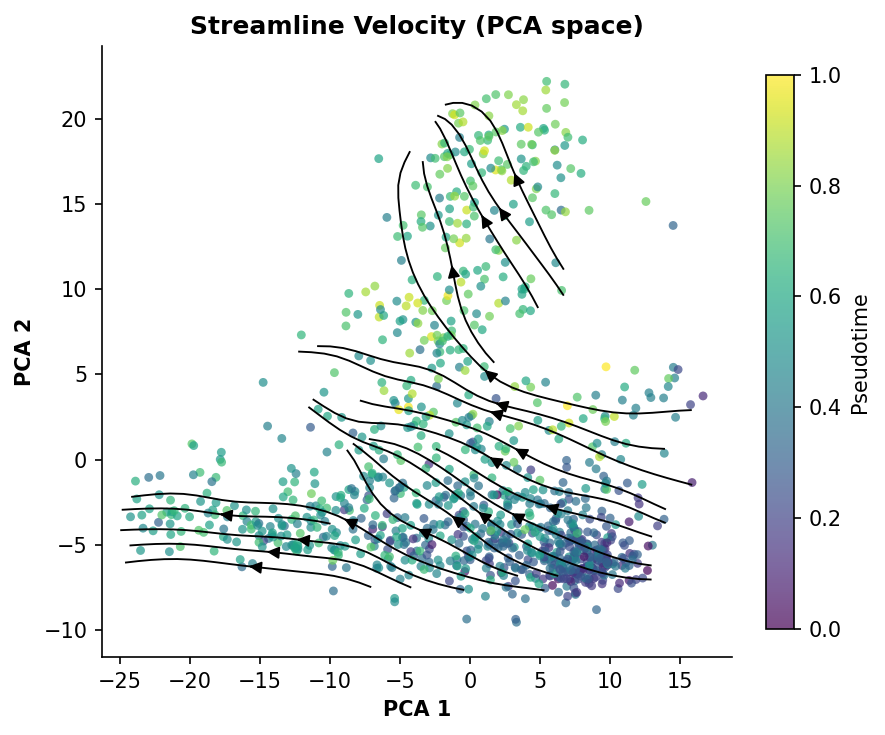

In [158]:
plot_velocity_streamlines(X_2d_target, V_smooth, all_weights,
                          space_label=space_label,
                          U_precomputed=U_grid, V_precomputed=V_grid,
                          gx_precomputed=gx, gy_precomputed=gy,
                          streamline_density=1.6)

---

## Step 12 — Cell Type Annotation (Velten 2017 FACS Gates)





Cell type counts (FACS gates + marker rescue):
  CLOUD   : 254
  MEP     : 209
  GMP     : 199
  MPP     : 129
  HSC     : 120
  MLP     : 79
  CMP     : 45


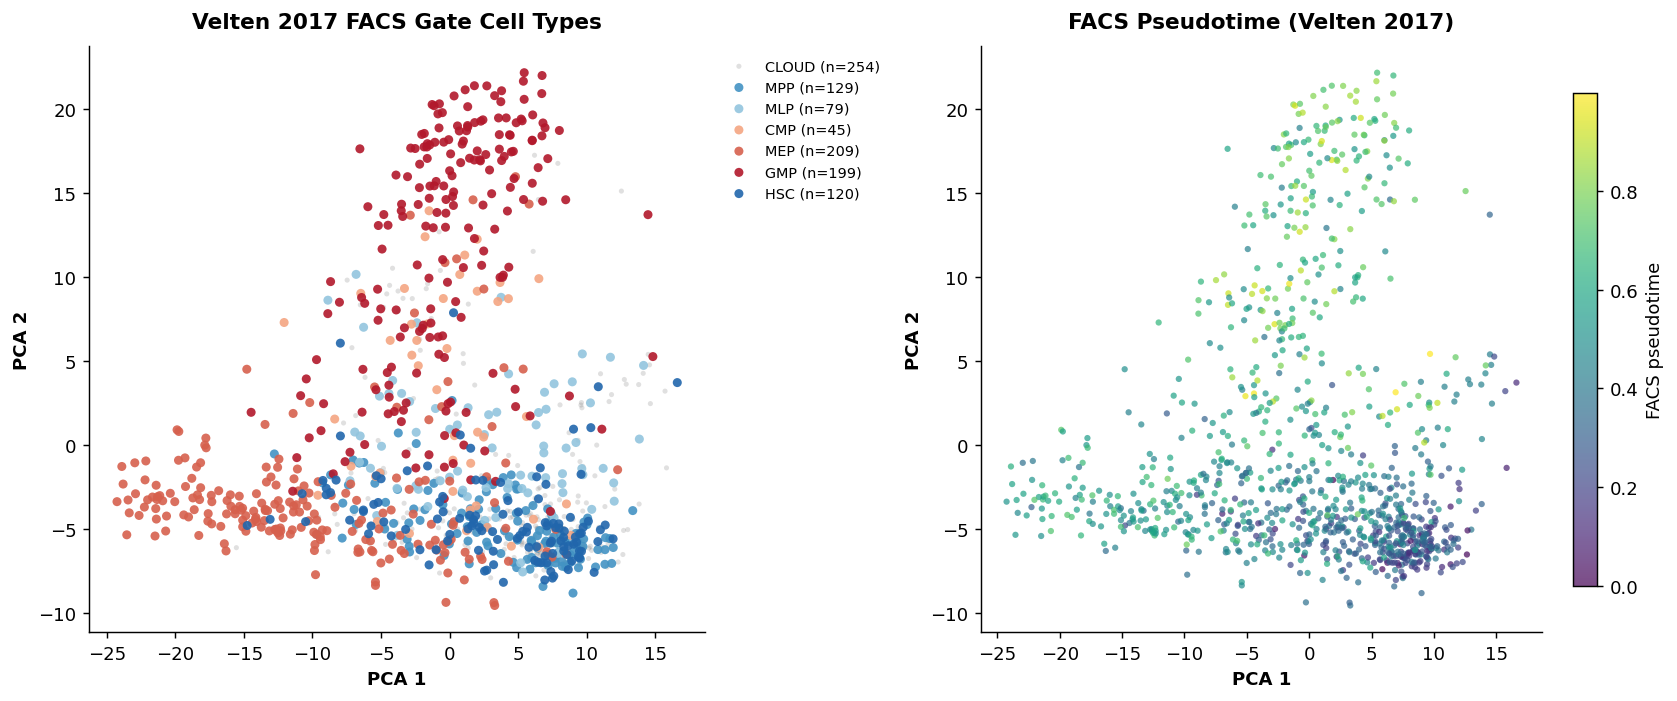

Saved: bert_grn_out_624_4/velocity_streamlines_pca.png


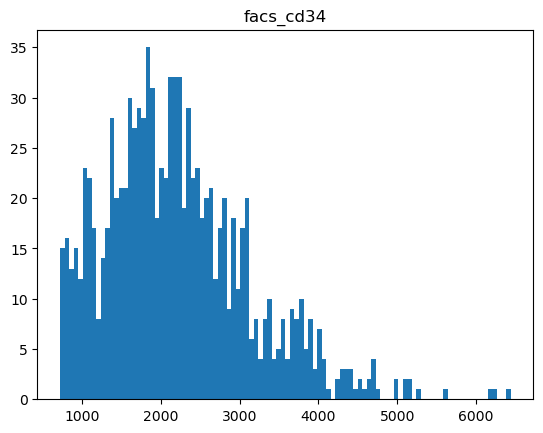

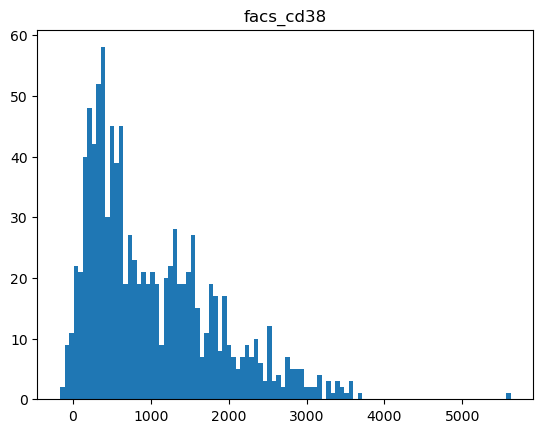

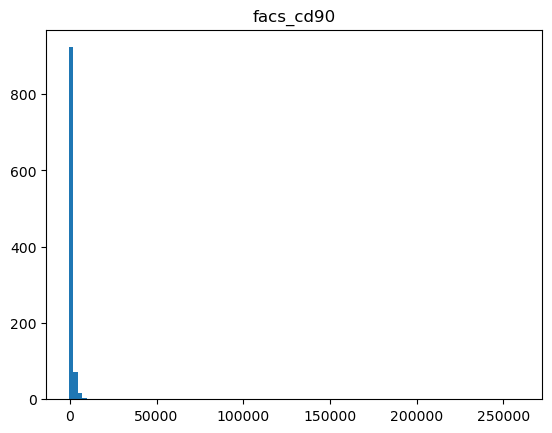

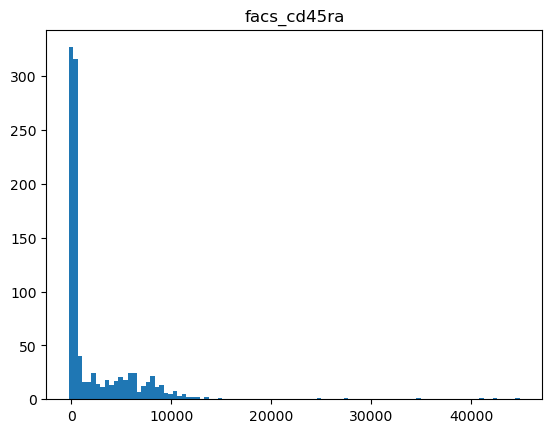

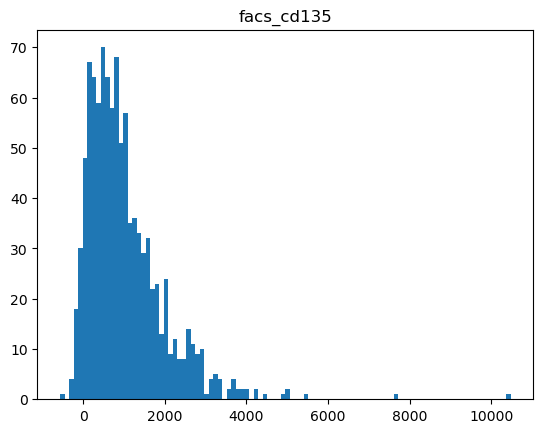

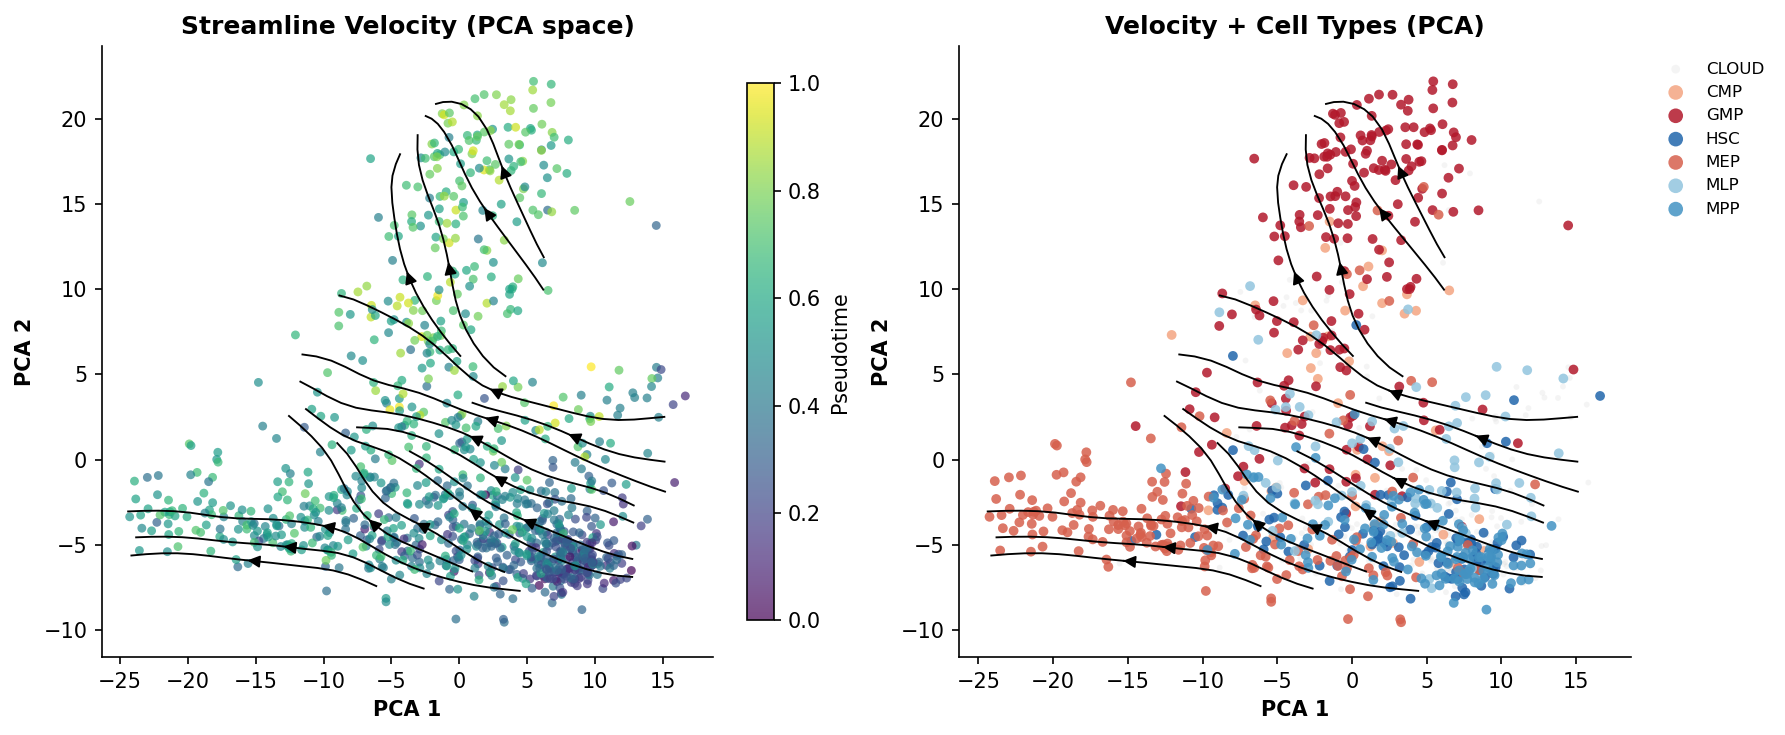

In [159]:
def assign_velten_celltypes(rna_adata, V_dec2, X_full, gene_to_idx_full,
                             base_path=OUTPUT_DIR):
    """
    Velten 2017 cell type assignment via FACS gates + marker gene rescue.
    Returns cell_types (N,) array of string labels.
    """
    obs = rna_adata.obs.copy()
    N   = len(obs)

    # ── Marker gene scoring ──────────────────────────────────────────────────
    MARKER_GENES = {
        'HSC': ['CD34', 'THY1', 'PROM1', 'ITGA6'],
        'MPP': ['CD34', 'FLT3', 'GATA2'],
        'MLP': ['CD34', 'IL7R', 'FLT3', 'DNTT'],
        'CMP': ['CD34', 'FLT3', 'CSF1R', 'CEBPA'],
        'MEP': ['GATA1', 'GATA2', 'KLF1', 'EPOR', 'GYPA'],
        'GMP': ['MPO', 'ELANE', 'SPI1', 'LYZ', 'CEBPA'],
    }
    scores = {}
    for ct, markers in MARKER_GENES.items():
        s = np.zeros(N, dtype=np.float32)
        n_found = 0
        for gene in markers:
            if gene in gene_to_idx_full:
                expr   = X_full[:, gene_to_idx_full[gene]].astype(np.float32)
                expr_z = (np.log1p(expr) - np.log1p(expr).mean()) / (np.log1p(expr).std() + 1e-8)
                s += expr_z; n_found += 1
        scores[ct] = s / n_found if n_found > 0 else s
    score_df = pd.DataFrame(scores)

    # ── FACS gates — calibrated thresholds ──────────────────────────────────
    def q_gate(col, pct, above=True):
        if col not in obs.columns: return np.zeros(N, dtype=bool)
        thresh = obs[col].quantile(pct / 100)
        return (obs[col] > thresh) if above else (obs[col] <= thresh)

    lin_neg    = q_gate('facs_lin',    30, False)
    cd34_pos   = q_gate('facs_cd34',   40, True)
    cd38_lo    = q_gate('facs_cd38',   33, False)
    cd38_hi    = q_gate('facs_cd38',   50, True)
    cd90_pos   = q_gate('facs_cd90',   50, True)
    cd135_pos  = q_gate('facs_cd135',  40, True)
    cd135_neg  = q_gate('facs_cd135',  40, False)
    cd45ra_pos = q_gate('facs_cd45ra', 50, True)
    cd45ra_neg = q_gate('facs_cd45ra', 50, False)

    cell_types = np.full(N, 'CLOUD', dtype=object)
    base = lin_neg & cd34_pos
    cell_types[base & cd38_hi & cd45ra_pos]                     = 'GMP'
    cell_types[base & cd38_hi & cd135_neg & cd45ra_neg]         = 'MEP'
    cell_types[base & cd38_hi & cd135_pos & cd45ra_neg]         = 'CMP'
    cell_types[base & cd38_lo & cd45ra_pos]                     = 'MLP'
    cell_types[base & cd38_lo & ~cd90_pos & cd45ra_neg]         = 'MPP'
    cell_types[base & cd38_lo & cd90_pos  & cd45ra_neg]         = 'HSC'

    # ── Marker rescue for remaining CLOUD cells ──────────────────────────────
    SCORE_THRESHOLD = 0.5
    cloud_idx  = np.where(cell_types == 'CLOUD')[0]
    best_ct    = score_df.values[cloud_idx].argmax(axis=1)
    best_score = score_df.values[cloud_idx].max(axis=1)
    ct_names   = list(score_df.columns)
    for ci, bct, bsc in zip(cloud_idx, best_ct, best_score):
        if bsc > SCORE_THRESHOLD:
            cell_types[ci] = ct_names[bct]

    print("Cell type counts (FACS gates + marker rescue):")
    unique, counts = np.unique(cell_types, return_counts=True)
    for u, c in sorted(zip(unique, counts), key=lambda x: -x[1]):
        print(f"  {u:<8}: {c}")

    # ── Plot ─────────────────────────────────────────────────────────────────
    palette = {'HSC':'#2166AC','MPP':'#4393C3','MLP':'#92C5DE',
               'CMP':'#F4A582','MEP':'#D6604D','GMP':'#B2182B','CLOUD':'#666565'}
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), dpi=130)

    ax = axes[0]
    for ct in ['CLOUD','MPP','MLP','CMP','MEP','GMP','HSC']:
        mask = cell_types == ct
        if not mask.any(): continue
        ax.scatter(V_dec2[mask,0], V_dec2[mask,1],
                   c=palette.get(ct,'#999'), s=8 if ct=='CLOUD' else 25,
                   alpha=0.2 if ct=='CLOUD' else 0.9,
                   label=f'{ct} (n={mask.sum()})', edgecolors='none', rasterized=True)
    ax.set_xlabel(f'{space_label_disp} 1', fontweight='bold')
    ax.set_ylabel(f'{space_label_disp} 2', fontweight='bold')
    ax.set_title('Velten 2017 FACS Gate Cell Types', fontweight='bold', pad=10)
    ax.legend(bbox_to_anchor=(1.01,1), loc='upper left', frameon=False, fontsize=8)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

    pseudo_vals = obs['facs_pseudotime'].values if 'facs_pseudotime' in obs.columns else None
    if pseudo_vals is not None:
        sc_p = axes[1].scatter(V_dec2[:,0], V_dec2[:,1], c=pseudo_vals,
                               cmap='viridis', s=12, alpha=0.7,
                               edgecolors='none', rasterized=True)
        plt.colorbar(sc_p, ax=axes[1], label='FACS pseudotime', fraction=0.04)
        axes[1].set_xlabel(f'{space_label_disp} 1', fontweight='bold')
        axes[1].set_ylabel(f'{space_label_disp} 2', fontweight='bold')
        axes[1].set_title('FACS Pseudotime (Velten 2017)', fontweight='bold', pad=10)
        axes[1].spines['top'].set_visible(False); axes[1].spines['right'].set_visible(False)

    plt.tight_layout()
    plt.savefig(f"{base_path}/velten_celltypes.png", dpi=150, bbox_inches='tight')
    plt.show()

    for marker in [
        'facs_cd34',
        'facs_cd38',
        'facs_cd90',
        'facs_cd45ra',
        'facs_cd135'
    ]:
        plt.figure()
        plt.hist(obs[marker], bins=100)
        plt.title(marker)
        
    return cell_types


cell_types = assign_velten_celltypes(rna_adata, X_2d_disp, X_full, gene_to_idx_full)
rna_adata.obs['velten_gate_celltype'] = cell_types

# Replot velocity with cell type overlay
plot_velocity_streamlines(X_2d_target, V_smooth, all_weights,
                          cell_types=cell_types, space_label=space_label,
                          U_precomputed=U_grid, V_precomputed=V_grid,
                          gx_precomputed=gx, gy_precomputed=gy)

Cell type counts (Velten 2017 faithful gating):
  CLOUD   :   327  (31.6%)
  MEP     :   187  (18.1%)
  GMP     :   149  (14.4%)
  HSC     :   129  (12.5%)
  MLP     :   109  (10.5%)
  MPP     :    97  (9.4%)
  CMP     :    37  (3.6%)


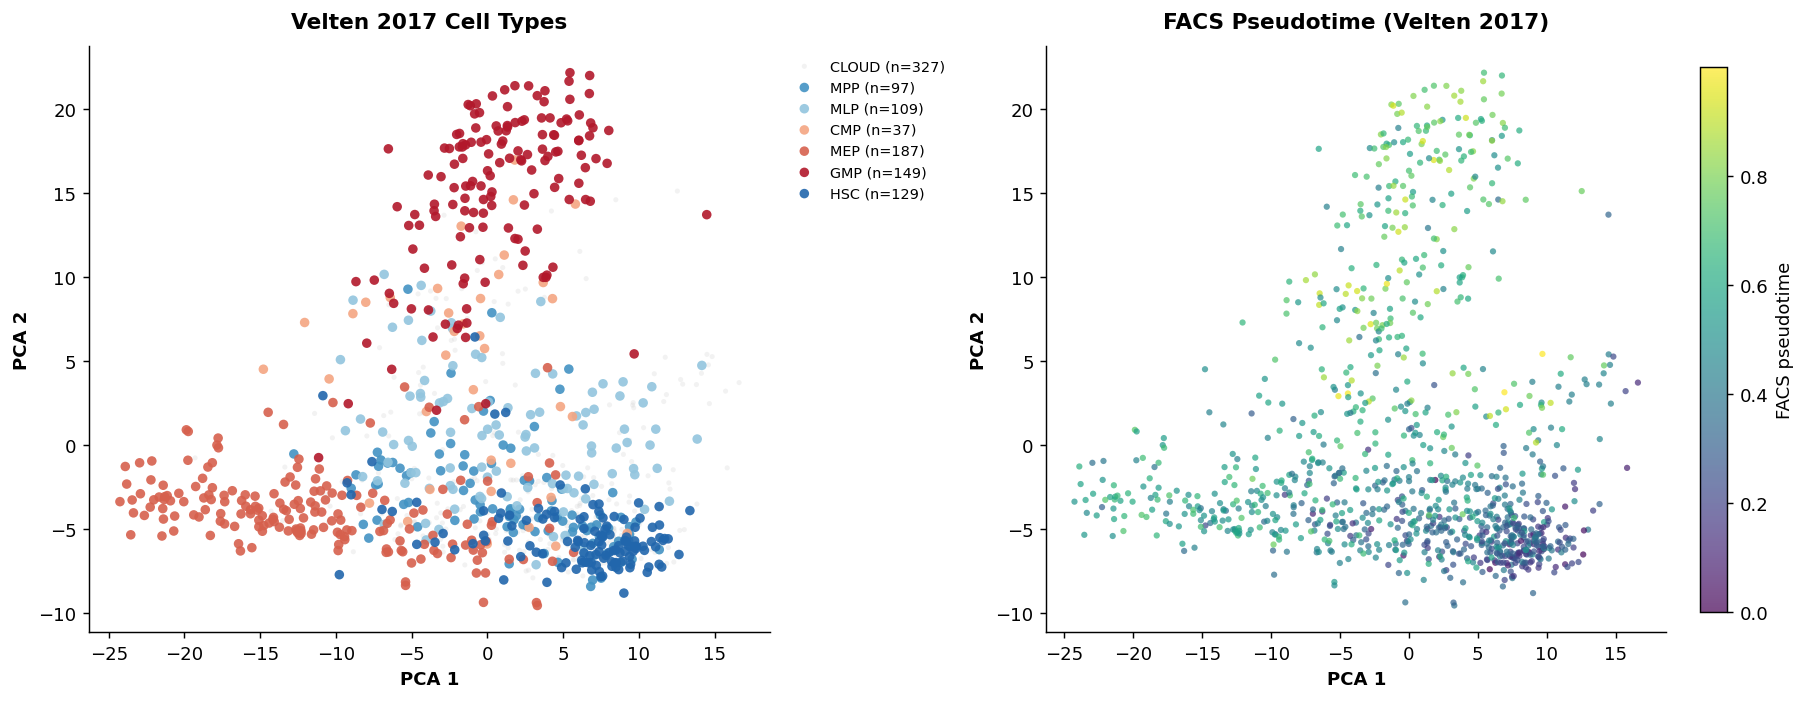

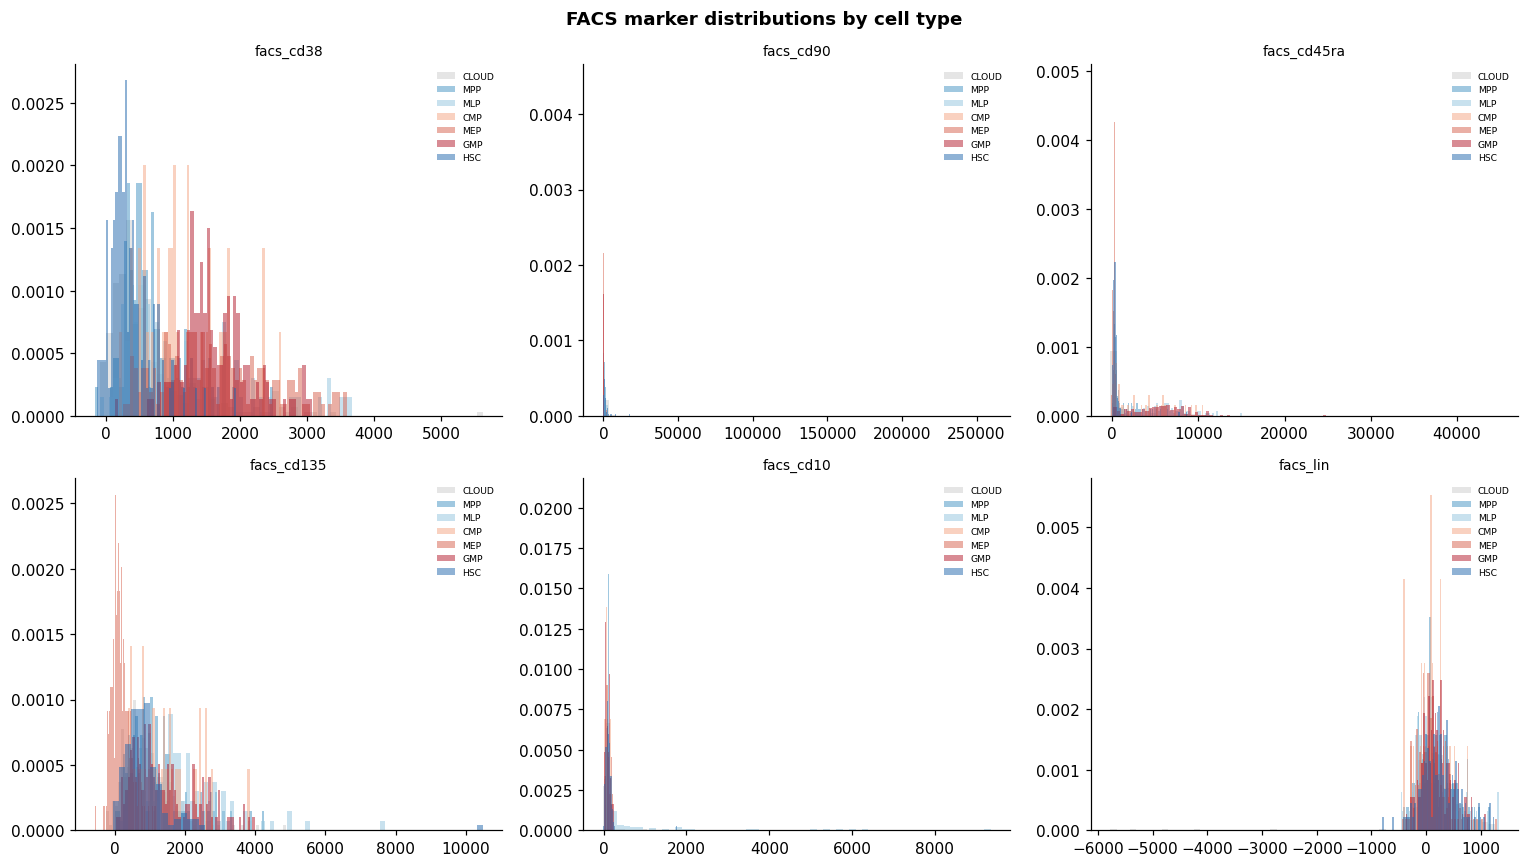

Saved: bert_grn_out_624_4/velocity_streamlines_pca.png


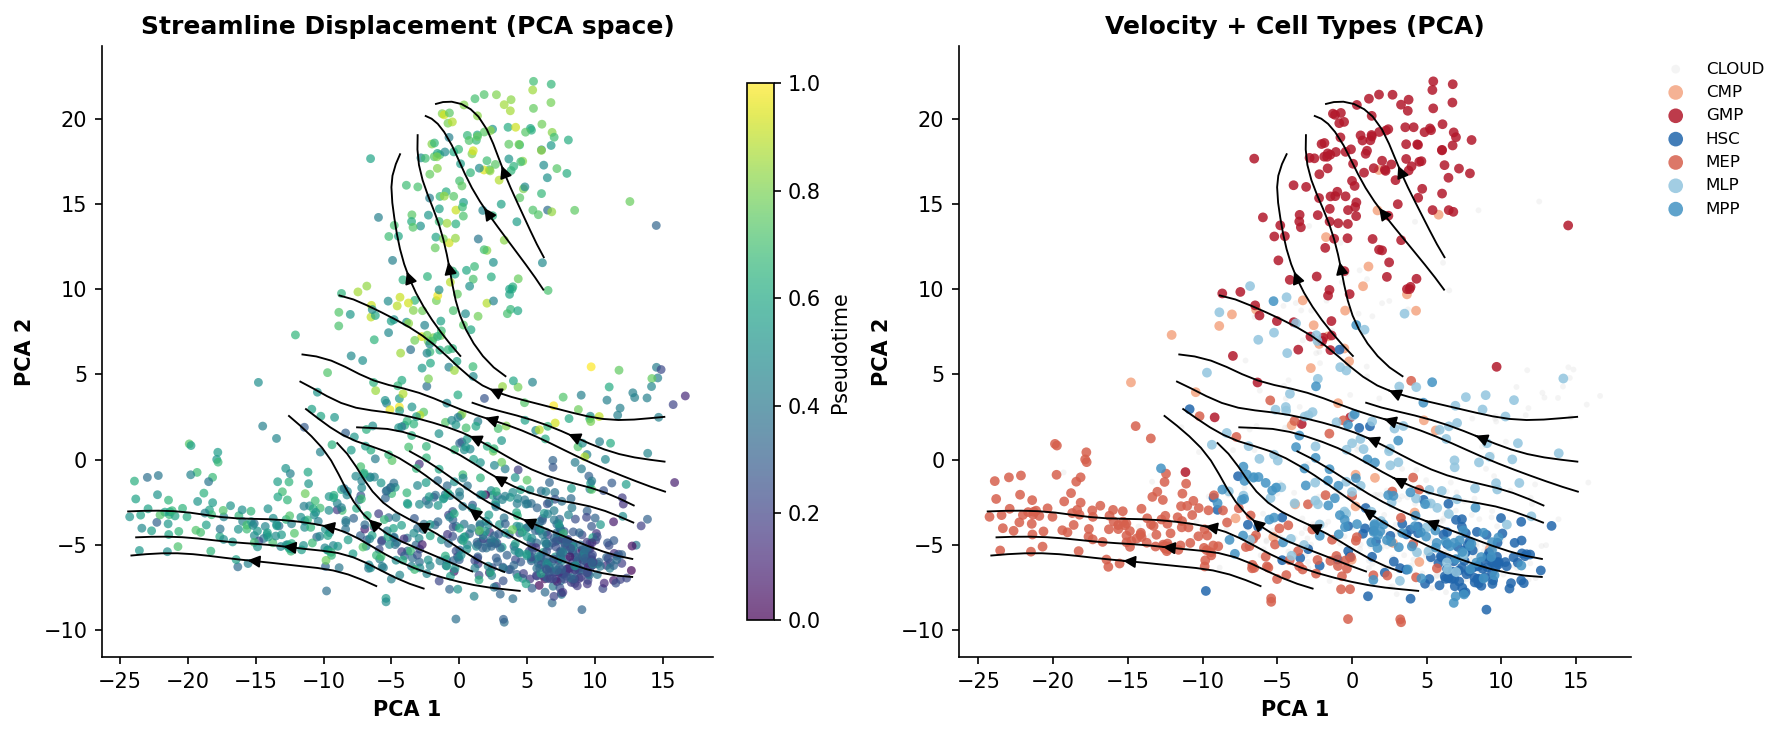

In [164]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata
 
 
# ─── Marker genes from Fig 3a / Supplementary Table 2 ────────────────────────
# These are the genes the paper reports as defining each CD38+ population.
# For the CD38- immunophenotypic sub-populations (HSC/MPP/MLP) we use the
# markers described in Methods and Supplementary Table 1.
VELTEN_MARKER_GENES = {
    # CD38- sub-populations (immunophenotypic, within the CLOUD continuum)
    'HSC' : ['HOXA3', 'PRDM16', 'HOXB6', 'CD90', 'MECOM',          # Fig 8 stem modules
             'HLF', 'ZFP36L2', 'MLLT3'],
    'MPP' : ['FLT3', 'SATB1', 'GATA2', 'NFE2'],                     # Fig 8 early priming
    'MLP' : ['IL7R', 'DNTT', 'FLT3', 'IRF1', 'CASP1'],             # Fig 8avi B/lymphoid
 
    # CD38+ lineage-restricted progenitors (Fig 3a, Supp Table 2)
    'MEP' : ['KLF1', 'MYC', 'GATA1', 'GYPA', 'HBB', 'HBP1',       # E1/E2/ME/Mk overlap
             'GATA2', 'TAL1', 'GP1BB', 'PBX1', 'ITGA2B'],
    'GMP' : ['MPO', 'ELANE', 'SPI1', 'CEBPA', 'CEBPB', 'CEBPE',   # N0-N3 + Mono/DC
             'RNASE2', 'AZU1', 'LYZ', 'IRF8', 'IRF7'],
    'CMP' : ['CSF1R', 'GATA2', 'NFE2', 'FLT3', 'CEBPA'],           # Im populations
}
 
 
def _rank_gate(x: np.ndarray) -> np.ndarray:
    """Convert raw FACS values to [0,1] rank fractions."""
    return rankdata(x, method='average') / len(x)
 
 
def _marker_scores(obs_index, X_full, gene_to_idx_full,
                   marker_dict=None):
    """
    Compute per-cell z-scored marker gene sum for each cell type.
    Returns a DataFrame (n_cells × n_celltypes).
    """
    if marker_dict is None:
        marker_dict = VELTEN_MARKER_GENES
    N = X_full.shape[0]
    scores = {}
    for ct, markers in marker_dict.items():
        s = np.zeros(N, dtype=np.float32)
        n_found = 0
        for gene in markers:
            if gene in gene_to_idx_full:
                expr = np.asarray(X_full[:, gene_to_idx_full[gene]],
                                  dtype=np.float32).ravel()
                log_expr = np.log1p(expr)
                z = (log_expr - log_expr.mean()) / (log_expr.std() + 1e-8)
                s += z
                n_found += 1
        scores[ct] = s / max(n_found, 1)
    return pd.DataFrame(scores, index=obs_index)
 
 
def assign_velten_celltypes(rna_adata, V_dec2, X_full, gene_to_idx_full,
                            base_path='.', rescue_cloud=False,
                            rescue_score_threshold=0.5):
    """
    Velten 2017 faithful cell type assignment.
 
    Parameters
    ----------
    rna_adata : AnnData
        Must have obs columns: facs_cd38, facs_cd90, facs_cd45ra, facs_cd135,
        facs_cd10 (if available), facs_lin (lineage).
        Also uses facs_pseudotime if present for the second plot panel.
    V_dec2 : np.ndarray  (N, 2)
        2-D embedding coordinates for plotting.
    X_full : array-like  (N, G)
        Full gene expression matrix (raw or normalised counts).
    gene_to_idx_full : dict
        Maps gene symbol → column index in X_full.
    base_path : str
        Directory for saving output figures.
    rescue_cloud : bool
        If True, CLOUD cells with a strong marker-gene signal are re-typed.
        Default False – the paper treats CLOUD as an undifferentiated continuum.
    rescue_score_threshold : float
        Z-score threshold used when rescue_cloud=True.
 
    Returns
    -------
    cell_types : np.ndarray of str, shape (N,)
    """
    obs = rna_adata.obs.copy()
    N   = len(obs)
 
    # ── 0. Verify required columns ────────────────────────────────────────────
    required = ['facs_cd38', 'facs_cd90', 'facs_cd45ra', 'facs_cd135']
    missing  = [c for c in required if c not in obs.columns]
    if missing:
        raise ValueError(f"Missing FACS columns: {missing}")
 
    # ── 1. Rank-transform FACS markers ───────────────────────────────────────
    # Rank-transformation makes thresholds robust to batch / scale differences.
    cd38_r   = _rank_gate(obs['facs_cd38'].values)
    cd90_r   = _rank_gate(obs['facs_cd90'].values)
    cd45ra_r = _rank_gate(obs['facs_cd45ra'].values)
    cd135_r  = _rank_gate(obs['facs_cd135'].values)
    cd10_r   = (_rank_gate(obs['facs_cd10'].values)
                if 'facs_cd10' in obs.columns
                else np.zeros(N))
 
    # ── 2. Primary compartment split: CD38- vs CD38+ ─────────────────────────
    # Paper (page 3): "HSCs … are located in the Lin-CD34+CD38- compartment,
    # whereas more differentiated progenitors reside in the Lin-CD34+CD38+ compartment"
    # We use the 30th percentile rank as the CD38-low boundary, consistent with
    # a "CD38-negative" gate that captures the lower ~30% of CD38 expression.
    cd38_neg = cd38_r < 0.30   # CD38-  → CLOUD continuum
    cd38_pos = cd38_r >= 0.30  # CD38+  → restricted progenitors
 
    # ── 3. Gate CD38- sub-populations ────────────────────────────────────────
    # From Methods / Supplementary Table 1 (Doulatov et al. 2010 scheme):
    #   HSC : Lin-CD34+CD38-  CD90+  CD45RA-
    #   MLP : Lin-CD34+CD38-  CD45RA+              (CD10- or CD10+)
    #   MPP : Lin-CD34+CD38-  CD90-  CD45RA-  CD135-
    #   Everything else CD38- = CLOUD
 
    cd90_pos   = cd90_r   >= 0.70   # CD90+
    cd45ra_pos = cd45ra_r >= 0.70   # CD45RA+
    cd45ra_neg = cd45ra_r <  0.30   # CD45RA-
    cd135_neg  = cd135_r  <  0.30   # CD135-
 
    hsc_mask = cd38_neg & cd90_pos  & cd45ra_neg
    mlp_mask = cd38_neg & cd45ra_pos & ~hsc_mask
    mpp_mask = cd38_neg & ~cd90_pos & cd45ra_neg & cd135_neg & ~hsc_mask & ~mlp_mask
 
    # ── 4. Gate CD38+ restricted progenitors ─────────────────────────────────
    # From Fig 3c and Methods:
    #   MEP : CD38+  CD135-  CD45RA-  CD10-
    #   CMP : CD38+  CD135+  CD45RA-  CD10-    (immature myeloid)
    #   GMP : CD38+  CD135+  CD45RA+            (neutrophil + mono/DC primed)
    # Note: Eo/Baso/Mast fall in CD38+ CD10- CD45RA- CD135mid (Fig 3c),
    #       overlapping with CMP – we collapse them into CMP here as the paper
    #       notes they require CD10/FCER1A for clean separation.
 
    cd135_pos  = cd135_r  >= 0.60
    cd10_neg   = cd10_r   <  0.50   # CD10- (myeloid / erythroid side)
 
    mep_mask = cd38_pos & ~cd135_pos & cd45ra_neg & cd10_neg
    cmp_mask = cd38_pos &  cd135_pos & cd45ra_neg & cd10_neg
    gmp_mask = cd38_pos &  cd135_pos & cd45ra_pos
 
    # ── 5. Assemble cell_types array ─────────────────────────────────────────
    # Priority: named populations first; anything CD38- that doesn't hit a
    # specific sub-gate stays as CLOUD (the paper's default for the continuum).
    cell_types = np.full(N, 'CLOUD', dtype=object)
 
    # CD38- named sub-populations (still part of the continuum conceptually,
    # but immunophenotypically labelled as in Fig 5b)
    cell_types[mpp_mask] = 'MPP'
    cell_types[mlp_mask] = 'MLP'
    cell_types[hsc_mask] = 'HSC'
 
    # CD38+ restricted progenitors
    cell_types[mep_mask] = 'MEP'
    cell_types[cmp_mask] = 'CMP'
    cell_types[gmp_mask] = 'GMP'
 
    # ── 6. Marker-gene rescue (optional, off by default) ─────────────────────
    # The paper does NOT discretely type CLOUD cells; rescue is provided only
    # as a convenience for trajectory validation.
    score_df = _marker_scores(obs.index, X_full, gene_to_idx_full)
 
    if rescue_cloud:
        cloud_idx  = np.where(cell_types == 'CLOUD')[0]
        best_ct    = score_df.values[cloud_idx].argmax(axis=1)
        best_score = score_df.values[cloud_idx].max(axis=1)
        ct_names   = list(score_df.columns)
        for ci, bct, bsc in zip(cloud_idx, best_ct, best_score):
            if bsc > rescue_score_threshold:
                cell_types[ci] = ct_names[bct]
 
    # ── 7. Report counts ─────────────────────────────────────────────────────
    print("Cell type counts (Velten 2017 faithful gating):")
    unique, counts = np.unique(cell_types, return_counts=True)
    for u, c in sorted(zip(unique, counts), key=lambda x: -x[1]):
        print(f"  {u:<8}: {c:>5}  ({100*c/N:.1f}%)")
 
    # ── 8. Plot ───────────────────────────────────────────────────────────────
    palette = {
        'HSC'  : '#2166AC',
        'MPP'  : '#4393C3',
        'MLP'  : '#92C5DE',
        'CMP'  : '#F4A582',
        'MEP'  : '#D6604D',
        'GMP'  : '#B2182B',
        'CLOUD': '#CCCCCC',
    }
    # CLOUD plotted first (background), named populations on top
    plot_order = ['CLOUD', 'MPP', 'MLP', 'CMP', 'MEP', 'GMP', 'HSC']
 
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=130)
 
    ax = axes[0]
    for ct in plot_order:
        mask = cell_types == ct
        if not mask.any():
            continue
        ax.scatter(V_dec2[mask, 0], V_dec2[mask, 1],
                   c=palette.get(ct, '#999999'),
                   s=8 if ct == 'CLOUD' else 28,
                   alpha=0.25 if ct == 'CLOUD' else 0.9,
                   label=f'{ct} (n={mask.sum()})',
                   edgecolors='none', rasterized=True)
    ax.set_xlabel(f'{space_label_disp} 1', fontweight='bold')
    ax.set_ylabel(f'{space_label_disp} 2', fontweight='bold')
    ax.set_title('Velten 2017 Cell Types',
                 fontweight='bold', pad=10)
    ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left',
              frameon=False, fontsize=8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
 
    pseudo_vals = (obs['facs_pseudotime'].values
                   if 'facs_pseudotime' in obs.columns else None)
    if pseudo_vals is not None:
        sc_p = axes[1].scatter(V_dec2[:, 0], V_dec2[:, 1],
                               c=pseudo_vals, cmap='viridis',
                               s=12, alpha=0.7,
                               edgecolors='none', rasterized=True)
        plt.colorbar(sc_p, ax=axes[1], label='FACS pseudotime', fraction=0.04)
        axes[1].set_xlabel(f'{space_label_disp} 1', fontweight='bold')
        axes[1].set_ylabel(f'{space_label_disp} 2', fontweight='bold')
        axes[1].set_title('FACS Pseudotime (Velten 2017)',
                          fontweight='bold', pad=10)
        axes[1].spines['top'].set_visible(False)
        axes[1].spines['right'].set_visible(False)
 
    plt.tight_layout()
    plt.savefig(f"{base_path}/velten_celltypes.png",
                dpi=150, bbox_inches='tight')
    plt.show()
 
    # Diagnostic: FACS marker distributions coloured by assigned cell type
    fig2, axes2 = plt.subplots(2, 3, figsize=(14, 8), dpi=110)
    marker_cols = ['facs_cd38', 'facs_cd90', 'facs_cd45ra',
                   'facs_cd135', 'facs_cd10', 'facs_lin']
    for ax2, col in zip(axes2.ravel(), marker_cols):
        if col not in obs.columns:
            ax2.set_visible(False)
            continue
        for ct in plot_order:
            mask = cell_types == ct
            if not mask.any():
                continue
            ax2.hist(obs.loc[mask, col], bins=60,
                     color=palette.get(ct, '#999'),
                     alpha=0.5, label=ct, density=True)
        ax2.set_title(col, fontsize=9)
        ax2.legend(fontsize=6, frameon=False)
        ax2.spines['top'].set_visible(False)
        ax2.spines['right'].set_visible(False)
    fig2.suptitle('FACS marker distributions by cell type', fontweight='bold')
    plt.tight_layout()
    plt.savefig(f"{base_path}/velten_facs_distributions.png",
                dpi=130, bbox_inches='tight')
    plt.show()
 
    return cell_types

cell_types = assign_velten_celltypes(rna_adata, X_2d_disp, X_full, gene_to_idx_full, rescue_cloud=True)

rna_adata.obs['velten_gate_celltype'] = cell_types

# Replot velocity with cell type overlay
plot_velocity_streamlines(X_2d_target, V_smooth, all_weights,
                          cell_types=cell_types, space_label=space_label,
                          U_precomputed=U_grid, V_precomputed=V_grid,
                          gx_precomputed=gx, gy_precomputed=gy)

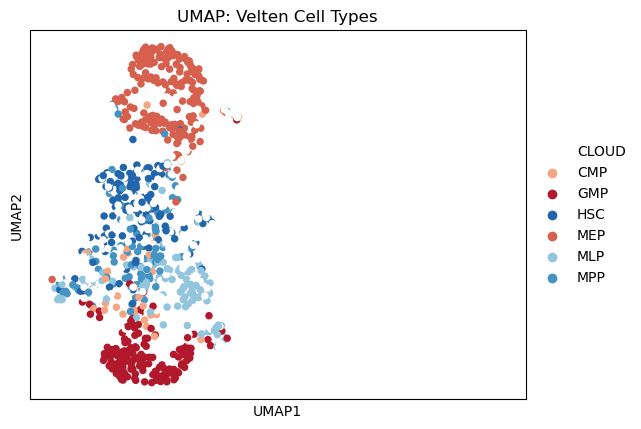

In [161]:
import scanpy as sc

# Define your palette, mapping the categories exactly
custom_palette = {
    'HSC'  : '#2166AC',
    'MPP'  : '#4393C3',
    'MLP'  : '#92C5DE',
    'CMP'  : '#F4A582',
    'MEP'  : '#D6604D',
    'GMP'  : '#B2182B',
    'CLOUD': 'white'    # Explicitly set to white (or '#FFFFFF')
}

sc.pl.umap(
    rna_adata, 
    color='velten_gate_celltype', 
    palette=custom_palette,
    title="UMAP: Velten Cell Types"
)

![png](output_49_0.png)
    



![png](output_49_0.png)
    




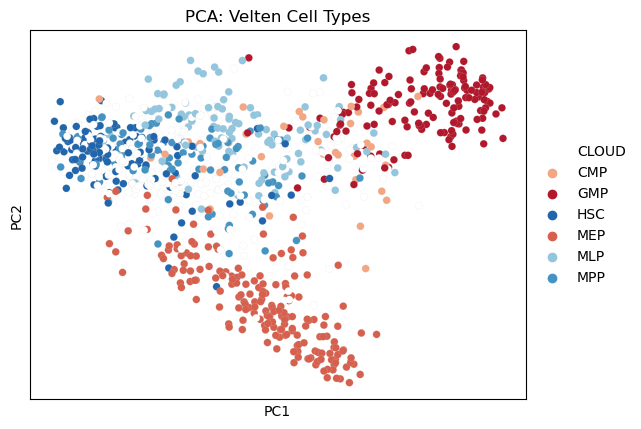

In [152]:
import scanpy as sc

# Define your palette, explicitly setting CLOUD to white
custom_palette = {
    'HSC'  : '#2166AC',
    'MPP'  : '#4393C3',
    'MLP'  : '#92C5DE',
    'CMP'  : '#F4A582',
    'MEP'  : '#D6604D',
    'GMP'  : '#B2182B',
    'CLOUD': 'white'    # Or 'whitesmoke' if it blends into the background too much
}

# Optional: If you haven't calculated PCA on this object yet, uncomment the line below
# sc.pp.pca(rna_adata)

sc.pl.pca(
    rna_adata, 
    color='velten_gate_celltype', 
    palette=custom_palette,
    edgecolor='lightgray', # Highly recommended when plotting white points
    linewidths=0.1,
    title="PCA: Velten Cell Types"
)

![png](output_52_0.png)
    

## Continuous Marker Expression


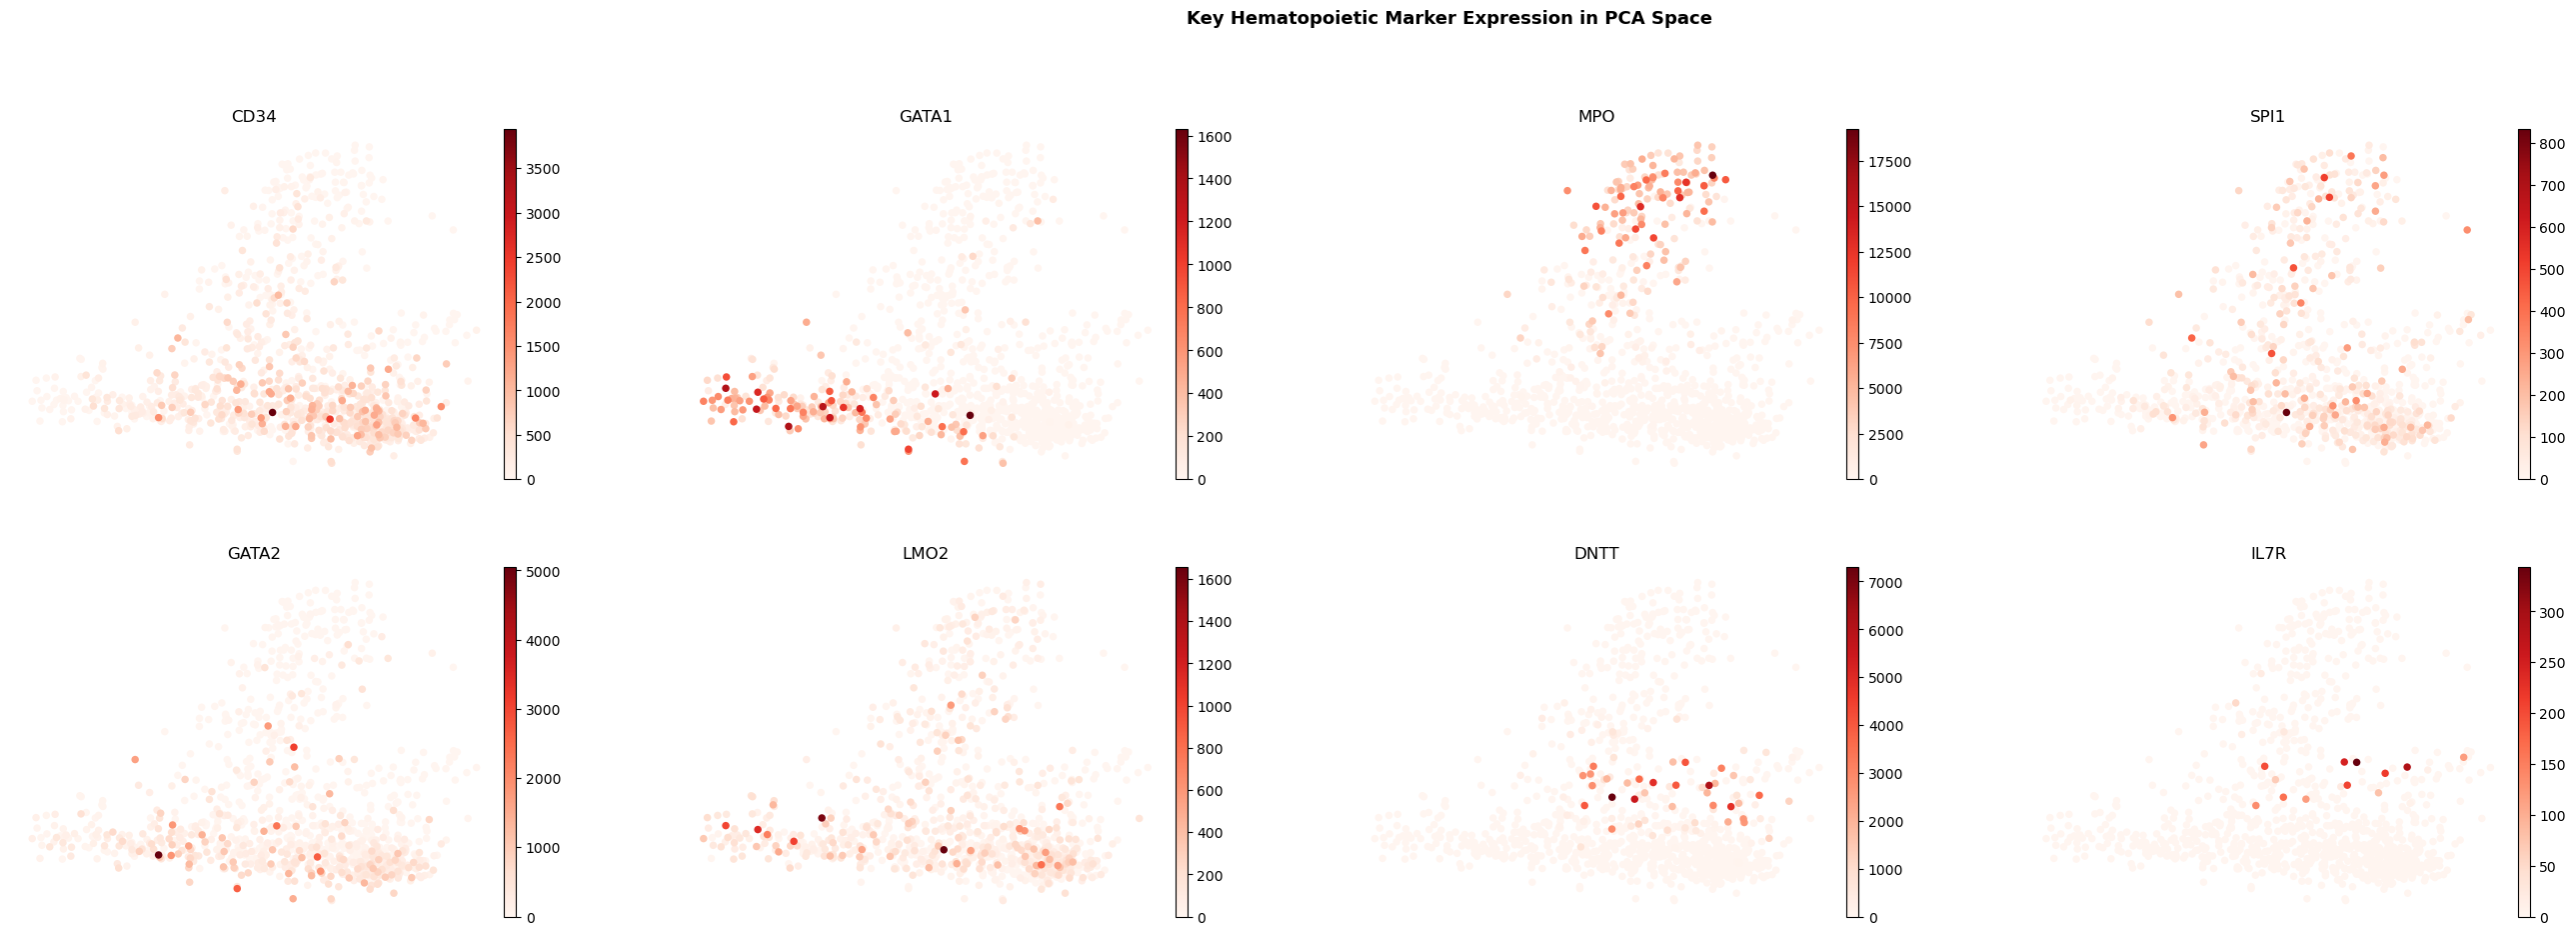

In [153]:
import scanpy as sc

key_genes  = ['CD34', 'GATA1', 'MPO', 'SPI1', 'GATA2', 'LMO2', 'DNTT', 'IL7R']
plot_genes = [g for g in key_genes if g in rna_adata.var_names]

# Store whichever 2D embedding is active so sc.pl.embedding uses the right space.
basis_key = f'X_{space_label_disp.lower()}'
rna_adata.obsm[basis_key] = X_2d_disp
fig = sc.pl.embedding(rna_adata, basis=basis_key, color=plot_genes,
                      cmap='Reds', frameon=False, ncols=4,
                      wspace=0.25, hspace=0.25, show=False, return_fig=True)
plt.suptitle(f'Key Hematopoietic Marker Expression in {space_label_disp} Space',
             fontsize=13, y=1.01, fontweight='bold')
plt.show()

Spearman(GRN entropy, |V_smooth|): rho=0.409, p=0.0000
(Positive rho = transition cells have higher velocity — expected ✓)
(Note: with ReLU kernel, committed cells have V=0, so rho should be strongly positive)


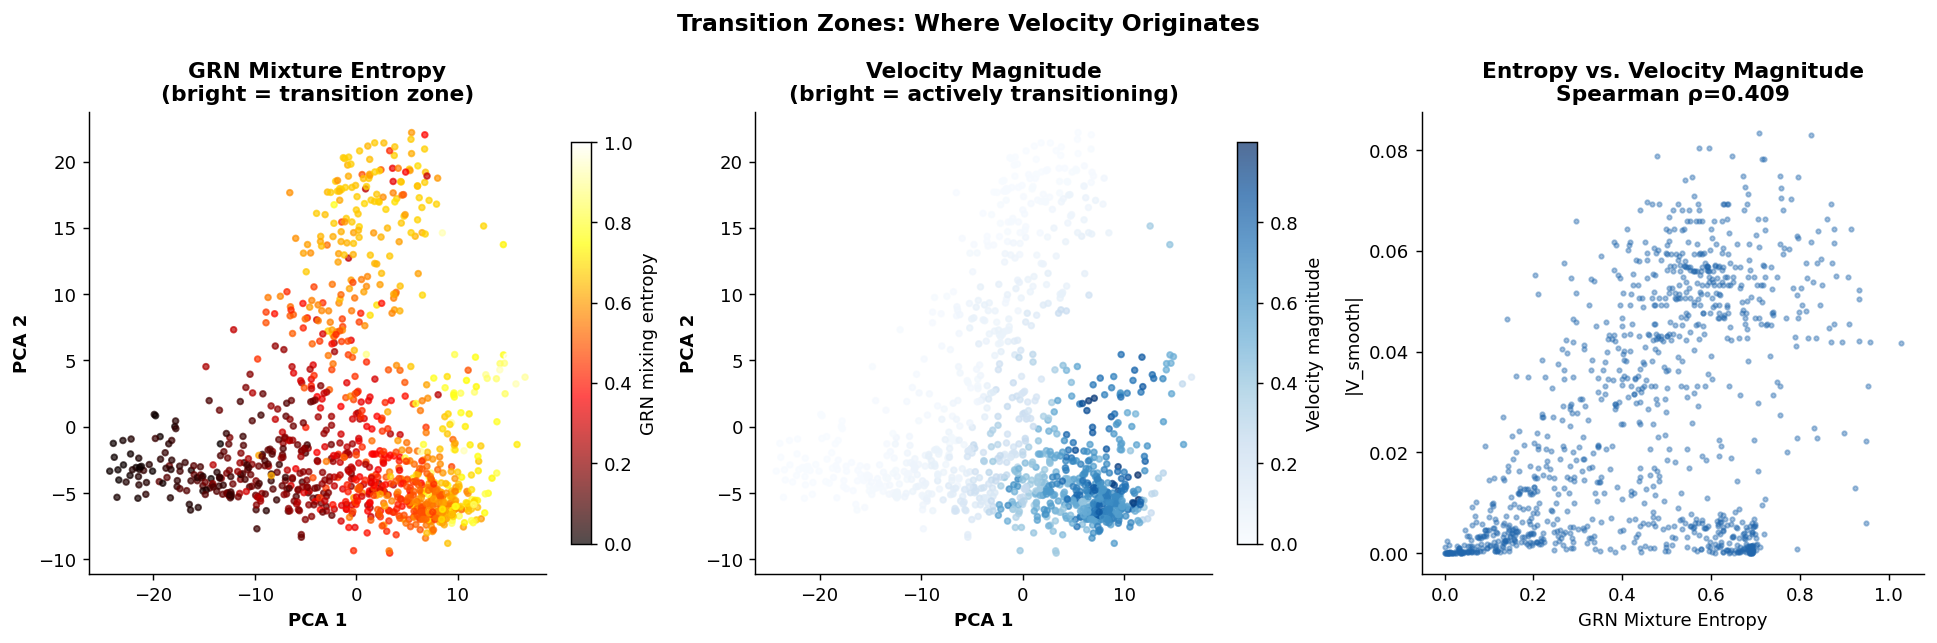

In [154]:
def analyze_transition_zones(all_weights, V_smooth, V_dec2, D_ATOMS,
                              base_path=OUTPUT_DIR):
    """
    Computes per-cell GRN mixture entropy and verifies:
    1. High-entropy cells cluster at boundaries between cell populations
    2. High-entropy cells have higher velocity magnitude (they are transitioning)
    """
    eps = 1e-8
    entropy = -(all_weights * np.log(all_weights + eps)).sum(axis=1)
    entropy_norm = (entropy - entropy.min()) / (entropy.max() - entropy.min() + eps)

    v_mag = np.linalg.norm(V_smooth, axis=1)
    v_mag_norm = (v_mag - v_mag.min()) / (v_mag.max() - v_mag.min() + eps)

    rho, p = spearmanr(entropy, v_mag)
    print(f"Spearman(GRN entropy, |V_smooth|): rho={rho:.3f}, p={p:.4f}")
    print("(Positive rho = transition cells have higher velocity — expected ✓)")
    print("(Note: with ReLU kernel, committed cells have V=0, so rho should be strongly positive)")

    fig, axes = plt.subplots(1, 3, figsize=(15, 5), dpi=130)

    sc0 = axes[0].scatter(V_dec2[:,0], V_dec2[:,1], c=entropy_norm,
                          cmap='hot', s=10, alpha=0.7, rasterized=True)
    plt.colorbar(sc0, ax=axes[0], fraction=0.04, label='GRN mixing entropy')
    axes[0].set_title('GRN Mixture Entropy\n(bright = transition zone)', fontweight='bold')

    sc1 = axes[1].scatter(V_dec2[:,0], V_dec2[:,1], c=v_mag_norm,
                          cmap='Blues', s=10, alpha=0.7, rasterized=True)
    plt.colorbar(sc1, ax=axes[1], fraction=0.04, label='Velocity magnitude')
    axes[1].set_title('Velocity Magnitude\n(bright = actively transitioning)',
                      fontweight='bold')

    axes[2].scatter(entropy, v_mag, s=6, alpha=0.4, c='#2166ac', rasterized=True)
    axes[2].set_xlabel('GRN Mixture Entropy'); axes[2].set_ylabel('|V_smooth|')
    axes[2].set_title(f'Entropy vs. Velocity Magnitude\nSpearman ρ={rho:.3f}',
                      fontweight='bold')
    axes[2].spines['top'].set_visible(False); axes[2].spines['right'].set_visible(False)

    for ax in axes[:2]:
        ax.set_xlabel(f'{space_label_disp} 1', fontweight='bold')
        ax.set_ylabel(f'{space_label_disp} 2', fontweight='bold')
        ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

    plt.suptitle('Transition Zones: Where Velocity Originates', fontsize=13,
                 fontweight='bold')
    plt.tight_layout()
    plt.savefig(f"{base_path}/transition_zones.png", dpi=150, bbox_inches='tight')
    plt.show()

    return entropy


entropy = analyze_transition_zones(all_weights, V_smooth, X_2d_disp, D_ATOMS)

![png](output_69_1.png)
    


    Spearman(GRN entropy, |V_smooth|): rho=-0.076, p=0.0140
    (Positive rho = transition cells have higher velocity — expected ✓)
    (Note: with ReLU kernel, committed cells have V=0, so rho should be strongly positive)



![png](output_62_1.png)
    


    Spearman(GRN entropy, |V_smooth|): rho=-0.064, p=0.0401
    (Positive rho = transition cells have higher velocity — expected ✓)
    (Note: with ReLU kernel, committed cells have V=0, so rho should be strongly positive)



![png](output_54_1.png)

---

## Step 14 — Inferred Pseudotime and Trajectory Gene Analysis

Pseudotime is the **geodesic potential φ** — Dijkstra shortest-path from the
root set on the ψ-uphill graph (`compute_geodesic_pseudotime`). As of the
2026-06-24 fix this is the *same* object the velocity field is built from in
Step 11, so the three outputs are consistent by construction: ψ supplies the
local ordering, φ integrates it into a monotone field, and the velocity arrows
are exactly ∇φ. There is no second, divergent ordering to drift out of sync.

**Why geodesic φ and not MFPT on `T_markov`:** `T_markov` is not doubly
stochastic — cells at potential-maxima (terminal states) have all-zero rows — so
the absorbing-chain solve `(I − T) pt = 1` is singular, and the out/in-degree
source heuristic fails there for the same reason. Dijkstra on the directed
ψ-uphill graph is acyclic (no singularity), handles disconnected regions
gracefully, and is mathematically equivalent to MFPT on a DAG.

**Root detection (label-free):** roots are the lowest `ROOT_PCT` (5%) of ψ. ψ is
constructed so `P[origin_atom] = −1`, hence ψ is minimal in the origin atom's
territory, so the root set lands on HSC/MPP with no label supervision.





Root cells (lowest 5.0% of ψ): n=52
  ψ threshold = 0.6401  (global ψ range: [0.4641, 1.0000])
  Root cell types: ['CLOUD' 'HSC' 'MPP']
  φ is gap-free (unreachable cells relaxed outward), so the velocity field has no zero-gradient plateau at the branch tips.


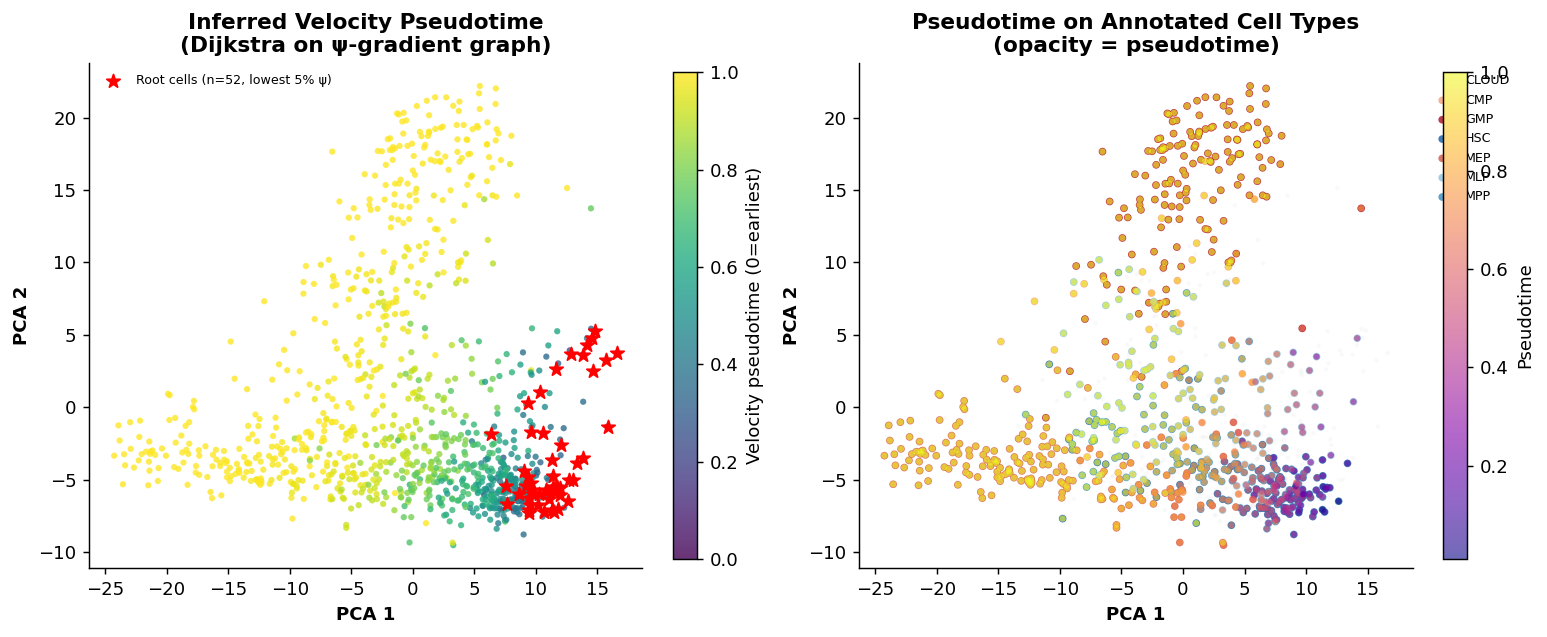


Correlation with FACS pseudotime (post-hoc check): Spearman ρ=0.594, p=0.0000
  Interpretation:
  ρ > 0.5 → pseudotime strongly recapitulates known ordering
  ρ > 0.3 → reasonable ordering, especially for branching trajectories
  ρ < 0.2 → velocity field may have wrong direction or poor resolution
  Note: FACS pseudotime is a 1D linear ordering. Our pseudotime captures
  branching, so ρ < 1.0 is expected — check the plot for branch structure.
  ✓ Purple/dark cells should overlap HSC/MPP.
  ✓ Yellow/bright cells should overlap GMP, MEP, MLP.
Analyzing trajectories: ['CMP', 'GMP', 'HSC', 'MEP', 'MLP', 'MPP']

HOW TO INTERPRET:
  Panel 1 (heatmap): left=early, right=late. Top rows should brighten left→right.
  Panel 2 (curves):  lineage markers should rise, stem genes fall.
  Panel 3 (spatial): top gene should be bright in the lineage region.
  Panel 4 (GT bar):  fraction of top-10 genes in known Velten 2017 markers.

── CMP ─────────────────────────────────────────────
  Top genes INCRE

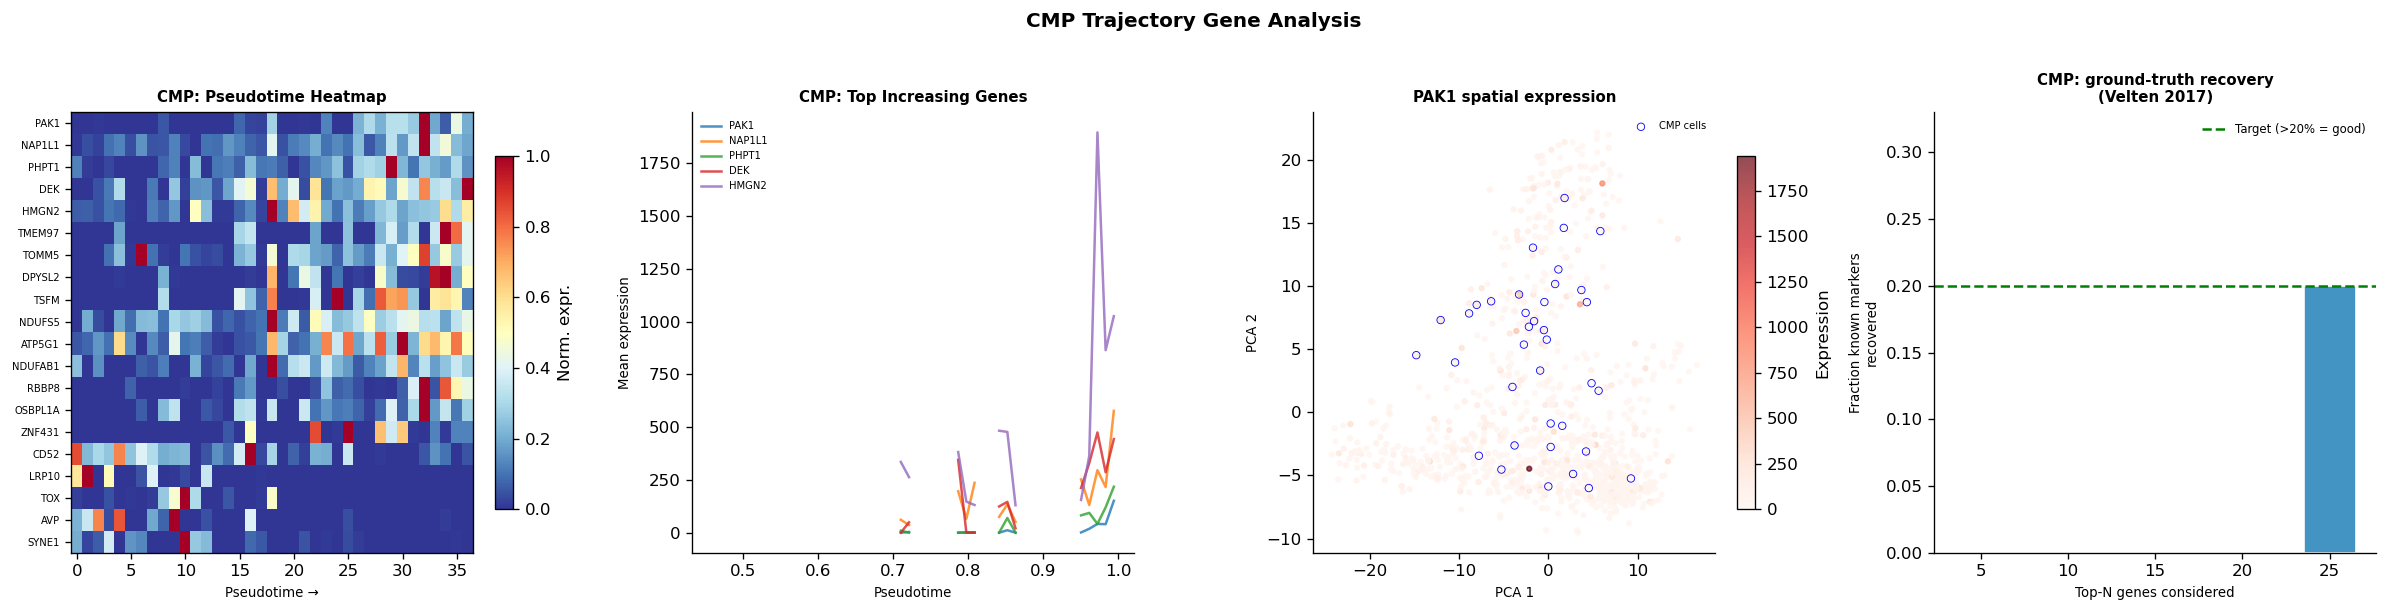


── GMP ─────────────────────────────────────────────
  Top genes INCREASING with pseudotime (should include lineage markers):
    PRTN3            ρ=0.729  ✓ KNOWN MARKER
    ELANE            ρ=0.729  ✓ KNOWN MARKER
    AZU1             ρ=0.696  ✓ KNOWN MARKER
    CST7             ρ=0.612  ✓ KNOWN MARKER
    CTSG             ρ=0.611  
    SRGN             ρ=0.557  
    RNASE3           ρ=0.549  
    MPO              ρ=0.514  ✓ KNOWN MARKER
    CALR             ρ=0.472  
    CSF3R            ρ=0.423  
  Top genes DECREASING (stem genes leaving):
    HLA-DRA          ρ=-0.424  
    FTH1             ρ=-0.421  
    H3F3B            ρ=-0.409  
    RNF130           ρ=-0.407  
    CD74             ρ=-0.403  
  ✓ Known markers recovered in top-10: [np.str_('PRTN3'), np.str_('ELANE'), np.str_('AZU1'), np.str_('CST7'), np.str_('MPO')]
  Ground-truth hit rate (top-25): 38.5%


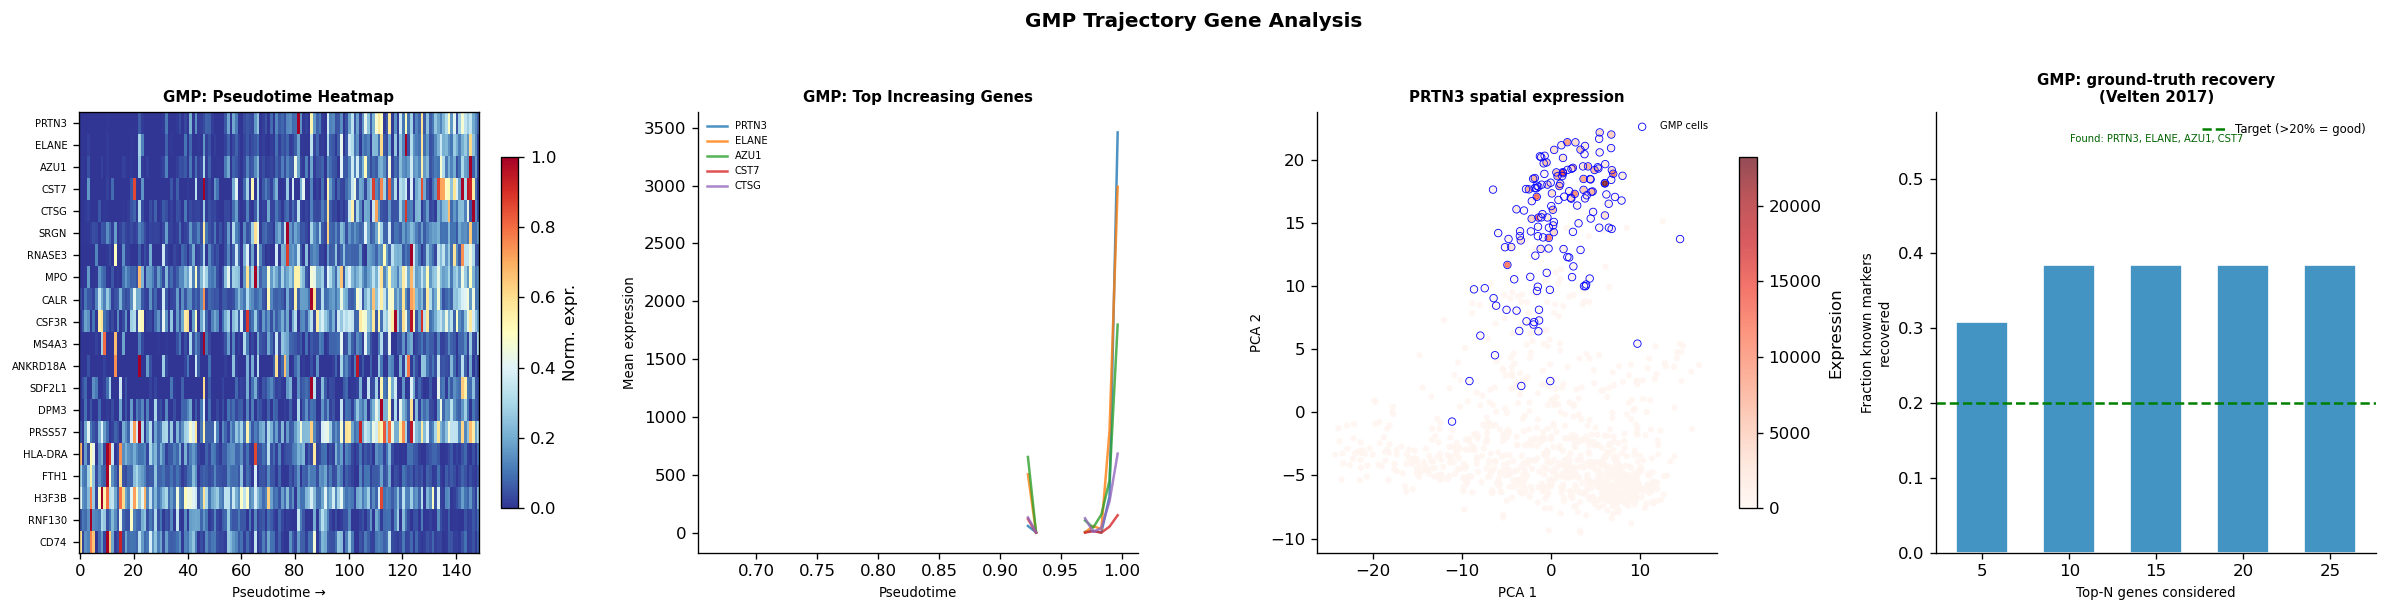


── HSC ─────────────────────────────────────────────
  Top genes INCREASING with pseudotime (should include lineage markers):
    STMN1            ρ=0.658  
    HMGN2            ρ=0.563  
    TUBA1B           ρ=0.552  
    MCM5             ρ=0.525  
    MCM4             ρ=0.524  
    MCM2             ρ=0.515  
    GAPDH            ρ=0.515  
    HELLS            ρ=0.505  
    LDHB             ρ=0.488  
    SNRPB            ρ=0.487  
  Top genes DECREASING (stem genes leaving):
    FOS              ρ=-0.580  
    DUSP1            ρ=-0.569  
    TSC22D3          ρ=-0.465  
    FOSB             ρ=-0.370  
    CD74             ρ=-0.364  
  ✓ Known markers recovered in top-10: []
  Ground-truth hit rate (top-25): 0.0%


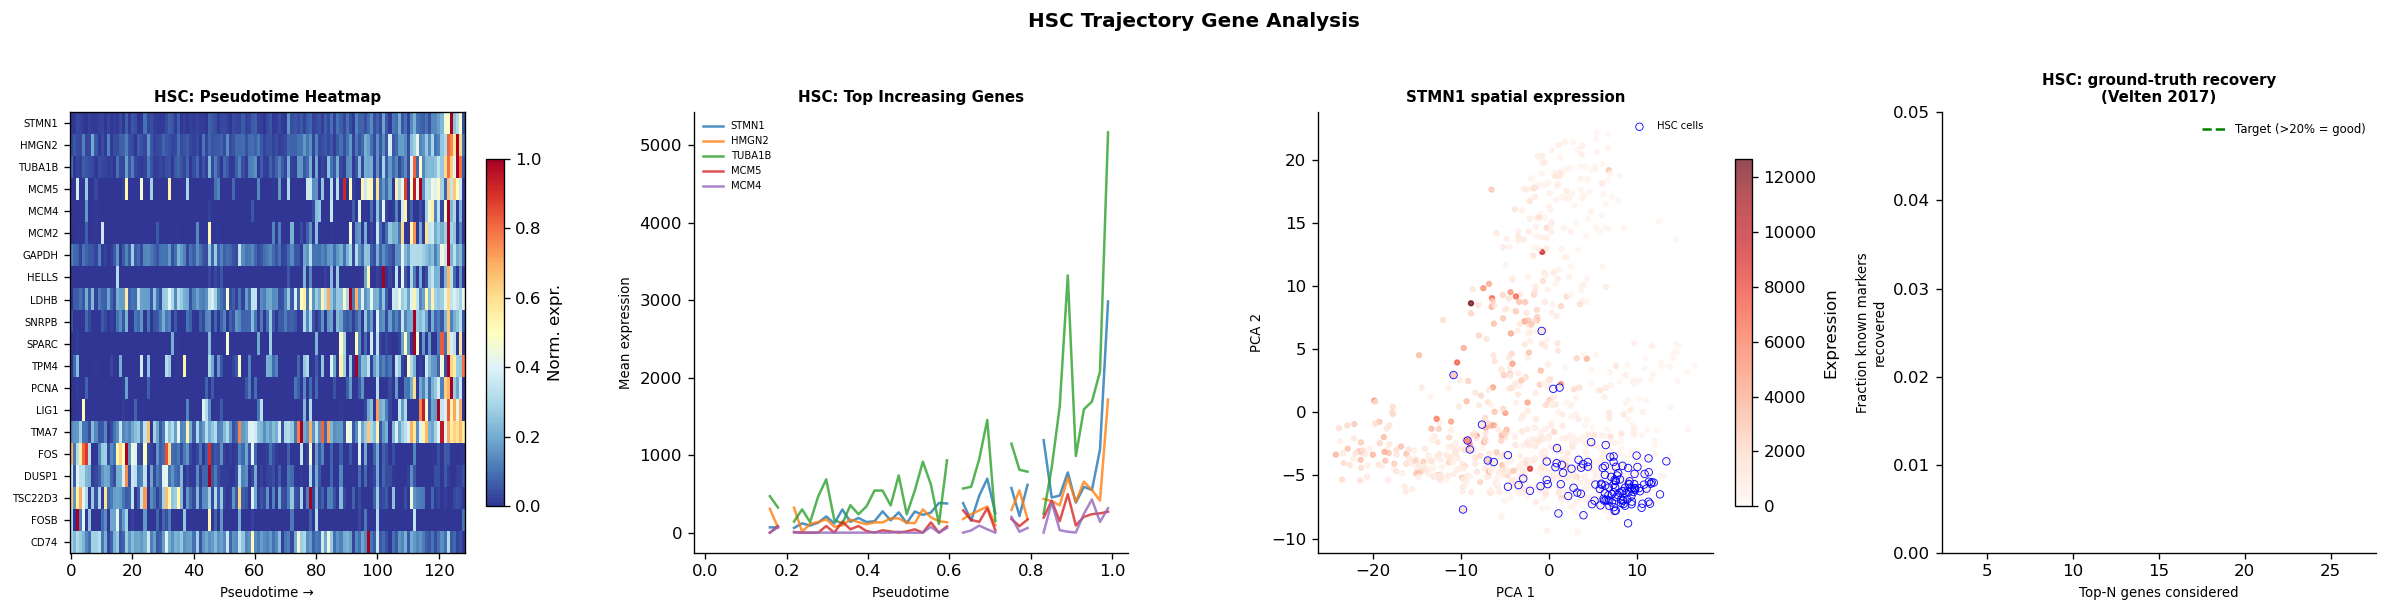


── MEP ─────────────────────────────────────────────
  Top genes INCREASING with pseudotime (should include lineage markers):
    TUBB             ρ=0.708  
    KIAA0101         ρ=0.704  
    TYMS             ρ=0.700  
    TUBA1B           ρ=0.692  
    SLC29A1          ρ=0.683  
    PCNA             ρ=0.682  
    FEN1             ρ=0.668  
    ATPIF1           ρ=0.666  
    BOLA3            ρ=0.661  
    MCM10            ρ=0.650  
  Top genes DECREASING (stem genes leaving):
    FCER1A           ρ=-0.629  
    HLA-E            ρ=-0.544  
    SERPINB1         ρ=-0.514  
    PLEK             ρ=-0.483  
    SOX4             ρ=-0.481  
  ✓ Known markers recovered in top-10: []
  Ground-truth hit rate (top-25): 15.4%


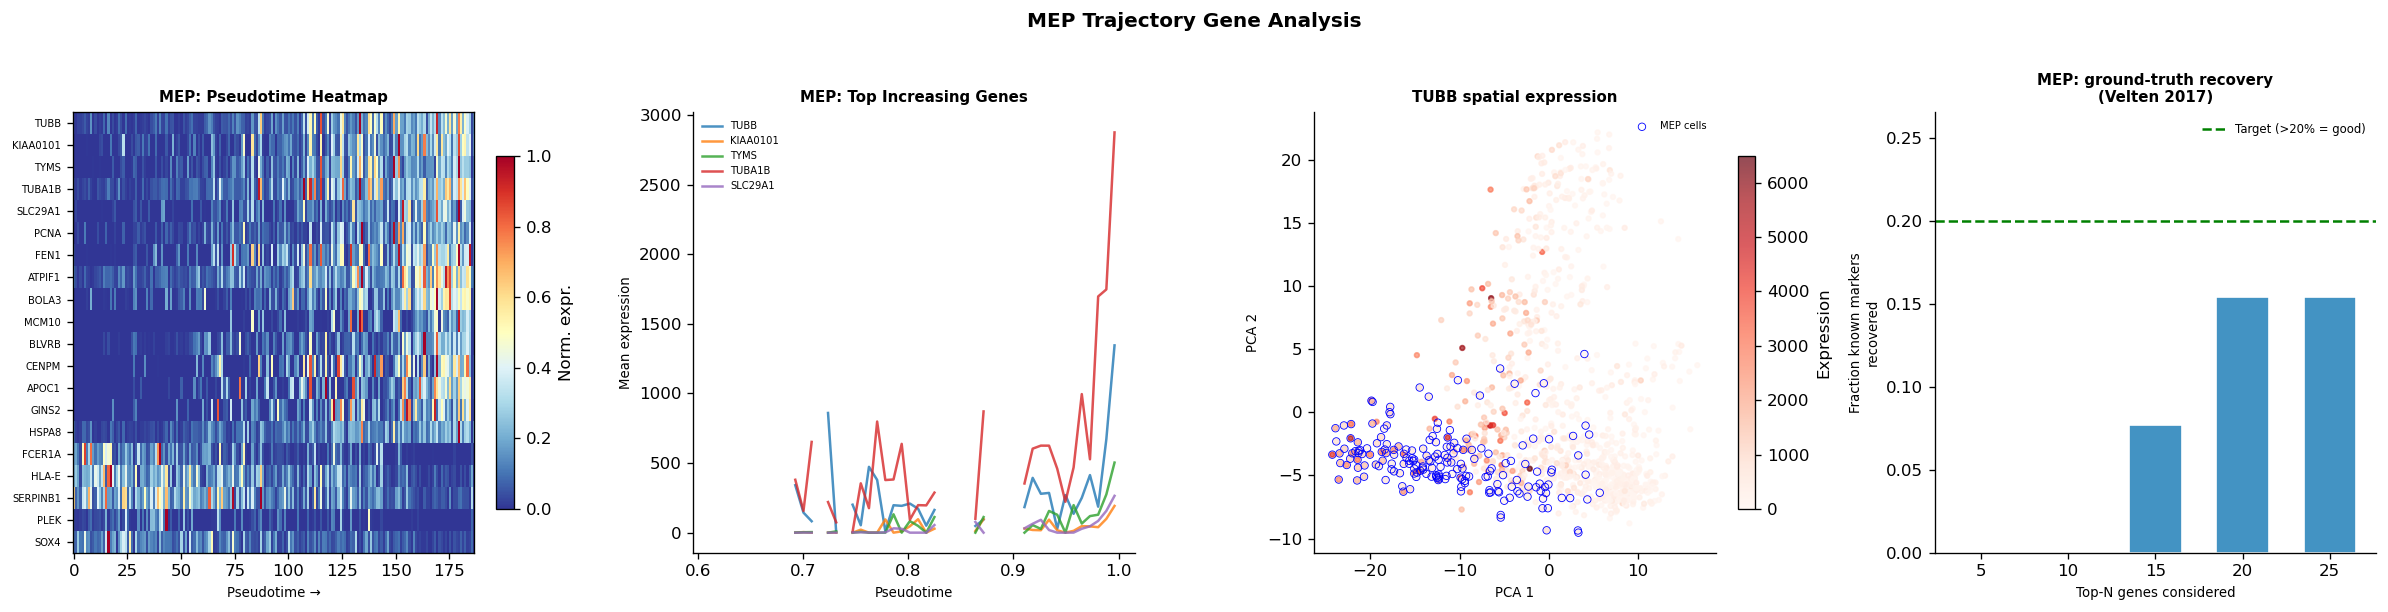


── MLP ─────────────────────────────────────────────
  Top genes INCREASING with pseudotime (should include lineage markers):
    TUBA1B           ρ=0.836  
    HMGN2            ρ=0.792  
    STMN1            ρ=0.772  
    H2AFZ            ρ=0.754  
    ASF1B            ρ=0.738  
    HMGB2            ρ=0.721  
    ZWINT            ρ=0.713  
    NUSAP1           ρ=0.710  
    RAN              ρ=0.691  
    TUBB             ρ=0.691  
  Top genes DECREASING (stem genes leaving):
    LTB              ρ=-0.378  
    CNTNAP2          ρ=-0.362  
    NEU1             ρ=-0.352  
    HOPX             ρ=-0.346  
    LIMD2            ρ=-0.345  
  ✓ Known markers recovered in top-10: []
  Ground-truth hit rate (top-25): 0.0%


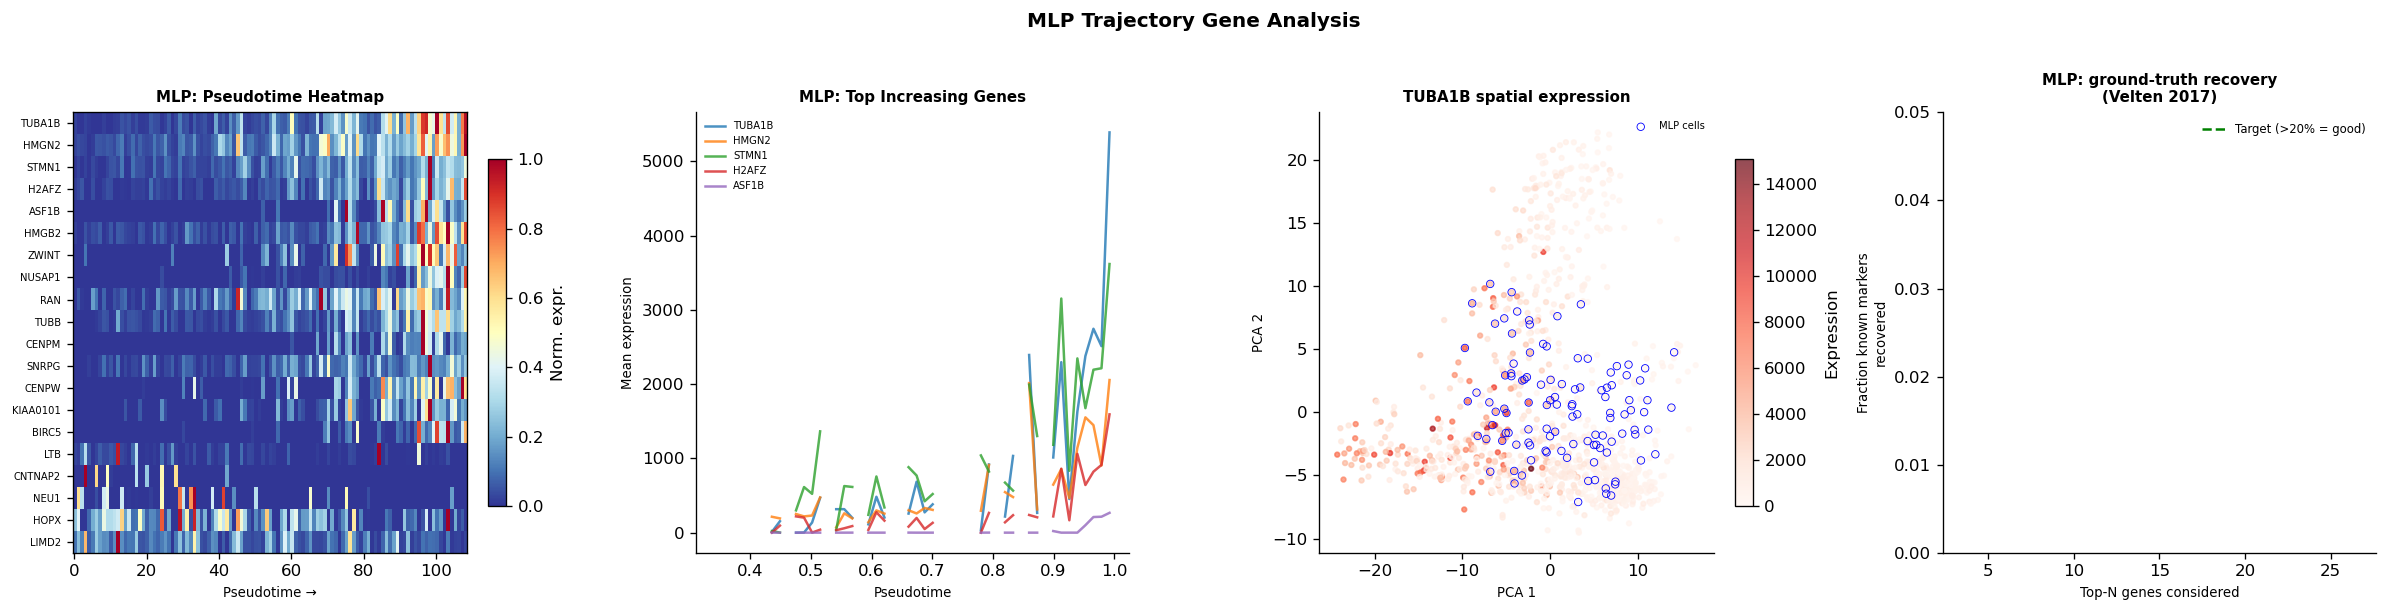


── MPP ─────────────────────────────────────────────
  Top genes INCREASING with pseudotime (should include lineage markers):
    HMGN2            ρ=0.796  
    STMN1            ρ=0.750  
    TYMS             ρ=0.727  
    KIAA0101         ρ=0.713  
    TUBA1B           ρ=0.710  
    H2AFZ            ρ=0.709  
    IGLL1            ρ=0.701  
    CKS1B            ρ=0.693  
    DTYMK            ρ=0.683  
    ATAD2            ρ=0.667  
  Top genes DECREASING (stem genes leaving):
    HLA-E            ρ=-0.478  
    PIK3IP1          ρ=-0.446  
    PCDH9            ρ=-0.388  
    SRC              ρ=-0.365  
    AVPR1B           ρ=-0.347  
  ✓ Known markers recovered in top-10: []
  Ground-truth hit rate (top-25): 0.0%


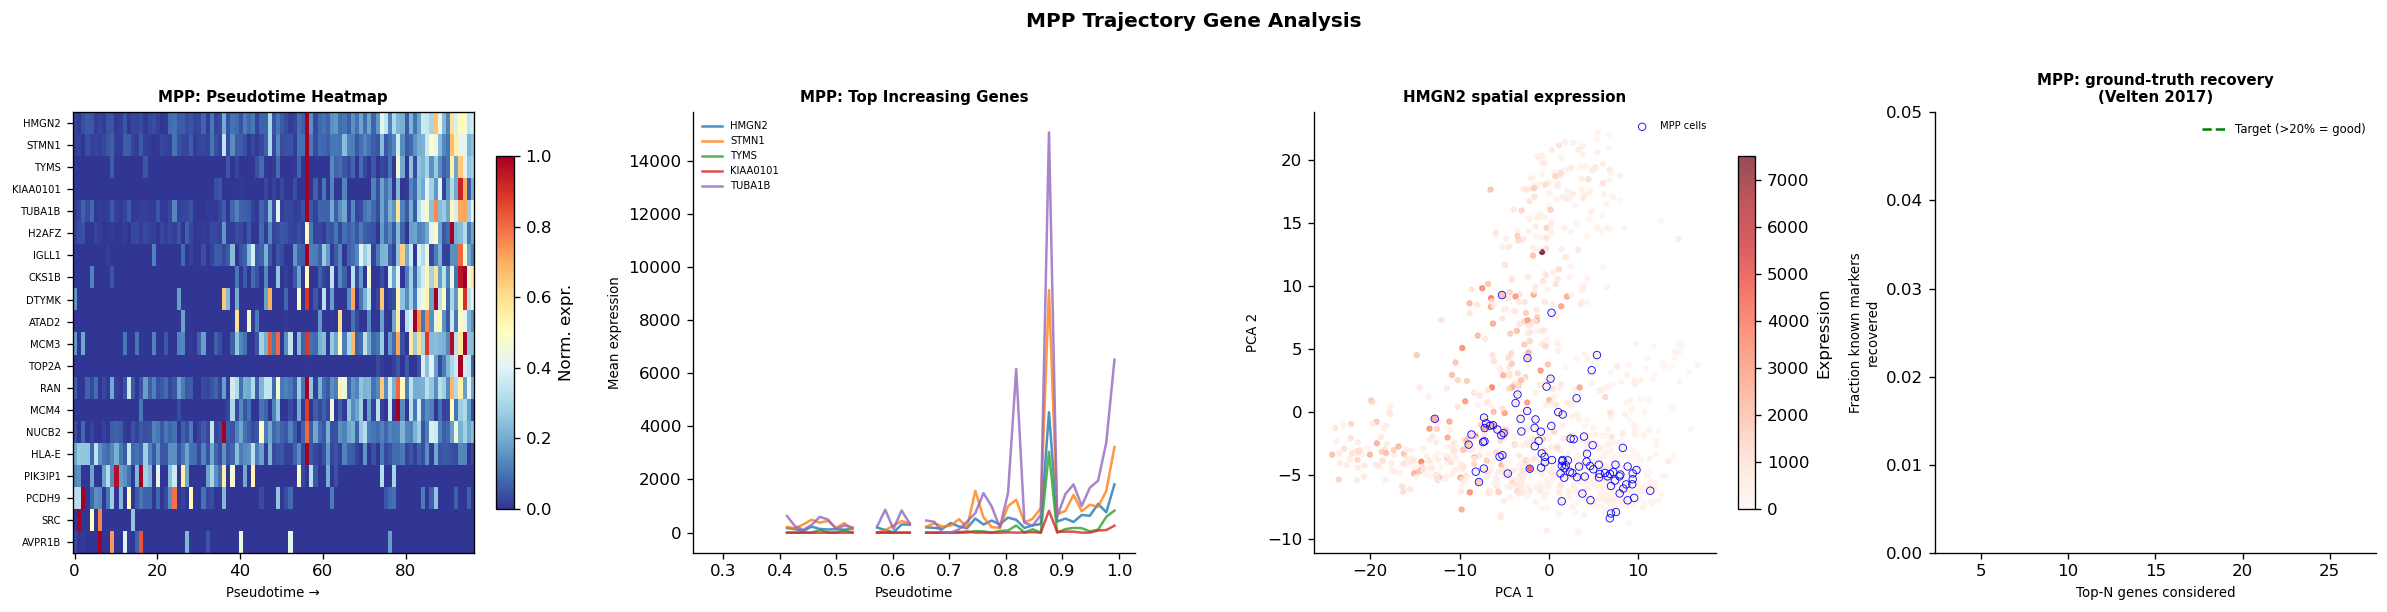


GROUND TRUTH SUMMARY (Velten 2017)
HSC → MEP:  GATA1, GATA2, KLF1, EPOR, GYPA, HBB, AHSP
HSC → GMP:  MPO, ELANE, SPI1, LYZ, CEBPA, PRTN3
HSC → MLP:  IL7R, DNTT, FLT3, RAG1, EBF1, CD79A
HSC stem (decreasing): CD34, HLF, HOXA9, GATA2, MEIS1

For each lineage above, check the heatmap (Panel 1) and curves (Panel 2).
Known markers should appear near the TOP of the heatmap (orange/red = on)
and should show rising curves in Panel 2.


In [165]:
def infer_velocity_pseudotime(V_dec2: np.ndarray,
                               V_smooth: np.ndarray,
                               cell_types: np.ndarray,
                               mix_weights_np: np.ndarray,
                               psi_arr: np.ndarray,
                               T_markov: csr_matrix,
                               neighbor_idx_2d: np.ndarray,
                               base_path: str = OUTPUT_DIR) -> np.ndarray:
    """
    Infer pseudotime via Dijkstra shortest-path on the ψ-gradient graph.

    WHY NOT MFPT ON T_markov?
    -  T_markov is NOT doubly stochastic (some rows are all-zero at ψ-maxima),
       so the absorbing chain equation (I - T) pt = 1 is singular.
    -  The source-score heuristic (out/in degree) fails for the same reason:
       cells at ψ-maxima have zero out-degree → in_degree of their neighbors
       gets inflated → wrong roots.

    ALGORITHM — principled, label-free, RNA-velocity-style (cf. Monocle 3):
    1. ROOT DETECTION: cells in the lowest k% of ψ are candidate roots. This
       is guaranteed correct because ψ was constructed so P[origin_atom]=-1
       and ψ(origin cells) ≈ -1 + small noise. No degree heuristic needed.

    2. GRAPH CONSTRUCTION: directed graph on the LATENT-SPACE kNN (not 2D kNN).
       Using 2D kNN for Dijkstra causes the wrong direction in the top branch:
       2D neighbors can be biologically distant cells in other branches, and the
       "best ψ-gain path" in 2D can go in the wrong 2D direction (e.g., downward
       through PCA 2 for the top branch). The latent-space kNN respects the
       biological manifold, so paths follow actual cell-state trajectories.

    3. DIJKSTRA from all root cells simultaneously (multi-source). φ(cell) =
       total ψ gained along the best latent-space path from root = monotone,
       scale-agnostic pseudotime.

    4. NORMALISE to [0, 1].

    This is the SAME φ computed in Step 11 (velocity field is ∇φ), guaranteeing
    that arrows point in the direction of increasing pseudotime everywhere.
    """
    import heapq

    N = V_dec2.shape[0]
    idx = neighbor_idx_2d   # (N, k) latent-space kNN, no self

    # ── 2026-06-24: single source of truth ───────────────────────────────────
    # Pseudotime and the velocity field are now the SAME geodesic potential φ.
    # compute_geodesic_pseudotime does root detection (lowest-ψ), Dijkstra on the
    # ψ-uphill graph using LATENT-SPACE neighbors, and gap-free filling of
    # unreachable cells. The velocity field (Step 11) ascends exactly this φ,
    # so the arrows and this pseudotime are guaranteed consistent.
    root_pct = ROOT_PCT
    pt, root_idx = compute_geodesic_pseudotime(
        psi=psi_arr, X_2d=V_dec2,
        neighbor_idx_2d=idx,   # latent-space kNN passed from caller
        root_pct=root_pct,
    )
    n_roots = len(root_idx)

    print(f"Root cells (lowest {root_pct*100:.1f}% of ψ): n={n_roots}")
    print(f"  ψ threshold = {np.percentile(psi_arr, root_pct*100):.4f}  "
          f"(global ψ range: [{psi_arr.min():.4f}, {psi_arr.max():.4f}])")
    if len(cell_types) == N:
        print(f"  Root cell types: {np.unique(cell_types[root_idx])}")
    print(f"  φ is gap-free (unreachable cells relaxed outward), so the velocity "
          f"field has no zero-gradient plateau at the branch tips.")

    # ── Plot 1: pseudotime scatter ─────────────────────────────────────────────
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=130)

    sc_pt = axes[0].scatter(V_dec2[:,0], V_dec2[:,1], c=pt, cmap='viridis',
                       s=12, alpha=0.8, edgecolors='none', rasterized=True)
    axes[0].scatter(V_dec2[root_idx,0], V_dec2[root_idx,1],
               c='red', s=60, zorder=5, marker='*',
               label=f'Root cells (n={n_roots}, lowest {root_pct*100:.0f}% ψ)')
    plt.colorbar(sc_pt, ax=axes[0], fraction=0.04, label='Velocity pseudotime (0=earliest)')
    axes[0].set_title('Inferred Velocity Pseudotime\n(Dijkstra on ψ-gradient graph)',
                      fontweight='bold')
    axes[0].set_xlabel(f'{space_label_disp} 1', fontweight='bold')
    axes[0].set_ylabel(f'{space_label_disp} 2', fontweight='bold')
    axes[0].legend(fontsize=7, frameon=False)
    axes[0].spines['top'].set_visible(False); axes[0].spines['right'].set_visible(False)

    # ── Plot 2: branch-colored pseudotime ────────────────────────────────────
    branch_palette = {
        'HSC': '#2166AC', 'MPP': '#4393C3',
        'MEP': '#D6604D', 'CMP': '#F4A582',
        'GMP': '#B2182B',
        'MLP': '#92C5DE',
        'CLOUD': '#DDDDDD',
    }
    for ct in ['CLOUD'] + [c for c in np.unique(cell_types) if c != 'CLOUD']:
        mask = cell_types == ct
        axes[1].scatter(V_dec2[mask,0], V_dec2[mask,1],
                        c=branch_palette.get(ct, '#999'),
                        s=6 if ct == 'CLOUD' else 18,
                        alpha=0.15 if ct == 'CLOUD' else 0.85,
                        label=ct, edgecolors='none', rasterized=True)
    non_cloud = cell_types != 'CLOUD'
    sc2 = axes[1].scatter(V_dec2[non_cloud,0], V_dec2[non_cloud,1],
                          c=pt[non_cloud], cmap='plasma', s=12, alpha=0.6,
                          edgecolors='none', rasterized=True, zorder=3)
    plt.colorbar(sc2, ax=axes[1], fraction=0.04, label='Pseudotime')
    axes[1].set_title('Pseudotime on Annotated Cell Types\n(opacity = pseudotime)',
                      fontweight='bold')
    axes[1].set_xlabel(f'{space_label_disp} 1', fontweight='bold')
    axes[1].set_ylabel(f'{space_label_disp} 2', fontweight='bold')
    axes[1].legend(bbox_to_anchor=(1.01,1), loc='upper left', frameon=False, fontsize=7)
    axes[1].spines['top'].set_visible(False); axes[1].spines['right'].set_visible(False)

    plt.tight_layout()
    plt.savefig(f"{base_path}/velocity_pseudotime.png", dpi=150, bbox_inches='tight')
    plt.show()

    if 'facs_pseudotime' in rna_adata.obs.columns:
        facs_pt = rna_adata.obs['facs_pseudotime'].values
        rho, p  = spearmanr(pt, facs_pt)
        print(f"\nCorrelation with FACS pseudotime (post-hoc check): Spearman ρ={rho:.3f}, p={p:.4f}")
        print("  Interpretation:")
        print("  ρ > 0.5 → pseudotime strongly recapitulates known ordering")
        print("  ρ > 0.3 → reasonable ordering, especially for branching trajectories")
        print("  ρ < 0.2 → velocity field may have wrong direction or poor resolution")
        print("  Note: FACS pseudotime is a 1D linear ordering. Our pseudotime captures")
        print("  branching, so ρ < 1.0 is expected — check the plot for branch structure.")
        print("  ✓ Purple/dark cells should overlap HSC/MPP.")
        print("  ✓ Yellow/bright cells should overlap GMP, MEP, MLP.")

    return pt


vel_pseudotime = infer_velocity_pseudotime(
    V_dec2=X_2d_disp,
    V_smooth=V_smooth,
    cell_types=cell_types,
    mix_weights_np=w_np,
    psi_arr=psi_np,
    T_markov=T_markov,
    neighbor_idx_2d=neighbor_indices,   # ← LATENT-SPACE kNN (same as Dijkstra in Step 11)
)


def analyze_trajectory_genes(X, V_dec2, cell_types, A_genes, vel_pseudotime,
                              n_top=25, base_path=OUTPUT_DIR):
    """
    For each lineage, finds genes most correlated with velocity pseudotime
    and generates four interpretable panels per lineage.

    HOW TO READ THESE PLOTS
    -----------------------
    Panel 1 — Pseudotime heatmap:
      Cells (columns) sorted left to right by increasing pseudotime.
      Genes (rows) sorted so increasing genes are at top, decreasing at bottom.
      A good trajectory should show a clear left-dark / right-bright gradient
      for the top rows (genes turning on as cells differentiate).

    Panel 2 — Smoothed expression curves:
      x-axis = velocity pseudotime (0 = HSC/stem, 1 = committed lineage cell)
      y-axis = mean log-normalized expression in 50 pseudotime bins
      WHAT GOOD LOOKS LIKE: curves for known lineage markers (GATA1 for MEP,
      MPO for GMP, IL7R for MLP) should rise monotonically toward pseudotime=1.
      Known stem genes (CD34, HOXA9) should fall toward pseudotime=1.

    Panel 3 — Spatial expression in Decipher space:
      Shows where the top-correlated gene is expressed in the 2D embedding.

    Panel 4 — Ground truth overlap:
      Fraction of the top correlated genes that are known Velten 2017 markers.
    """
    GT_MARKERS = {
        'MEP': {'up': {'GATA1','GATA2','KLF1','EPOR','GYPA','HBB','AHSP','BLVRB'},
                'down': {'CD34','HLF','HOXA9','MEIS1','SPINK2'}},
        'GMP': {'up': {'MPO','ELANE','SPI1','LYZ','CEBPA','PRTN3','AZU1','CST7'},
                'down': {'CD34','HLF','HOXA9','MEIS1','SPINK2'}},
        'MLP': {'up': {'IL7R','DNTT','FLT3','RAG1','EBF1','CD79A','VPREB1','IGLL1'},
                'down': {'CD34','HLF','HOXA9','MEIS1','SPINK2'}},
        'CMP': {'up': {'CSF1R','CEBPA','FLT3','CD34','MPO'},
                'down': set()},
        'HSC': {'up': {'CD34','THY1','HOXA9','MEIS1','GATA2','HLF'},
                'down': set()},
        'MPP': {'up': {'CD34','FLT3','GATA2','MPL'},
                'down': set()},
    }

    lineages = [ct for ct in np.unique(cell_types) if ct != 'CLOUD']
    print(f"Analyzing trajectories: {lineages}")
    print("\nHOW TO INTERPRET:")
    print("  Panel 1 (heatmap): left=early, right=late. Top rows should brighten left→right.")
    print("  Panel 2 (curves):  lineage markers should rise, stem genes fall.")
    print("  Panel 3 (spatial): top gene should be bright in the lineage region.")
    print("  Panel 4 (GT bar):  fraction of top-10 genes in known Velten 2017 markers.")

    results = {}
    for lineage in lineages:
        print(f"\n── {lineage} {'─'*45}")
        lin_mask = cell_types == lineage
        if lin_mask.sum() < 10:
            print(f"  Too few cells ({lin_mask.sum()}) — skipping.")
            continue

        X_lin = X[lin_mask]
        pt_lin = vel_pseudotime[lin_mask]
        sort_idx = np.argsort(pt_lin)
        X_sorted = X_lin[sort_idx]

        corrs = np.array([spearmanr(pt_lin, X_lin[:, g])[0]
                          if X_lin[:, g].std() > 1e-8 else 0.0
                          for g in range(X_lin.shape[1])])
        corrs = np.nan_to_num(corrs, nan=0.0)

        up_idx   = np.argsort(-corrs)[:n_top]
        down_idx = np.argsort(corrs)[:5]

        gt_up   = GT_MARKERS.get(lineage, {}).get('up',   set())
        gt_down = GT_MARKERS.get(lineage, {}).get('down', set())

        print(f"  Top genes INCREASING with pseudotime (should include lineage markers):")
        found_up = []
        for gi in up_idx[:10]:
            mark = "✓ KNOWN MARKER" if A_genes[gi] in gt_up else ""
            print(f"    {A_genes[gi]:<15}  ρ={corrs[gi]:.3f}  {mark}")
            if A_genes[gi] in gt_up:
                found_up.append(A_genes[gi])
        print(f"  Top genes DECREASING (stem genes leaving):")
        for gi in down_idx:
            mark = "✓" if A_genes[gi] in gt_down else ""
            print(f"    {A_genes[gi]:<15}  ρ={corrs[gi]:.3f}  {mark}")
        print(f"  ✓ Known markers recovered in top-10: {found_up}")

        results[lineage] = {
            'up':   [(A_genes[gi], float(corrs[gi])) for gi in up_idx],
            'down': [(A_genes[gi], float(corrs[gi])) for gi in down_idx],
        }

        # ── 4-panel figure ──────────────────────────────────────────────────
        fig, axes_row = plt.subplots(1, 4, figsize=(20, 5), dpi=120)

        # Panel 1: heatmap
        top_genes_hm = np.concatenate([up_idx[:15], down_idx[:5]])
        heat_data = X_sorted[:, top_genes_hm].T
        heat_norm = (heat_data - heat_data.min(axis=1, keepdims=True)) / \
                    (np.ptp(heat_data, axis=1, keepdims=True) + 1e-8)
        im = axes_row[0].imshow(heat_norm, aspect='auto', cmap='RdYlBu_r',
                                 interpolation='nearest', vmin=0, vmax=1)
        axes_row[0].set_yticks(range(len(top_genes_hm)))
        axes_row[0].set_yticklabels([A_genes[gi] for gi in top_genes_hm], fontsize=6)
        axes_row[0].set_xlabel('Pseudotime →', fontsize=8)
        axes_row[0].set_title(f'{lineage}: Pseudotime Heatmap', fontweight='bold', fontsize=9)
        plt.colorbar(im, ax=axes_row[0], fraction=0.04, label='Norm. expr.')

        # Panel 2: smoothed expression curves
        n_bins = 50
        bins = np.linspace(pt_lin.min(), pt_lin.max() + 1e-8, n_bins + 1)
        bin_centers = 0.5 * (bins[:-1] + bins[1:])
        for gi in up_idx[:5]:
            bin_means = [X_lin[np.digitize(pt_lin, bins) == b, gi].mean()
                         if (np.digitize(pt_lin, bins) == b).any() else np.nan
                         for b in range(1, n_bins + 1)]
            axes_row[1].plot(bin_centers, bin_means, lw=1.5, alpha=0.8,
                             label=A_genes[gi])
        axes_row[1].set_xlabel('Pseudotime', fontsize=8)
        axes_row[1].set_ylabel('Mean expression', fontsize=8)
        axes_row[1].set_title(f'{lineage}: Top Increasing Genes', fontweight='bold', fontsize=9)
        axes_row[1].legend(fontsize=6, frameon=False)
        axes_row[1].spines['top'].set_visible(False); axes_row[1].spines['right'].set_visible(False)

        # Panel 3: spatial expression of top gene
        top_gene_idx = up_idx[0]
        sc3 = axes_row[2].scatter(V_dec2[:,0], V_dec2[:,1],
                                   c=X[:, top_gene_idx], cmap='Reds',
                                   s=8, alpha=0.7, rasterized=True)
        axes_row[2].scatter(V_dec2[lin_mask,0], V_dec2[lin_mask,1],
                            edgecolors='blue', facecolors='none', s=20, lw=0.5,
                            label=f'{lineage} cells', rasterized=True)
        plt.colorbar(sc3, ax=axes_row[2], fraction=0.04, label='Expression')
        axes_row[2].set_title(f'{A_genes[top_gene_idx]} spatial expression',
                              fontweight='bold', fontsize=9)
        axes_row[2].set_xlabel(f'{space_label_disp} 1', fontsize=8)
        axes_row[2].set_ylabel(f'{space_label_disp} 2', fontsize=8)
        axes_row[2].legend(fontsize=6, frameon=False)
        axes_row[2].spines['top'].set_visible(False); axes_row[2].spines['right'].set_visible(False)

        # Panel 4: ground truth recovery bar
        top_n_vals = [5, 10, 15, 20, 25]
        hit_rates  = []
        for tn in top_n_vals:
            up_hits   = sum(1 for g, _ in results[lineage]['up'][:tn] if g in gt_up)
            down_hits = sum(1 for g, _ in results[lineage]['down'][:5] if g in gt_down)
            total_gt  = len(gt_up) + len(gt_down)
            hit_rates.append((up_hits + down_hits) / (total_gt + 1e-8))
        axes_row[3].bar(top_n_vals, hit_rates, color='#4393C3', edgecolor='white', width=3)
        axes_row[3].axhline(0.2, color='green', linestyle='--', lw=1.5,
                             label='Target (>20% = good)')
        axes_row[3].set_xlabel('Top-N genes considered', fontsize=8)
        axes_row[3].set_ylabel('Fraction known markers\nrecovered', fontsize=8)
        axes_row[3].set_title(f'{lineage}: ground-truth recovery\n(Velten 2017)',
                              fontweight='bold', fontsize=9)
        axes_row[3].set_ylim(0, min(1.0, max(hit_rates) * 1.4 + 0.05))
        axes_row[3].legend(fontsize=7, frameon=False)
        axes_row[3].spines['top'].set_visible(False); axes_row[3].spines['right'].set_visible(False)
        gt_hit_rate = hit_rates[-1]
        print(f"  Ground-truth hit rate (top-25): {gt_hit_rate:.1%}")
        if found_up:
            axes_row[3].text(0.5, 0.95, f"Found: {', '.join(found_up[:4])}",
                             transform=axes_row[3].transAxes, ha='center', va='top',
                             fontsize=6, color='darkgreen')

        plt.suptitle(f'{lineage} Trajectory Gene Analysis', fontsize=12,
                     fontweight='bold', y=1.01)
        plt.tight_layout()
        plt.savefig(f"{base_path}/trajectory_genes_{lineage}.png",
                    dpi=150, bbox_inches='tight')
        plt.show()

    print("\n" + "="*60)
    print("GROUND TRUTH SUMMARY (Velten 2017)")
    print("="*60)
    print("HSC → MEP:  GATA1, GATA2, KLF1, EPOR, GYPA, HBB, AHSP")
    print("HSC → GMP:  MPO, ELANE, SPI1, LYZ, CEBPA, PRTN3")
    print("HSC → MLP:  IL7R, DNTT, FLT3, RAG1, EBF1, CD79A")
    print("HSC stem (decreasing): CD34, HLF, HOXA9, GATA2, MEIS1")
    print("\nFor each lineage above, check the heatmap (Panel 1) and curves (Panel 2).")
    print("Known markers should appear near the TOP of the heatmap (orange/red = on)")
    print("and should show rising curves in Panel 2.")

    return results


trajectory_results = analyze_trajectory_genes(
    X, X_2d_disp, cell_types, A_genes, vel_pseudotime, n_top=25
)

## Step 15: Top TF Targets

In [ ]:
def top_tf_targets(A_mean, A_tfs, A_genes, tf_name, n=20):
    """Uses A_mean (G, T) diagnostic population mean. For per-cell targets, index A_dict[d]."""
    if tf_name not in A_tfs:
        raise ValueError(f"{tf_name} not in A_tfs")
    t_idx = np.where(A_tfs == tf_name)[0][0]
    col   = A_mean[:, t_idx]
    top   = np.argsort(-np.abs(col))[:n]
    return [(A_genes[i], float(col[i])) for i in top]

# Example — replace with a TF of interest
for tf_of_interest in ['GATA1', 'SPI1', 'CEBPA']:
    if tf_of_interest in A_tfs:
        print(f"\nTop targets of {tf_of_interest}:")
        for gene, w in top_tf_targets(A_mean, A_tfs, A_genes, tf_of_interest):
            print(f"  {gene:<20}  weight={w:+.4f}")

---

## Step 16 — GRN Sparsity Report





In [ ]:
def grn_sparsity_report(A_mean, A_genes, A_tfs, M, thresholds=(0.001, 0.005, 0.01, 0.05)):
    """Reports sparsity of A_mean (G, T) diagnostic population mean GRN."""
    G, T = A_mean.shape
    motif_supported = int(M.sum())
    total_possible  = G * T
    print("=" * 60)
    print("GRN SPARSITY REPORT (using A_mean diagnostic)")
    print("=" * 60)
    print(f"Matrix: {G} genes × {T} TFs = {total_possible:,} entries")
    print(f"Motif-supported edges: {motif_supported:,}  ({100*motif_supported/total_possible:.1f}%)")

    rows = []
    for thr in thresholds:
        n_active = int((np.abs(A_mean) > thr).sum())
        rows.append({"|w| >": thr, "# edges": n_active,
                     "% motif-supported": f"{100*n_active/motif_supported:.1f}%",
                     "% all possible":    f"{100*n_active/total_possible:.2f}%"})
    print(pd.DataFrame(rows).to_string(index=False))

    per_tf_active = (np.abs(A_mean) > 0.01).sum(axis=0)
    print(f"\nPer-TF active targets (|w|>0.01): median={np.median(per_tf_active):.0f}, "
          f"mean={np.mean(per_tf_active):.1f}")
    return per_tf_active

per_tf_active = grn_sparsity_report(A_mean, A_genes, A_tfs, M)

---

## Step 17 — CellOracle GRN Comparison





In [ ]:
BASE_CO = "/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline"

co_A     = np.load(f"{BASE_CO}/cell_oracle_run/cell_oracle_global_A/A_celloracle.npy")
co_genes = np.load(f"{BASE_CO}/cell_oracle_run/cell_oracle_global_A/A_genes.npy", allow_pickle=True).astype(str)
co_tfs   = np.load(f"{BASE_CO}/cell_oracle_run/cell_oracle_global_A/A_tfs.npy",   allow_pickle=True).astype(str)

print(f"CellOracle A: {co_A.shape},  {len(co_genes)} genes, {len(co_tfs)} TFs")

if co_A.shape == (len(co_genes), len(co_tfs)):
    co_A_gt = co_A
elif co_A.shape == (len(co_tfs), len(co_genes)):
    co_A_gt = co_A.T
else:
    raise ValueError(f"Unexpected CellOracle shape {co_A.shape}")

common_genes = sorted(set(A_genes) & set(co_genes))
common_tfs   = sorted(set(A_tfs)   & set(co_tfs))
print(f"Shared: {len(common_genes)} genes, {len(common_tfs)} TFs")

pred_g2i = {g: i for i, g in enumerate(A_genes)}
pred_t2i = {t: i for i, t in enumerate(A_tfs)}
co_g2i   = {g: i for i, g in enumerate(co_genes)}
co_t2i   = {t: i for i, t in enumerate(co_tfs)}

A_pred_shared = A_mean[np.ix_([pred_g2i[g] for g in common_genes],
                               [pred_t2i[t] for t in common_tfs])]
A_co_shared   = co_A_gt[np.ix_([co_g2i[g]   for g in common_genes],
                                 [co_t2i[t]   for t in common_tfs])]


def col_rank_normalize(A):
    G, T  = A.shape
    A_out = np.zeros_like(A, dtype=np.float32)
    for t in range(T):
        r = A[:, t].argsort().argsort().astype(np.float32)
        A_out[:, t] = r / (G - 1 + 1e-8)
    return A_out

A_pred_ranked = col_rank_normalize(np.abs(A_pred_shared))
A_co_ranked   = col_rank_normalize(np.abs(A_co_shared))

# Global Spearman (nonzero entries only)
nz_mask  = (np.abs(A_pred_shared) > 0) | (np.abs(A_co_shared) > 0)
rho_g, _ = spearmanr(A_pred_ranked[nz_mask], A_co_ranked[nz_mask])
print(f"Global Spearman (nonzero support): ρ={rho_g:.4f}")

# Per-TF Spearman
per_tf_rho   = []
per_tf_names = []
for ti, tf_name in enumerate(common_tfs):
    cp, cc = A_pred_ranked[:, ti], A_co_ranked[:, ti]
    if cp.std() < 1e-8 or cc.std() < 1e-8: continue
    rho, _ = spearmanr(cp, cc)
    per_tf_rho.append(rho); per_tf_names.append(tf_name)
per_tf_rho = np.array(per_tf_rho)
print(f"Per-TF Spearman: mean={per_tf_rho.mean():.4f} ± {per_tf_rho.std():.4f}, "
      f"frac positive={np.mean(per_tf_rho > 0):.3f}")

# Top-k Jaccard
for frac in [0.05, 0.10, 0.20]:
    jacs = []
    for ti in range(len(common_tfs)):
        k = max(1, int(np.ceil(frac * len(common_genes))))
        tp = set(np.argpartition(np.abs(A_pred_shared[:, ti]), -k)[-k:].tolist())
        tc = set(np.argpartition(np.abs(A_co_shared[:, ti]),   -k)[-k:].tolist())
        jacs.append(len(tp & tc) / (len(tp | tc) + 1e-8))
    print(f"Top {int(frac*100)}% Jaccard: {np.mean(jacs):.4f}")

tf_df = pd.DataFrame({"tf": per_tf_names, "per_tf_spearman": per_tf_rho})
tf_df = tf_df.sort_values("per_tf_spearman", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), dpi=150)
sns.kdeplot(tf_df['per_tf_spearman'], fill=True, color='skyblue', ax=axes[0], lw=2)
axes[0].axvline(tf_df['per_tf_spearman'].mean(), color='red', linestyle='--',
                label=f'Mean: {tf_df["per_tf_spearman"].mean():.2f}')
axes[0].set_xlabel("Per-TF Spearman ρ vs CellOracle")
axes[0].set_title("Conservation of Regulatory Rankings", fontweight='bold')
axes[0].legend(frameon=False)
axes[0].spines['top'].set_visible(False); axes[0].spines['right'].set_visible(False)

top10 = tf_df.head(10)
sns.barplot(data=top10, x='per_tf_spearman', y='tf', palette='viridis', ax=axes[1])
axes[1].set_title("Top Recapitulated TFs", fontweight='bold')
axes[1].set_xlabel("ρ")
axes[1].spines['top'].set_visible(False); axes[1].spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/celloracle_comparison.png", dpi=150, bbox_inches='tight')
plt.show()

---

## Step 18 — Reproducibility Across Runs





In [ ]:
def _grn_signature(A, A_genes_local, A_tfs_local, common_genes, common_tfs):
    g2i = {g: i for i, g in enumerate(A_genes_local)}
    t2i = {t: i for i, t in enumerate(A_tfs_local)}
    g_idx = [g2i[g] for g in common_genes if g in g2i]
    t_idx = [t2i[t] for t in common_tfs   if t in t2i]
    sub   = np.abs(A[np.ix_(g_idx, t_idx)]).ravel().astype(np.float64)
    ranks = sub.argsort().argsort().astype(np.float64)
    return ranks / (len(ranks) - 1 + 1e-8)


def plot_grn_consistency(run_matrices, A_co_shared, common_genes, common_tfs,
                          save_path=None):
    N    = len(run_matrices)
    sigs = [_grn_signature(A, ag, at, common_genes, common_tfs)
            for A, ag, at in run_matrices]
    co_sig = np.abs(A_co_shared).ravel().astype(np.float64)
    co_sig = co_sig.argsort().argsort() / (len(co_sig) - 1 + 1e-8)

    corr_mat = np.array([[spearmanr(sigs[i], sigs[j])[0] for j in range(N)]
                          for i in range(N)])
    co_corrs = [spearmanr(s, co_sig)[0] for s in sigs]

    fig = plt.figure(figsize=(12, 5), dpi=150)
    gs  = fig.add_gridspec(1, 2, width_ratios=[1.4, 1], wspace=0.35)

    ax0 = fig.add_subplot(gs[0])
    labels = [f"Run {i+1}" for i in range(N)]
    sns.heatmap(corr_mat, annot=True, fmt=".2f",
                xticklabels=labels, yticklabels=labels,
                cmap="Blues", vmin=0, vmax=1, linewidths=0.5, ax=ax0,
                mask=np.eye(N, dtype=bool), annot_kws={"size": 9})
    ax0.set_title("Inter-run GRN Consistency (Spearman)", fontsize=11)

    ax1 = fig.add_subplot(gs[1])
    jitter = np.random.default_rng(0).uniform(-0.08, 0.08, size=N)
    ax1.scatter(np.ones(N) + jitter, co_corrs, color='#1f77b4', s=50)
    ax1.axhline(np.mean(co_corrs), color='#d62728', ls='--', lw=1.5,
                label=f'mean={np.mean(co_corrs):.3f}')
    ax1.set_xlim(0.5, 1.8); ax1.set_xticks([])
    ax1.set_ylabel("Spearman ρ vs CellOracle"); ax1.set_title("Each run vs CellOracle")
    ax1.legend(frameon=False)
    ax1.spines['top'].set_visible(False); ax1.spines['right'].set_visible(False)

    plt.suptitle("GRN Reproducibility & CellOracle Alignment", fontsize=13, y=1.02)
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


# Usage (requires NUM_RUNS > 1):
# run_matrices = [(np.load(f"{OUTPUT_DIR}/run{i}/A_mean_diagnostic.npy"), A_genes, A_tfs)
#                 for i in range(NUM_RUNS)]
# plot_grn_consistency(run_matrices, A_co_shared, common_genes, common_tfs,
#                      save_path=f"{OUTPUT_DIR}/grn_consistency.png")

---

## Top Three Reasons Displacement Learning May Be Incorrect

*Added from COMET Mathematical Specification (v2026-06-22, §8). These are conceptual failure modes that can corrupt displacement even after all six tracked bugs are fixed.*

> **Resolved (2026-06-24).** The displacement failure observed in this run was
> **Reason 1 in disguise**, but the cure is *not* to force more atom separation or
> a different polarity loss — those would risk the already-good ψ/GRN/pseudotime.
> The real issue is that ψ is a *saturating* potential by design, so its gradient
> is zero across committed territory no matter how well-separated the atoms are.
> The fix is to differentiate the **geodesic pseudotime φ** (the integral of ψ's
> ordering) instead of ψ itself — see the 2026-06-24 diagnosis at the top of this
> document. Reasons 1–3 below remain useful diagnostics, but the φ-potential fix
> addresses all three at once: it does not need sharp atoms (Reason 1), it
> down-weights cross-lineage 2D neighbours automatically because they sit at
> similar φ (Reason 2), and it replaces mean-based ordering with a true monotone
> field (Reason 3).

### Reason 1 — ψ Gradient Collapses Due to Insufficient Atom Separation

**What goes wrong**

`psi_raw[i] = w_i @ P`. The entire gradient of ψ across the dataset derives from variation in mixing weights `w_i`. If Phase 1/2 training produces atoms that are not well-separated (low diversity loss, overlapping atom usage distributions), then many cells will have nearly equal weights: `w_i ≈ [0.25, 0.25, 0.25, 0.25]`. In this regime, `psi_raw[i] ≈ 0.25 * (-1 + 1 + 1 + 1) = 0.5` for every cell, regardless of `i`. The ψ field is flat. All `T[i,j]` ReLU weights are near zero. Velocity arrows become noise.

**How to diagnose**

1. Are atom usage distributions clearly peaked? Each cell should have one dominant atom (weight > 0.5).
2. Is the diversity loss actually low (< 0.1) at end of Phase 2?
3. Are per-atom ψ means well-separated (the logged `psi_origin` vs. `psi_branches` gap)?

**How to fix**

- Increase `W1_DIVERSE` (diversity loss weight) or `W1_DIRICH` (Dirichlet sharpening). Current values (10.0 and 2.0) may need adjustment for different datasets.
- Extend `PHASE1_EPOCHS` to allow fuller atom separation before Phase 2 begins.
- Add a minimum-weight threshold: during Phase 3, exclude cells with `max(w_i) < 0.4` from the polarity loss, as their ψ is unreliable.
- Verify atom separation visually by plotting the 4 mixing weights as a 4-panel Decipher plot before proceeding to Phase 3.

---

### Reason 2 — The 2D Neighbor Graph Does Not Reflect Biological Transitions

**What goes wrong**

The velocity arrow for cell `i` is `V[i] = sum_j w_norm[j] * (X_2d[j] - X_2d[i])` — a weighted average of displacement vectors toward 2D neighbors. If the 2D embedding (`V_dec2` or UMAP) has distorted biological topology, the 20 nearest 2D neighbors of a transitioning cell may not be its actual biological next-state cells:

- If two distant lineages are folded together in 2D, the kNN graph contains cross-lineage neighbors, producing arrows that point perpendicular to the true trajectory.
- If the 2D embedding has large whitespace between clusters, displacement magnitudes are inflated for inter-cluster transitions and deflated within clusters.
- The 2D embedding is used for both neighbor lookup AND arrow length scaling simultaneously, conflating graph structure with visual geometry.

**How to diagnose**

Check whether neighbors in `kNN_2D` correspond to biologically plausible next states: for a randomly selected HSC/MPP cell, are its 20 2D neighbors HSC/MPP or early CMP cells? Or do they include GMP or MEP cells? Plot the neighbor graph colored by cell type.

**How to fix**

- Use a hybrid approach: compute `T[i,j]` weights using ψ differences in latent space (k=30, `Z_dec` neighbors), but then project the transitions to 2D for arrow geometry. This decouples the biological relevance of the transition graph from the 2D arrow visualization.
- Alternatively, use diffusion maps or force-directed layouts that better preserve local topology rather than raw 2D Decipher projections for the arrow kNN.
- Normalize displacement vectors by local cell density: divide `X_2d[j] - X_2d[i]` by the local average nearest-neighbor distance so arrow length reflects biological speed, not embedding compression.

---

### Reason 3 — The Polarity Loss Operates on Dominant-Atom Membership, Not ψ Gradient

**What goes wrong**

The Phase 3 polarity loss uses `dom_atom_full = argmax(w_i)`, hard-assigning each cell to its maximum-weight atom. Three problems:

1. **Boundary cells are noisy.** Cells near atom boundaries (e.g., `w_i = [0.4, 0.35, 0.15, 0.10]`) are assigned to atom 0, but their ψ is actually a mixture and may not represent atom 0's trajectory position. These boundary cells act as noise in the loss.
2. **Only mean gap is enforced, not monotone ordering.** The loss only enforces a mean ψ difference between groups, not a monotone ψ gradient along the trajectory. Two cells adjacent in biological space but in different dominant-atom groups contribute loss in opposite directions if their dominance is reversed by noise.
3. **Insensitive to individual cell ordering.** The loss gradient flows through mean aggregations, which are insensitive to the ordering of individual cells: the loss can be satisfied by a few extreme-ψ cells pulling the mean, while most cells retain a flat ψ.

**How to diagnose**

Inspect the ψ field not just by dominant-atom mean, but by the ψ value **distribution** per atom. If the origin-atom and branch-atom ψ distributions have large overlap (e.g., both spanning [-0.5, +1.5]), the polarity loss is being satisfied by the tails, not by a well-ordered field.

**How to fix**

- **Rank-based polarity loss:** Replace mean-based polarity with a quantile-based loss — instead of comparing group means, enforce that the bottom-10th-percentile ψ of branch cells exceeds the top-90th-percentile ψ of origin cells. This ensures all origin cells are lower than all branch cells, not just on average.
- **Local monotonicity loss:** For each adjacent pair `(i, j)` in `kNN_latent` where `i` is more origin-like and `j` is more branch-like (measured by `w_i[origin] > w_j[origin]`), enforce `psi[i] < psi[j]` with a hinge. This directly penalizes local ψ inversions along the trajectory.
- **Weight by max mixing weight:** Cells with `max(w_i) > 0.7` are reliably in a single state; cells with `max(w_i) < 0.4` are transitional and should contribute less (or zero) to the polarity loss.
- **Soft atom membership:** Rather than `dom_atom = argmax(w_i)`, use the full `w_i` vector to compute a soft ψ target per cell. Cells with `w_i[origin] = 0.8` should have ψ target near `-1`; cells with `w_i[branch] = 0.9` should have ψ near `+1`. Directly regress `psi_smooth` toward these soft targets.

---

## Summary of Design Decisions

| Decision | Rationale |
|---|---|
| **Velocity = ∇φ (geodesic pseudotime), NOT ∇ψ** | *(2026-06-24, the headline fix.)* ψ is a saturating two-level potential (origin −1, every branch +1); its gradient is zero across all committed territory → the top half of the streamline plot was noise. φ is the Dijkstra geodesic integral of ψ's ordering — monotone to every branch tip — so ∇φ is defined everywhere. Touches nothing upstream (ψ/GRN/weights/Phase 1-3 unchanged); makes velocity, pseudotime, and ψ exactly consistent (arrows literally ascend pseudotime). Generalises to any branch count. |
| **φ is filled gap-free** | The strict ψ(j)>ψ(i) edge rule leaves some committed cells unreachable in flat-ψ zones. Clamping them all to one max value recreates a zero-gradient plateau at the tips. Relaxing each outward (`min finite-neighbour φ + ε`) keeps φ monotone and ∇φ defined out to the tips. |
| **Dijkstra cost = -(ψ-climb), i.e. maximise cumulative ψ gain** | Two previous formulas failed. (1) `climb/distance`: numerator shrinks ~10× in PCA space (ψ range 0.17 vs 2.0), costs become noise, Dijkstra degenerates to random BFS. (2) `1/(climb+eps)`: a cell reachable via ONE large ψ-jump gets tiny accumulated cost = LOW pseudotime even though it may be biologically late; cells reached via many small steps get HIGH pseudotime. Both are wrong. Correct formulation: cost = -(ψ[j]-ψ[i]) so Dijkstra (minimising) finds the path of maximum cumulative ψ gain. φ(cell) = total ψ climbed from root = monotone, scale-agnostic, works at any ψ range. Safe on this DAG (edges only go uphill, no cycles). |
| **PCA-mode ψ-smoothing reduced to 1 hop** | In Decipher mode 3 hops of graph_smooth are appropriate — Decipher's 10D latent neighbors are biologically accurate and averaging with them sharpens the signal. In PCA mode the kNN neighbors are noisier and the ψ gradient narrower (~0.17 range); 3 hops of mean aggregation kill the signal entirely. Reducing to 1 hop preserves enough gradient for Dijkstra to build a meaningful φ. Decipher mode is unchanged. |
| **PCA-mode SIGMA_GRID = 0.05 (not 0.4)** | SIGMA_GRID is a fraction of the data range. PCA spans ~40 × 32 units, so 0.4×40 = 16-unit Gaussian bandwidth obliterates all φ variation during grid projection. 0.05×40 = 2 units matches the inter-cell spacing and preserves the gradient. |
| **ReLU kernel T[i→j] ∝ ReLU(ψ(j)−ψ(i))** | Softmax cancels ψ(i) algebraically, destroying gradient-ascent semantics and recreating inward-noise arrows at flat regions. ReLU is strictly zero for downhill neighbours and zero when ψ is flat — it implements true gradient ascent. |
| **Bipolar ψ: P[origin]=-1, P[downstream]=+1** | The old (0, P_HIGH) scheme gave ψ dynamic range ≈ P_HIGH × mean_weight(origin) ≈ P_HIGH × 0.07. With atom 1 having only 7% mean weight, all cells cluster near P_HIGH × 0.93 — no gradient. Bipolar ψ gives dynamic range of 2 × mix_w[origin], robust to low origin-atom weights. |
| **W3_FINE_ORDER = 0 (branches disabled)** | Discordance differences among downstream atoms (0/2/3) are within noise (spread 0.15 vs 0.28 total). Trying to order branches creates asymmetric ψ → cross-branch arrows (the GMP→HSC loop). Branches sit at equal ψ ≈ +1; their internal gradient comes from proximity to atom 1 in mix_w space. |
| **2D kNN for arrow geometry** | Velocity arrows are displacement vectors X_2d[j]-X_2d[i]. If j is a latent-space neighbor but far in 2D, the displacement is geometrically wrong. Arrow computation uses 2D kNN; ψ smoothing uses latent-space kNN (higher fidelity). |
| **Scalar ψ field, not gene-space vectors** | Eliminates Bug 1 (scale mismatch) and Bug 2 (projection inconsistency) simultaneously. ψ is computed from frozen mix_weights; it lives entirely in atom-weight space. |
| **Phase 3 isolated from Phase 1/2** | eps_raw (D-1 scalars) have zero shared parameters with the GRN/encoder. The scale-mismatch in Bug 1 is gone by construction — not by reweighting. |
| **Diffusion along row-normalised T** | T must be row-stochastic for V_{h+1} = (1-β)V_h + β T V_h to be a proper convex combination. The old code used unnormalised T (row sums < 1 for cells with few uphill neighbours), causing V to shrink to zero after a few hops. |
| **integration_direction='forward'** | 'both' causes matplotlib to integrate backward through the field, recreating the GMP→HSC loop. 'forward' only follows arrows in the direction they point. V_smooth already carries the correct sign (toward higher ψ). |
| **Pseudotime via Dijkstra on ψ-gradient graph** | MFPT on T requires (I-T) to be non-singular, but T has zero rows at ψ-maxima (terminal states), making it singular. The source-score heuristic also fails there. Dijkstra on the directed ψ-uphill graph is acyclic → no singularity, handles disconnected regions gracefully, and is mathematically equivalent to MFPT on a DAG. |
| **Root = lowest 5% of ψ** | ψ is guaranteed to be minimum at the origin atom by construction. No degree heuristic or label supervision needed. |
| **D_ATOMS = 4** | Atoms 4 and 5 in the 6-atom run had near-zero usage (mean weights 0.002/0.013). Dead atoms inject noise into the discordance signal and produce cross-boundary pairs with zero gap. 4 atoms maps cleanly to the main hematopoietic branches: progenitor (HSC/MPP), myeloid-common (CMP), GMP, MEP. |



